In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import joblib
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import RFE
from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import chi2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.naive_bayes import GaussianNB
from yellowbrick.target import ClassBalance
from yellowbrick.style import set_palette
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import cross_validate, RepeatedStratifiedKFold, GridSearchCV
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import precision_recall_curve, auc
from imblearn.over_sampling import SMOTEN
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# statistic tools
import statsmodels.api as sm
import scipy.stats as st
from scipy.stats import shapiro, mannwhitneyu, chi2_contingency

# manipulating tools
from dateutil.relativedelta import relativedelta

In [ ]:
#Inisialisasi Data Utama [Modif karena Sistem Eror]
loan_data = '/content/drive/MyDrive/IDX_DataScience/loan_data_2007_2014.csv'
df = pd.read_csv(loan_data, engine='python', on_bad_lines='warn')
display(df.head())

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**DATA EXPLORING**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   445277 non-null  object 
 13 

In [ ]:
df.isna().sum()
pd.set_option('display.max_rows', None)
print(df.isna().sum())

Unnamed: 0                          0
id                                  0
member_id                           0
loan_amnt                           0
funded_amnt                         0
funded_amnt_inv                     0
term                                0
int_rate                            0
installment                         0
grade                               0
sub_grade                           0
emp_title                       27588
emp_length                      21008
home_ownership                      0
annual_inc                          4
verification_status                 0
issue_d                             0
loan_status                         0
pymnt_plan                          0
url                                 0
desc                           340304
purpose                             0
title                              21
zip_code                            0
addr_state                          0
dti                                 0
delinq_2yrs 

In [ ]:
for column in df.columns:
    print(f"Unique values in {column}:")
    print(df[column].unique())

Unique values in Unnamed: 0:
[     0      1      2 ... 466282 466283 466284]
Unique values in id:
[1077501 1077430 1077175 ... 9584776 9604874 9199665]
Unique values in member_id:
[ 1296599  1314167  1313524 ... 11436914 11457002 11061576]
Unique values in loan_amnt:
[ 5000  2500  2400 ... 33675 27775 33175]
Unique values in funded_amnt:
[ 5000  2500  2400 ... 27775 33175 31725]
Unique values in funded_amnt_inv:
[ 4975.  2500.  2400. ... 30425. 33125. 33625.]
Unique values in term:
[' 36 months' ' 60 months']
Unique values in int_rate:
[10.65 15.27 15.96 13.49 12.69  7.9  18.64 21.28 14.65  9.91 16.29  6.03
 11.71 12.42 14.27 16.77  7.51  8.9  18.25  6.62 19.91 17.27 17.58 21.67
 19.42 22.06 20.89 20.3  23.91 19.03 23.52 23.13 22.74 22.35 24.11  6.
 22.11  7.49 11.99  5.99 10.99  9.99 18.79 11.49  8.49 15.99 16.49  6.99
 12.99 15.23 14.79  5.42 10.59 17.49 15.62 21.36 19.29 13.99 18.39 16.89
 17.99 20.62 20.99 22.85 19.69 20.25 23.22 21.74 22.48 23.59 12.62 18.07
 11.63  7.91  7.42 11.

In [ ]:
duplicate = df.duplicated().sum()
print(duplicate)

0


In [ ]:
#Membedakan kolom sebagai angka, kategoi, dan tanggal
num = ['Unnamed: 0', 'id', 'member_id', 'loan_amnt','funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m']

cat =['term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'initial_list_status', 'application_type']

date = ['issue_d', 'earliest_cr_line','last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d']

In [ ]:
df[num].describe()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
count,466285.000000,4.662850e+05,4.662850e+05,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,4.662810e+05,466285.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,3.960090e+05,0.0,0.0,0.0
mean,233142.000000,1.307973e+07,1.459766e+07,14317.277577,14291.801044,14222.329888,13.829236,432.061201,7.327738e+04,17.218758,...,NaN,NaN,NaN,NaN,NaN,NaN,3.037909e+04,NaN,NaN,NaN
std,134605.029472,1.089371e+07,1.168237e+07,8286.509164,8274.371300,8297.637788,4.357587,243.485550,5.496357e+04,7.851121,...,NaN,NaN,NaN,NaN,NaN,NaN,3.724713e+04,NaN,NaN,NaN
min,0.000000,5.473400e+04,7.047300e+04,500.000000,500.000000,0.000000,5.420000,15.670000,1.896000e+03,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,NaN
25%,116571.000000,3.639987e+06,4.379705e+06,8000.000000,8000.000000,8000.000000,10.990000,256.690000,4.500000e+04,11.360000,...,NaN,NaN,NaN,NaN,NaN,NaN,1.350000e+04,NaN,NaN,NaN
50%,233142.000000,1.010790e+07,1.194108e+07,12000.000000,12000.000000,12000.000000,13.660000,379.890000,6.300000e+04,16.870000,...,NaN,NaN,NaN,NaN,NaN,NaN,2.280000e+04,NaN,NaN,NaN
75%,349713.000000,2.073121e+07,2.300154e+07,20000.000000,20000.000000,19950.000000,16.490000,566.580000,8.896000e+04,22.780000,...,NaN,NaN,NaN,NaN,NaN,NaN,3.790000e+04,NaN,NaN,NaN
max,466284.000000,3.809811e+07,4.086083e+07,35000.000000,35000.000000,35000.000000,26.060000,1409.990000,7.500000e+06,39.990000,...,NaN,NaN,NaN,NaN,NaN,NaN,9.999999e+06,NaN,NaN,NaN


In [ ]:
df[cat].describe()

,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,initial_list_status,application_type
count,466285,466285,466285,438697,445277,466285,466285,466285,466285,466285,125981,466285,466264,466285,466285,466285,466285
unique,2,7,35,205475,11,6,3,9,2,466285,124435,14,63098,888,50,2,1
top,36 months,B,B3,Teacher,10+ years,MORTGAGE,Verified,Current,n,https://www.lendingclub.com/browse/loanDetail....,,debt_consolidation,Debt consolidation,945xx,CA,f,INDIVIDUAL
freq,337953,136929,31686,5399,150049,235875,168055,224226,466276,1,234,274195,164075,5304,71450,303005,466285


In [ ]:
df[date].describe()

,issue_d,earliest_cr_line,last_pymnt_d,next_pymnt_d,last_credit_pull_d
count,466285,466256,465909,239071,466243
unique,91,664,98,100,103
top,Oct-14,Oct-00,Jan-16,Feb-16,Jan-16
freq,38782,3674,179620,208393,327699


**Feature Engineering**

Prapemrosesan Data: Kita perlu menghapus kolom yang memiliki > 70% nilai yang hilang.

Fitur berikut adalah pengidentifikasi dan tidak dapat digunakan dalam membangun model. id, id anggota, url, judul, desc, kode pos dan emp_title

Kolom sub_grade juga akan dihilangkan karena berisi informasi yang sama dengan kolom nilai.

Fitur yang berisi informasi tentang masa depan tidak akan disertakan dalam pembuatan model karena peristiwa tersebut belum terjadi. Fitur-fiturnya termasuk next_pymnt_d, recovery, collection_recovery_fee, total_rec_prncp dan total_rec_late_fee

In [ ]:
df['loan_bad'] = np.where(df.loc[:, 'loan_status'].isin(['Charged Off', 'Default', 'Late (31-120 days)',
                                        'Does not meet the credit policy. Status:Charged Off']), 0, 1)
# Drop the original 'loan_status' column
df.drop(columns = ['loan_status'], inplace = True)
df.drop('Unnamed: 0', inplace=True, axis=1)

Charged Off: Mengindikasikan pinjaman telah gagal bayar dan dianggap tidak akan dilunasi oleh peminjam.

Default: Secara langsung menunjukkan kegagalan pembayaran dalam jangka waktu tertentu dan dianggap tidak akan diselesaikan.

Late (31-120 days): Pinjaman dengan keterlambatan pembayaran lebih dari 30 hari, dianggap berisiko tinggi untuk gagal bayar.

Late (16-30 days): Walaupun keterlambatan lebih pendek, ini tetap menjadi indikator risiko kegagalan pembayaran jika tidak ditangani.

Does not meet the credit policy. Status: Charged Off: Mengacu pada pinjaman yang gagal bayar sekaligus tidak memenuhi kebijakan kredit, semakin mempertegas statusnya sebagai pinjaman buruk.

Bukan Bad Loan:

Fully Paid: Pinjaman telah lunas, tidak termasuk kategori gagal bayar.
Current: Pinjaman masih dalam pembayaran sesuai jadwal.
In Grace Period: Pembayaran tertunda tetapi masih dalam periode tenggang yang diizinkan. Does not meet the credit policy. Status: Fully Paid: Meskipun tidak sesuai kebijakan kredit, pinjaman telah dilunasi, sehingga bukan kategori gagal bayar.

Kesimpulan: Pinjaman yang tergolong bad loan: Charged Off, Default, Late (31-120 days), Late (16-30 days), dan Does not meet the credit policy. Status: Charged Off. Kategori ini menunjukkan risiko tinggi atau sudah gagal bayar.

Jenis tersebut akan diubah menjadi angka 1 atau 0:

good = 0 bad = 1

In [ ]:
# Hitung jumlah masing-masing kategori dalam kolom 'loan_bad'
proporsi = df['loan_bad'].value_counts(normalize=True) * 100

# Tampilkan hasil
for kategori, persen in proporsi.items():
    jenis = "Loan Good" if kategori == 1 else "Loan Bad"
    print(f"{jenis}: {persen:.2f}%")

Loan Good: 89.07%
Loan Bad: 10.93%


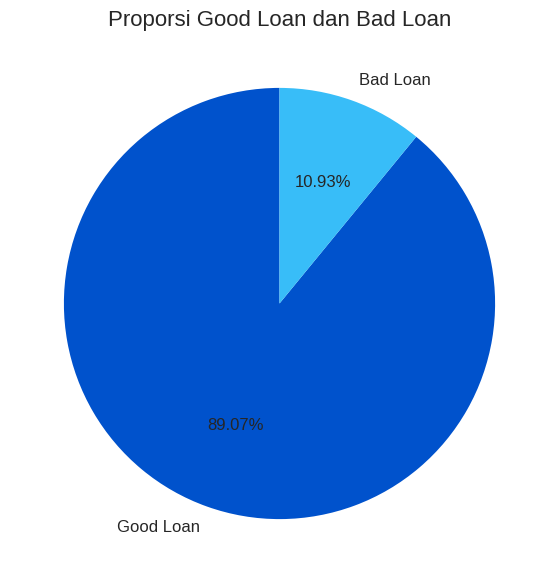

In [ ]:
# Hitung proporsi masing-masing kategori
proporsi = df['loan_bad'].value_counts(normalize=True) * 100

# Buat pie chart
labels = ['Good Loan', 'Bad Loan']
colors = ['#0052CC', '#38BDF8'] # Warna untuk masing-masing kategori
plt.figure(figsize=(7, 7))
plt.pie(proporsi, labels=labels, autopct='%1.2f%%', startangle=90, colors=colors, textprops={'fontsize': 12})
plt.title('Proporsi Good Loan dan Bad Loan', fontsize=16)
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 74 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           466285 non-null  int64  
 1   member_id                    466285 non-null  int64  
 2   loan_amnt                    466285 non-null  int64  
 3   funded_amnt                  466285 non-null  int64  
 4   funded_amnt_inv              466285 non-null  float64
 5   term                         466285 non-null  object 
 6   int_rate                     466285 non-null  float64
 7   installment                  466285 non-null  float64
 8   grade                        466285 non-null  object 
 9   sub_grade                    466285 non-null  object 
 10  emp_title                    438697 non-null  object 
 11  emp_length                   445277 non-null  object 
 12  home_ownership               466285 non-null  object 
 13 

In [ ]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,loan_bad
0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [ ]:
null_percentage = df.isnull().mean() * 100
print(null_percentage)

id                               0.000000
member_id                        0.000000
loan_amnt                        0.000000
funded_amnt                      0.000000
funded_amnt_inv                  0.000000
term                             0.000000
int_rate                         0.000000
installment                      0.000000
grade                            0.000000
sub_grade                        0.000000
emp_title                        5.916553
emp_length                       4.505399
home_ownership                   0.000000
annual_inc                       0.000858
verification_status              0.000000
issue_d                          0.000000
pymnt_plan                       0.000000
url                              0.000000
desc                            72.981975
purpose                          0.000000
title                            0.004504
zip_code                         0.000000
addr_state                       0.000000
dti                              0

In [ ]:
#kolom > 70% missing values
missing_values = df.isnull().mean()
missing_values[missing_values>0.7]

,0
desc,0.729820
mths_since_last_record,0.865666
mths_since_last_major_derog,0.787739
annual_inc_joint,1.000000
dti_joint,1.000000
verification_status_joint,1.000000
open_acc_6m,1.000000
open_il_6m,1.000000
open_il_12m,1.000000
open_il_24m,1.000000


In [ ]:
null_percentage = df.isnull().mean() * 100
print(null_percentage)

id                               0.000000
member_id                        0.000000
loan_amnt                        0.000000
funded_amnt                      0.000000
funded_amnt_inv                  0.000000
term                             0.000000
int_rate                         0.000000
installment                      0.000000
grade                            0.000000
sub_grade                        0.000000
emp_title                        5.916553
emp_length                       4.505399
home_ownership                   0.000000
annual_inc                       0.000858
verification_status              0.000000
issue_d                          0.000000
pymnt_plan                       0.000000
url                              0.000000
desc                            72.981975
purpose                          0.000000
title                            0.004504
zip_code                         0.000000
addr_state                       0.000000
dti                              0

In [ ]:
#hapus kolom tidak relevan dan kolom missing values . 70 %

columns_to_drop = ['id', 'member_id', 'sub_grade', 'emp_title', 'url', 'desc', 'title', 'zip_code', 'next_pymnt_d',
                  'recoveries', 'collection_recovery_fee', 'total_rec_prncp', 'total_rec_late_fee', 'desc', 'mths_since_last_record',
                  'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m',
                  'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m',
                  'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m','policy_code',]
df.drop(columns=columns_to_drop, inplace=True, axis=1)

df.dropna(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Data columns (total 41 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   loan_amnt                   181686 non-null  int64  
 1   funded_amnt                 181686 non-null  int64  
 2   funded_amnt_inv             181686 non-null  float64
 3   term                        181686 non-null  object 
 4   int_rate                    181686 non-null  float64
 5   installment                 181686 non-null  float64
 6   grade                       181686 non-null  object 
 7   emp_length                  181686 non-null  object 
 8   home_ownership              181686 non-null  object 
 9   annual_inc                  181686 non-null  float64
 10  verification_status         181686 non-null  object 
 11  issue_d                     181686 non-null  object 
 12  pymnt_plan                  181686 non-null  object 
 13  purpose        

**EDA**

**Multivariat Analysis**

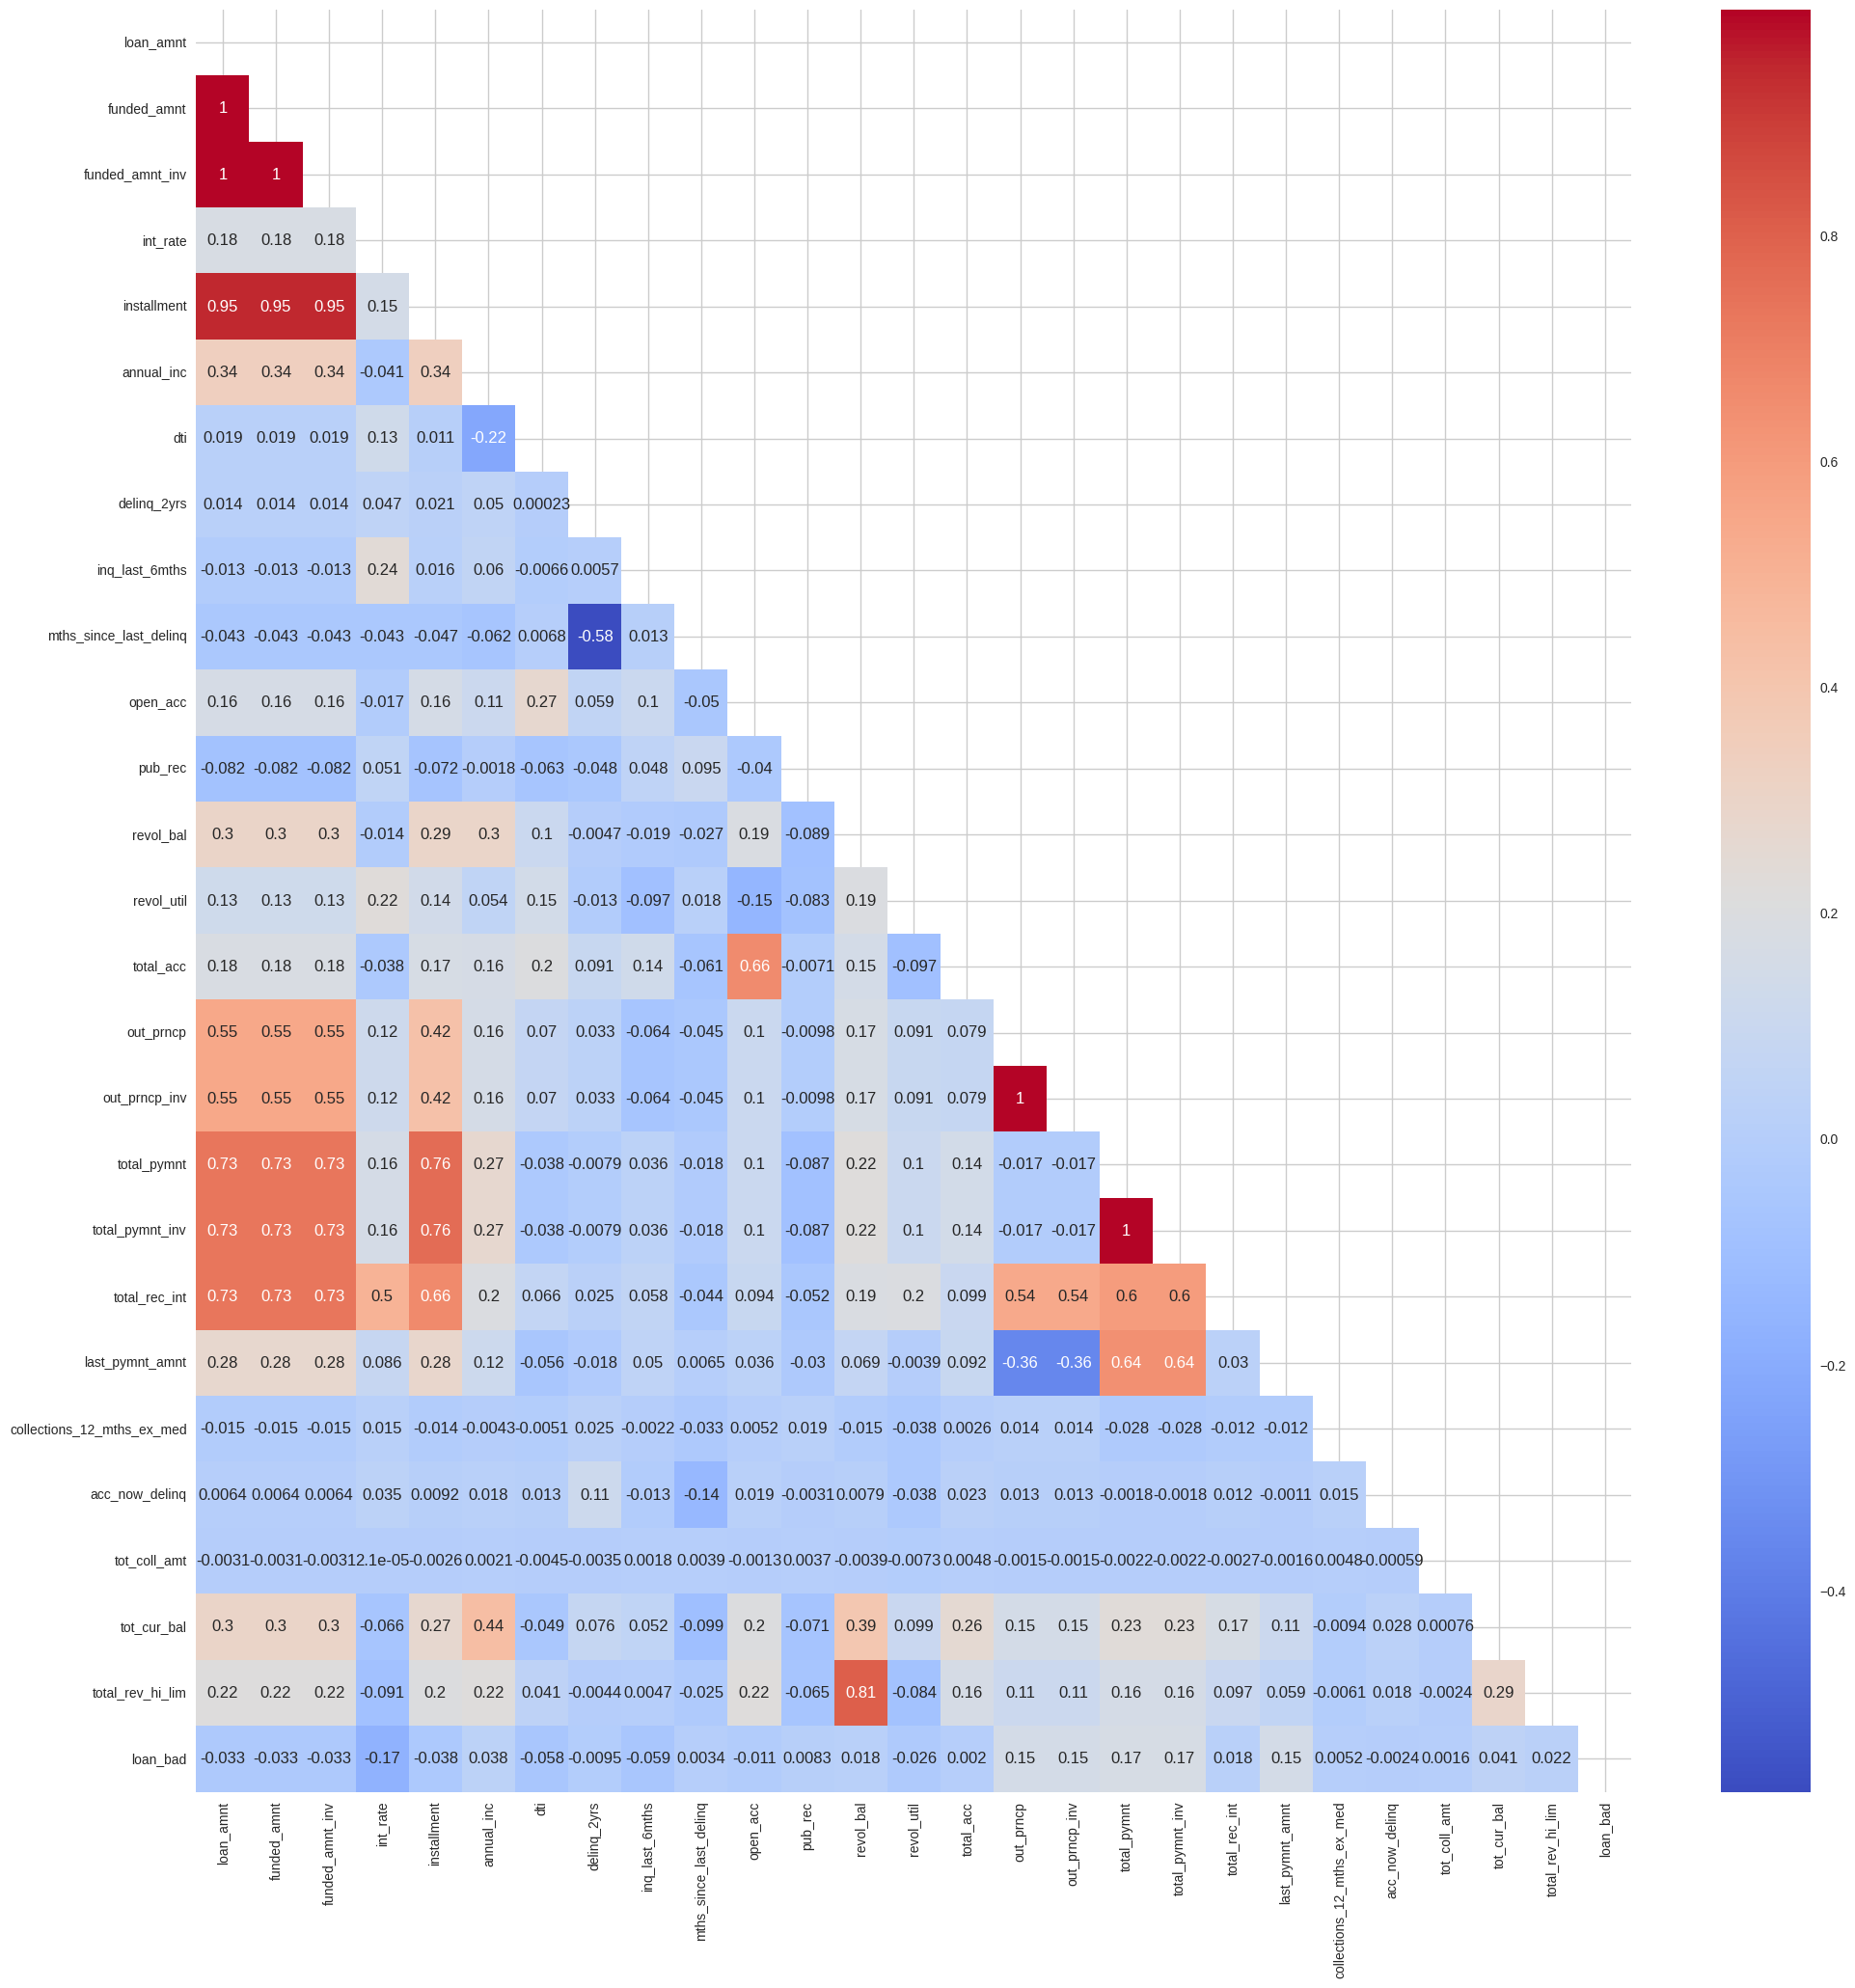

In [ ]:
# Memilih kolom numerik
df_num = df.select_dtypes(include=['number'])

# Membuat mask untuk heatmap
mask = np.zeros_like(df_num.corr(), dtype=bool)
mask[np.triu_indices_from(mask)] = True

# Plotting heatmap
plt.figure(figsize=(24, 24))
sns.heatmap(df_num.corr(), mask=mask, annot=True, cmap='coolwarm')
plt.show()

In [ ]:
#Minimalisir Multikolinearitas
columns_to_drop = ['loan_amnt', 'revol_bal', 'funded_amnt', 'funded_amnt_inv', 'installment',
                   'total_pymnt_inv', 'out_prncp_inv']
columns_in_df = [col for col in columns_to_drop if col in df.columns]
df.drop(columns=columns_in_df, inplace=True)

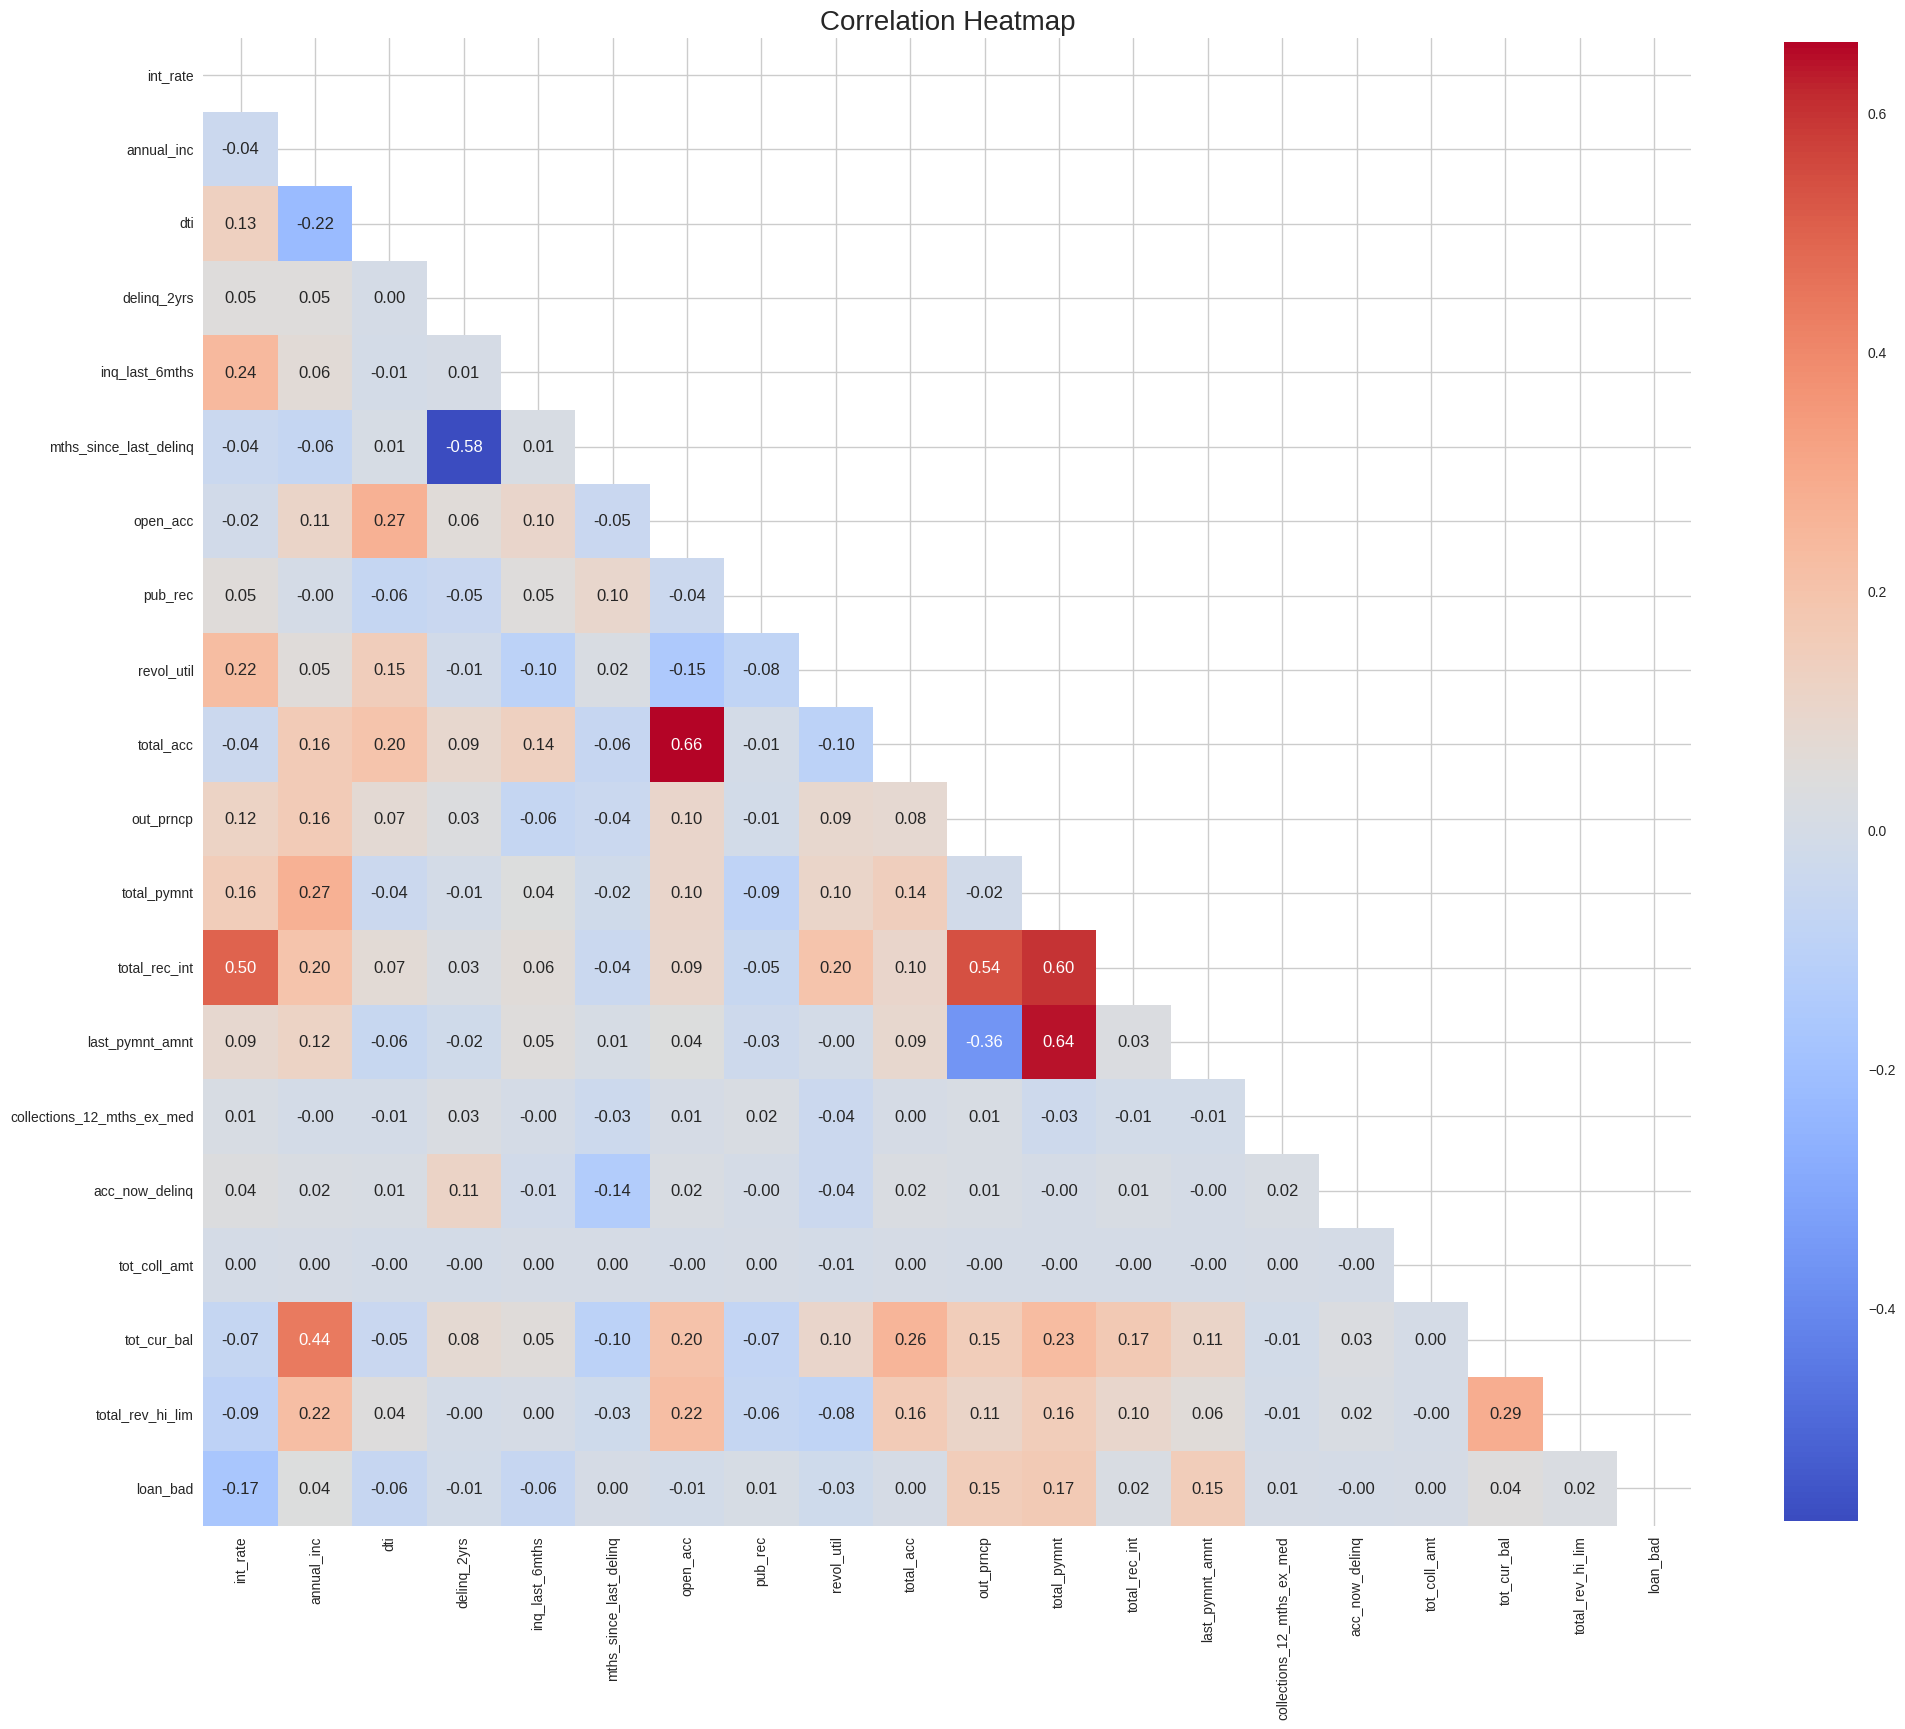

In [ ]:
#Filter hanya kolom numerik
numeric_df = df.select_dtypes(include=['number'])

#Membersihkan nilai non-numerik tersembunyi di kolom numerik (jika ada)
for col in numeric_df.columns:
    numeric_df[col] = pd.to_numeric(numeric_df[col], errors='coerce')

#Menghapus baris dengan NaN yang muncul akibat konversi
numeric_df.dropna(inplace=True)

# Menghitung matriks korelasi
corr_matrix = numeric_df.corr()

# Membuat mask untuk heatmap (segitiga atas)
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True

# Plot heatmap korelasi
plt.figure(figsize=(24, 24))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", square=True, cbar_kws={'shrink': .8})
plt.title("Correlation Heatmap", fontsize=20)
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   term                        181686 non-null  object 
 1   int_rate                    181686 non-null  float64
 2   grade                       181686 non-null  object 
 3   emp_length                  181686 non-null  object 
 4   home_ownership              181686 non-null  object 
 5   annual_inc                  181686 non-null  float64
 6   verification_status         181686 non-null  object 
 7   issue_d                     181686 non-null  object 
 8   pymnt_plan                  181686 non-null  object 
 9   purpose                     181686 non-null  object 
 10  addr_state                  181686 non-null  object 
 11  dti                         181686 non-null  float64
 12  delinq_2yrs                 181686 non-null  float64
 13  earliest_cr_lin

In [ ]:
df.describe()

,int_rate,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,open_acc,pub_rec,revol_util,total_acc,out_prncp,total_pymnt,total_rec_int,last_pymnt_amnt,collections_12_mths_ex_med,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,loan_bad
count,181686.000000,1.816860e+05,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,181686.000000,1.816860e+05,1.816860e+05,1.816860e+05,181686.000000
mean,14.449868,7.886698e+04,17.389873,0.638040,0.822942,33.724167,11.756382,0.189244,56.548318,27.814157,5291.496180,11215.608032,2679.857733,3146.519033,0.016418,0.009808,3.263843e+02,1.505644e+05,2.735155e+04,0.901897
std,4.252272,6.078531e+04,7.787230,1.104461,1.059299,21.716923,4.997763,0.557625,22.583195,11.310518,6660.857513,7986.951463,2470.226061,5633.250884,0.149082,0.107319,2.157745e+04,1.595617e+05,4.243696e+04,0.297455
min,6.000000,4.000000e+03,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,3.000000,0.000000,35.690000,0.000000,0.010000,0.000000,0.000000,0.000000e+00,0.000000e+00,1.000000e+02,0.000000
25%,11.670000,5.000000e+04,11.530000,0.000000,0.000000,15.000000,8.000000,0.000000,40.300000,20.000000,0.000000,5485.875000,1037.310000,321.130000,0.000000,0.000000,0.000000e+00,3.245125e+04,1.230000e+04,1.000000
50%,14.160000,6.800000e+04,16.910000,0.000000,0.000000,30.000000,11.000000,0.000000,57.400000,26.000000,2637.215000,9127.115000,1925.520000,539.810000,0.000000,0.000000,0.000000e+00,9.847150e+04,2.060000e+04,1.000000
75%,17.140000,9.402825e+04,22.900000,1.000000,1.000000,49.000000,14.000000,0.000000,73.900000,34.000000,8883.127500,14685.300000,3432.090000,3048.777500,0.000000,0.000000,0.000000e+00,2.255148e+05,3.400000e+04,1.000000
max,26.060000,7.500000e+06,39.990000,29.000000,7.000000,188.000000,84.000000,21.000000,892.300000,156.000000,31898.770000,56087.909920,21840.000000,36170.140000,20.000000,5.000000,9.152545e+06,8.000078e+06,9.999999e+06,1.000000


**Univariat Analysis**

In [ ]:
num1 = [
    'int_rate', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq',
    'open_acc', 'pub_rec', 'revol_util', 'out_prncp', 'total_pymnt', 'total_rec_int',
    'last_pymnt_amnt', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt',
    'tot_cur_bal', 'total_rev_hi_lim', 'loan_bad'
]

cat1 = [
    'term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'issue_d',
    'pymnt_plan', 'purpose', 'addr_state', 'earliest_cr_line', 'initial_list_status',
    'last_pymnt_d', 'last_credit_pull_d', 'application_type']

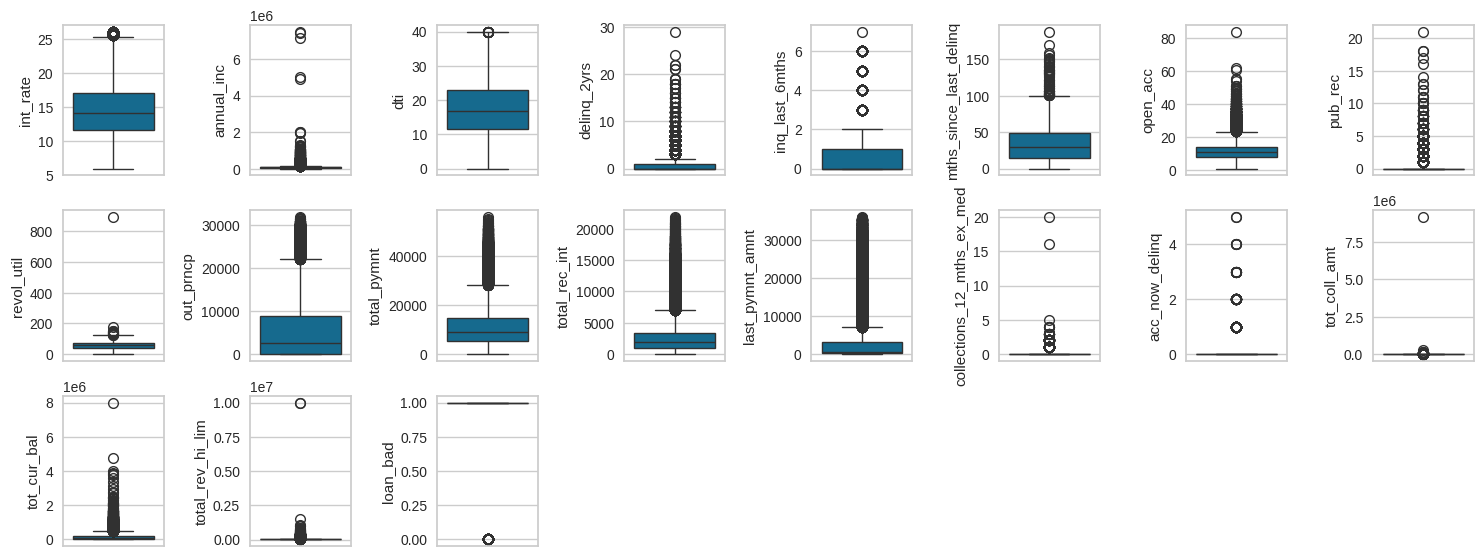

In [ ]:
#Distribusi Menggunakan Boxplot
num = df.loc[:, (df.dtypes == 'int64') | (df.dtypes == 'float64')].columns.tolist()

plt.figure(figsize=(15, 15))
for i in range(len(num1)):
    plt.subplot(8, 8, i + 1)
    sns.boxplot(y=df[num1[i]], orient='v')
    plt.tight_layout()

/tmp/ipykernel_2190/1496160051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[num1[i]], color = 'blue')
/tmp/ipykernel_2190/1496160051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[num1[i]], color = 'blue')
/tmp/ipykernel_2190/1496160051.py:5: UserWarning: 

`distplot` is a depr

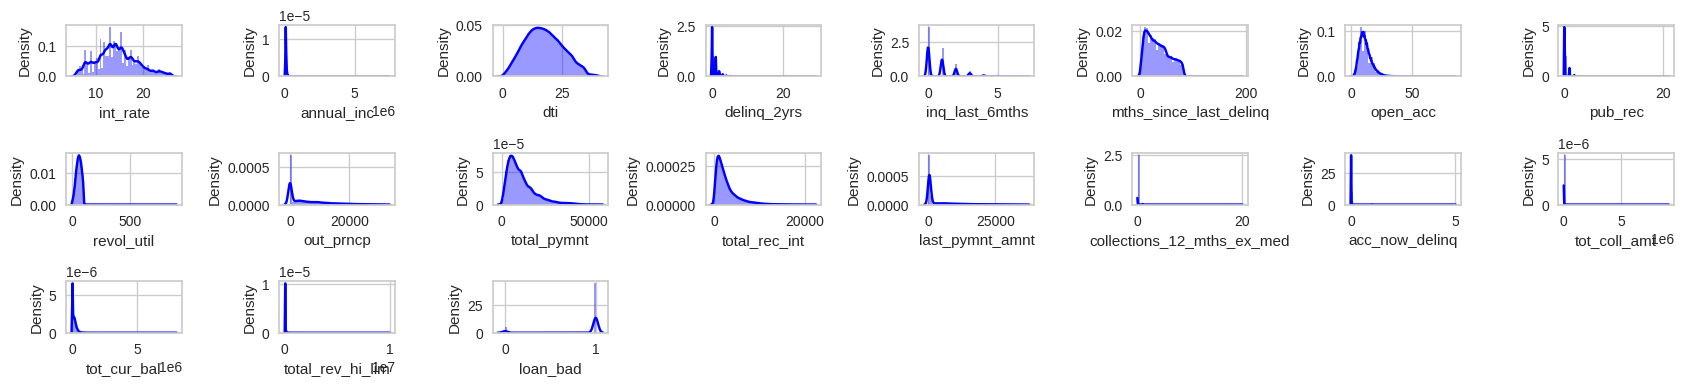

In [ ]:
# cek distribusi menggunakan distplot
plt.figure(figsize=(17, 10))
for i in range(0, len(num1)):
    plt.subplot(8, 8, i+1)
    sns.distplot(df[num1[i]], color = 'blue')
    plt.tight_layout()
plt.show()

**Bivariat Analisis**

**Numerikal & Kategorikal**

/tmp/ipykernel_2190/2503993281.py:9: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(x='term', y='int_rate', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
/tmp/ipykernel_2190/2503993281.py:15: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(x='emp_length', y='annual_inc', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
/tmp/ipykernel_2190/2503993281.py:21: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(x='home_ownership', y='dti', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
/tmp/ipykernel_2190/2503993281.py:27: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(x='grade', y='open_acc', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
/tmp/ipykernel_2190/2503993281.py:33: UserW

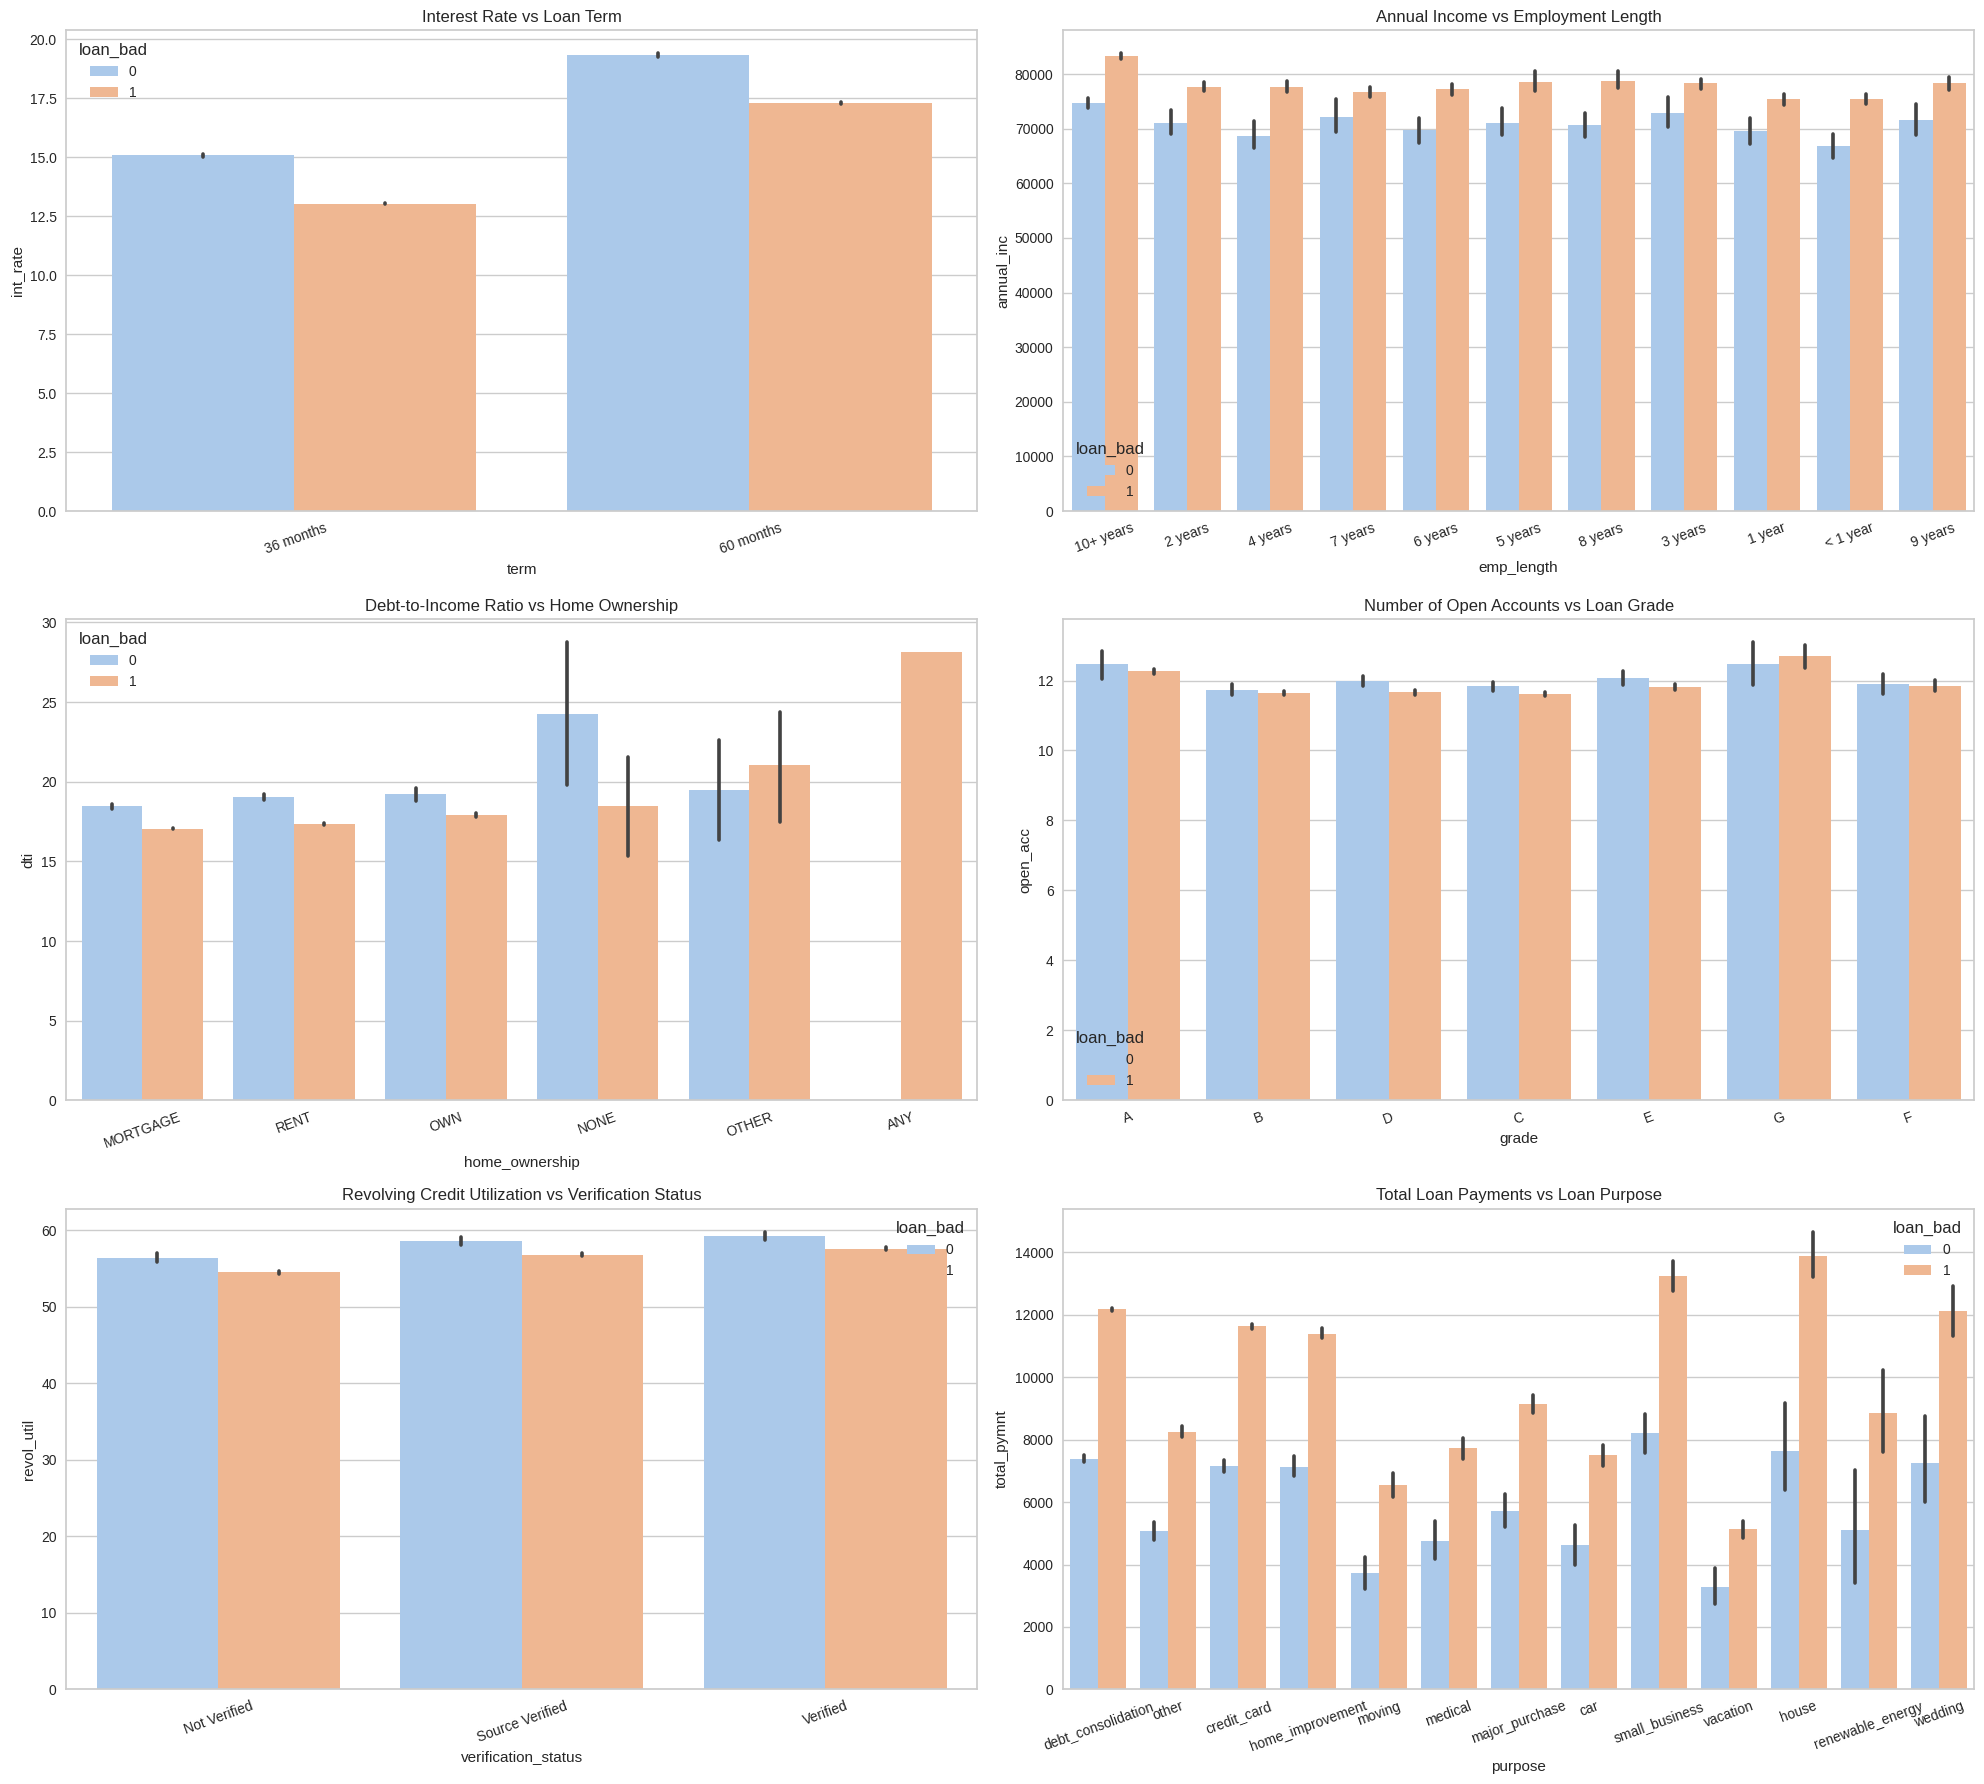

In [ ]:
# Set size for the plots
plt.figure(figsize=(20, 18))

# Soft color palette (you can also use other color palettes like 'pastel', 'muted', etc.)
soft_palette = sns.color_palette("pastel")

# 1. Interest Rate (int_rate) vs Loan Term (term) using barplot
plt.subplot(3, 2, 1)
sns.barplot(x='term', y='int_rate', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Interest Rate vs Loan Term')

# 2. Annual Income (annual_inc) vs Employment Length (emp_length) using barplot
plt.subplot(3, 2, 2)
sns.barplot(x='emp_length', y='annual_inc', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Annual Income vs Employment Length')

# 3. Debt-to-Income Ratio (dti) vs Home Ownership (home_ownership) using barplot
plt.subplot(3, 2, 3)
sns.barplot(x='home_ownership', y='dti', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Debt-to-Income Ratio vs Home Ownership')

# 4. Number of Open Accounts (open_acc) vs Loan Grade (grade) using barplot
plt.subplot(3, 2, 4)
sns.barplot(x='grade', y='open_acc', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Number of Open Accounts vs Loan Grade')

# 5. Revolving Credit Utilization (revol_util) vs Verification Status (verification_status) using barplot
plt.subplot(3, 2, 5)
sns.barplot(x='verification_status', y='revol_util', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Revolving Credit Utilization vs Verification Status')

# 6. Total Loan Payments (total_pymnt) vs Loan Purpose (purpose) using barplot
plt.subplot(3, 2, 6)
sns.barplot(x='purpose', y='total_pymnt', data=df, hue='loan_bad', palette=soft_palette, edgecolor='none')
plt.xticks(rotation=20)
plt.title('Total Loan Payments vs Loan Purpose')

# Show the plots
plt.tight_layout()
plt.show()

Interest Rate vs Loan Term Interpretasi: Grafik menunjukkan bahwa tingkat bunga (interest rate) untuk pinjaman dengan durasi 60 bulan sedikit lebih rendah daripada pinjaman dengan durasi 36 bulan, baik untuk pinjaman yang baik (loan_bad=0) maupun buruk (loan_bad=1). Tidak ada perbedaan yang mencolok antara kategori loan_bad=0 dan loan_bad=1, meskipun ada sedikit perbedaan pada tingkat bunga untuk pinjaman dengan durasi lebih panjang.

Annual Income vs Employment Length Interpretasi: Secara umum, grafik menunjukkan bahwa pendapatan tahunan (annual income) lebih tinggi untuk kategori "10+ years" dalam durasi pekerjaan (employment length), baik untuk pinjaman yang baik (loan_bad=0) maupun buruk (loan_bad=1). Tidak ada perbedaan signifikan antara kedua kategori loan_bad dalam masing-masing kelompok durasi pekerjaan. Namun, terlihat bahwa beberapa kategori (misalnya, "1 year" dan "3 years") menunjukkan sedikit perbedaan antara loan_bad=0 dan loan_bad=1, di mana pendapatan untuk pinjaman buruk lebih rendah.

Debt-to-Income Ratio vs Home Ownership Interpretasi: Grafik ini menunjukkan rasio utang terhadap pendapatan (debt-to-income ratio, DTI) berdasarkan status kepemilikan rumah. Tidak ada perbedaan besar dalam rasio DTI antara kategori loan_bad=0 dan loan_bad=1, meskipun kategori OWN dan NONE menunjukkan rasio yang lebih tinggi dibandingkan kategori MORTGAGE dan RENT. Hal ini menunjukkan bahwa mereka yang tidak memiliki rumah atau yang memiliki rumah mungkin lebih cenderung memiliki rasio utang yang lebih tinggi.

Number of Open Accounts vs Loan Grade Interpretasi: Jumlah akun terbuka (open accounts) sedikit lebih tinggi untuk pinjaman baik (loan_bad=0) di semua kategori loan grade. Perbedaan antara kategori loan_bad=0 dan loan_bad=1 terlihat kecil, meskipun ada sedikit peningkatan pada kategori loan_bad=0 di sebagian besar grade pinjaman (A, B, C). Secara umum, pinjaman dengan grade yang lebih baik (A, B) memiliki jumlah akun terbuka yang lebih tinggi dibandingkan dengan pinjaman yang lebih rendah (C, D, dan seterusnya).

Revolving Credit Utilization vs Verification Status Interpretasi: Utilisasi kredit berputar (revolving credit utilization) hampir serupa antara kategori loan_bad=0 dan loan_bad=1 di semua status verifikasi. Tidak ada perbedaan yang jelas antara loan_bad=0 dan loan_bad=1, meskipun sedikit lebih tinggi untuk status "Verified".

Total Loan Payments vs Loan Purpose Interpretasi: Pembayaran total pinjaman (total loan payments) untuk tujuan pinjaman home_improvement dan education lebih tinggi dibandingkan dengan kategori lainnya, baik untuk pinjaman baik (loan_bad=0) maupun buruk (loan_bad=1). Pada kategori tujuan pinjaman lain seperti medical dan renewable_energy juga terlihat perbedaan signifikan dalam jumlah pembayaran total, dengan loan_bad=0 cenderung lebih tinggi dibandingkan dengan loan_bad=1. Hal ini menunjukkan bahwa tujuan pinjaman seperti home_improvement dan education mungkin lebih mengarah ke pinjaman yang lebih besar atau lebih stabil dalam hal pembayaran dibandingkan dengan kategori lainnya.

**Kategorikal & Kategorikal**

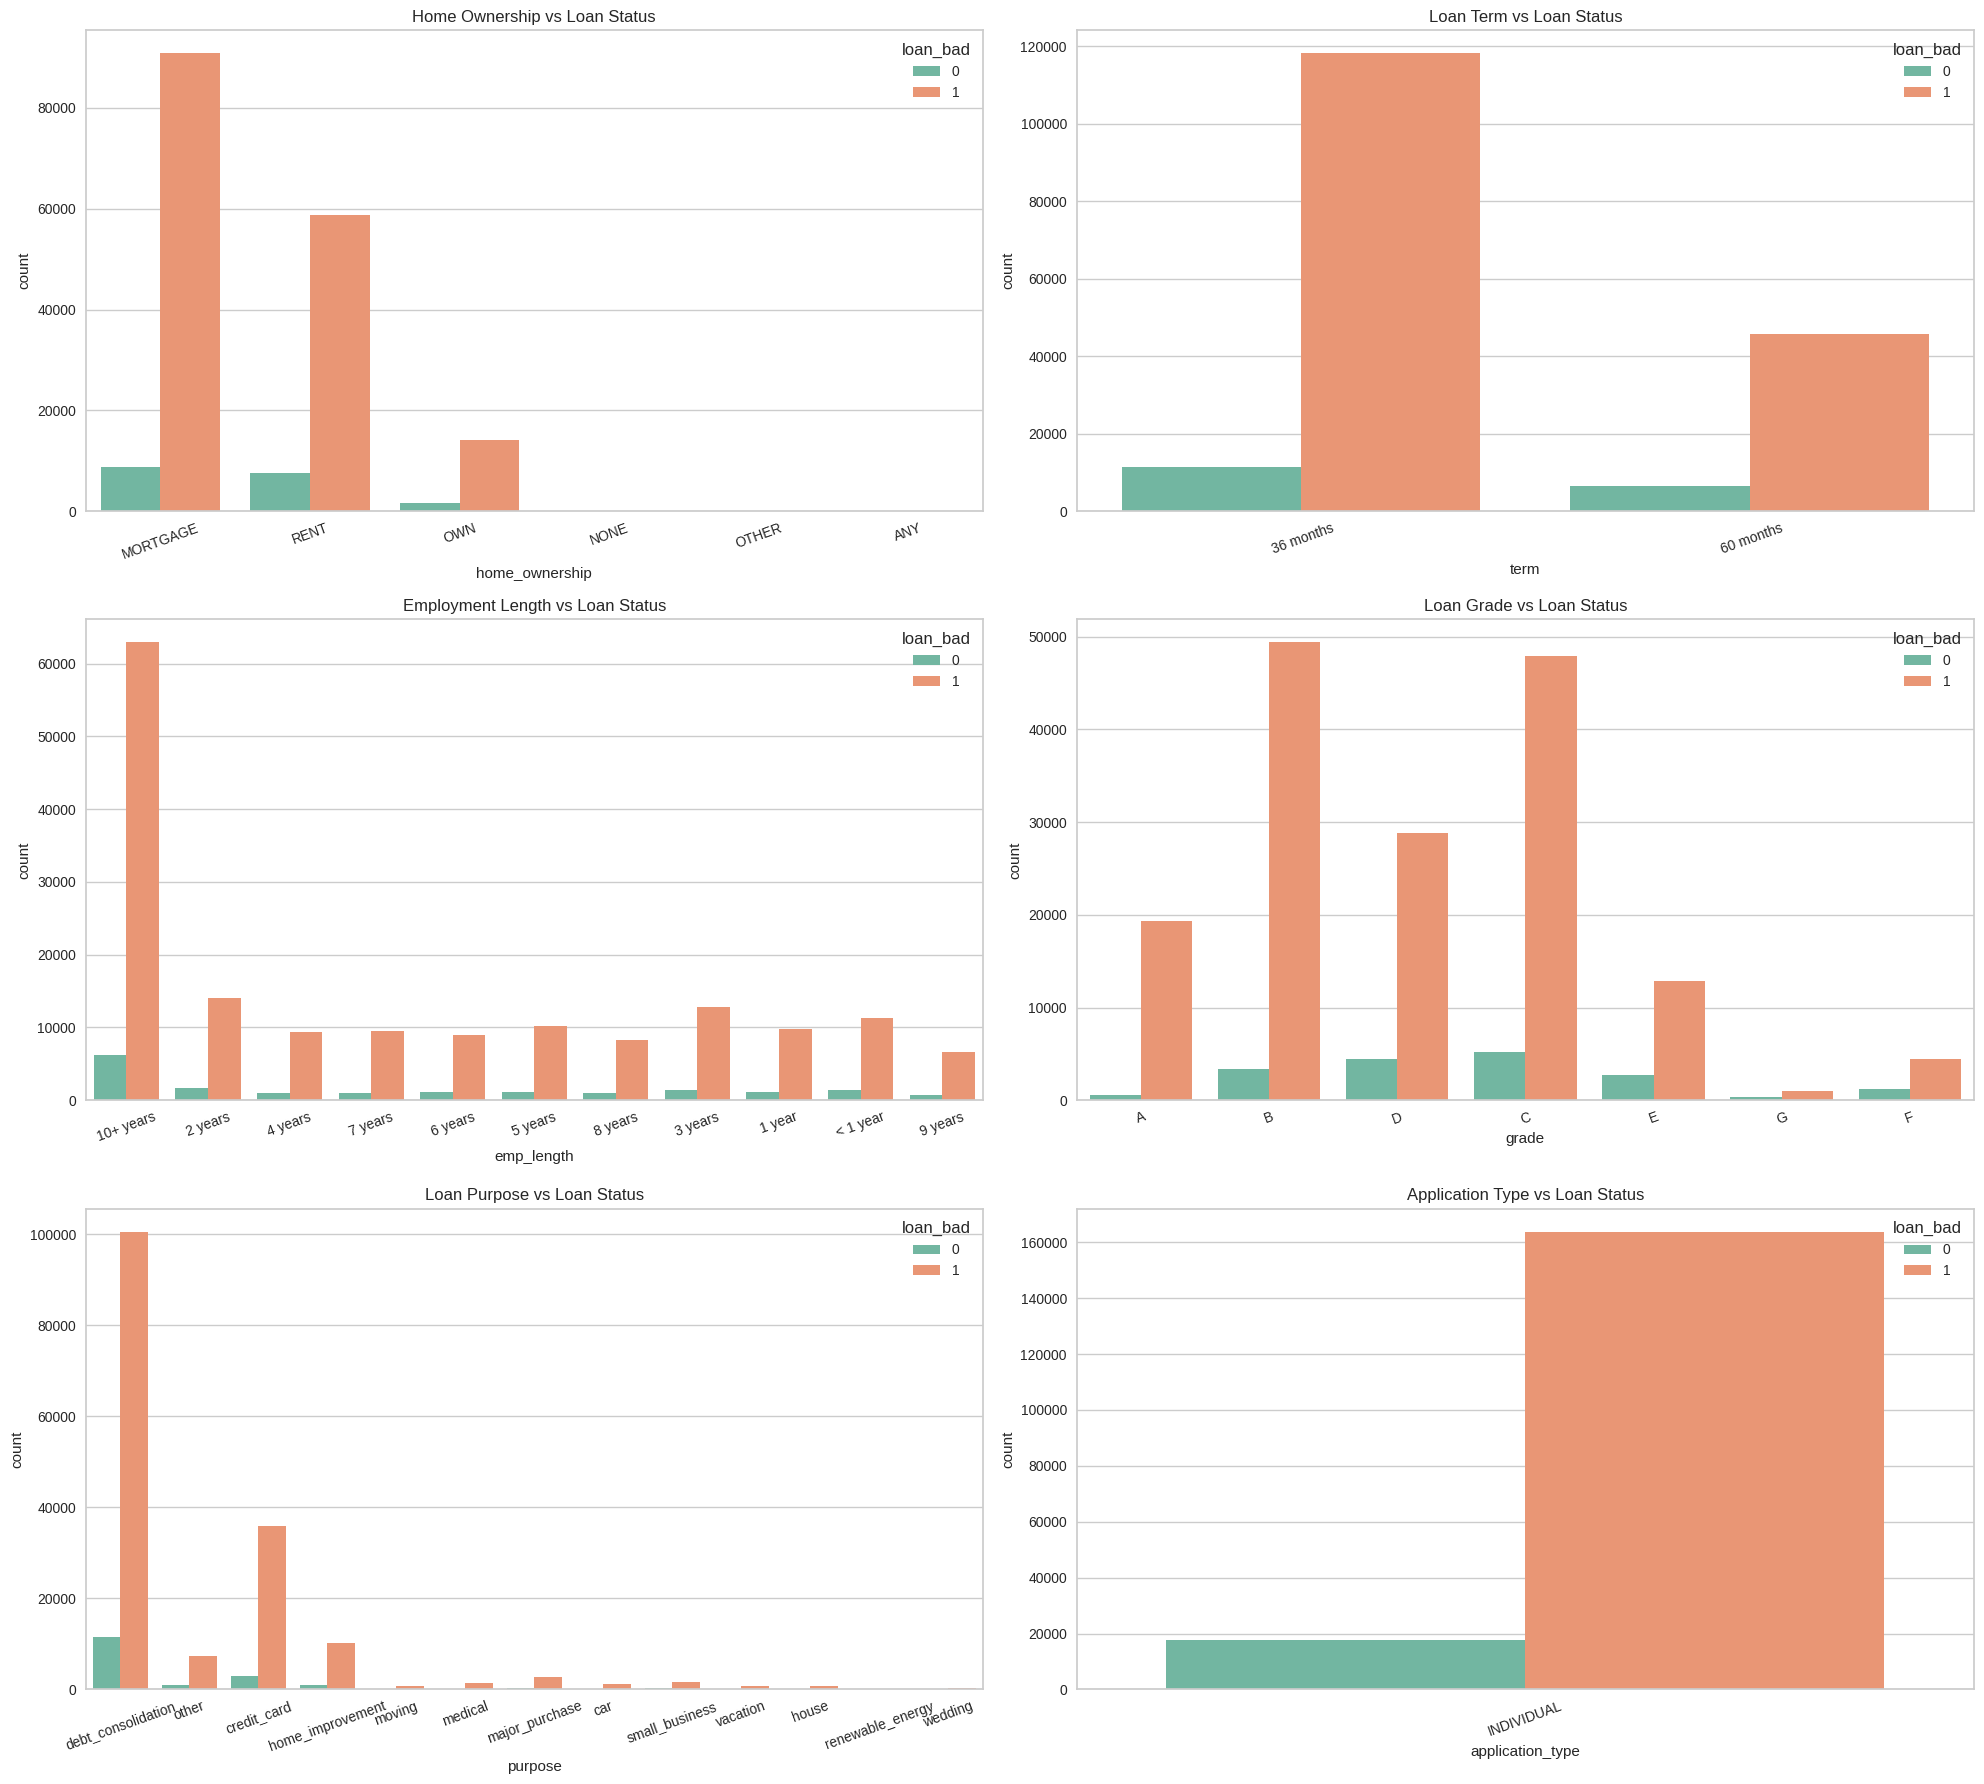

In [ ]:
# Set size for the plots
plt.figure(figsize=(20, 18))

# 1. Home Ownership (home_ownership) vs Loan Status (loan_bad)
plt.subplot(3, 2, 1)
sns.countplot(x='home_ownership', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Home Ownership vs Loan Status')

# 2. Loan Term (term) vs Loan Status (loan_bad)
plt.subplot(3, 2, 2)
sns.countplot(x='term', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Loan Term vs Loan Status')

# 3. Employment Length (emp_length) vs Loan Status (loan_bad)
plt.subplot(3, 2, 3)
sns.countplot(x='emp_length', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Employment Length vs Loan Status')

# 4. Grade (grade) vs Loan Status (loan_bad)
plt.subplot(3, 2, 4)
sns.countplot(x='grade', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Loan Grade vs Loan Status')

# 5. Loan Purpose (purpose) vs Loan Status (loan_bad)
plt.subplot(3, 2, 5)
sns.countplot(x='purpose', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Loan Purpose vs Loan Status')

# 6. Application Type (application_type) vs Loan Status (loan_bad)
plt.subplot(3, 2, 6)
sns.countplot(x='application_type', hue='loan_bad', data=df, palette="Set2")
plt.xticks(rotation=20)
plt.title('Application Type vs Loan Status')

# Show the plots
plt.tight_layout()
plt.show()

Home Ownership vs Loan Status Interpretasi: Mayoritas peminjam memiliki status "OWN" (memiliki rumah), diikuti oleh "MORTGAGE" dan "RENT". Terkait dengan loan_status, hampir semua peminjam yang memiliki status loan_bad=1 (pinjaman buruk) berada dalam kategori "MORTGAGE" atau "RENT", dengan "OWN" yang cenderung memiliki lebih sedikit pinjaman buruk. Hal ini mengindikasikan bahwa pemilik rumah yang memiliki loan_bad=1 lebih jarang dibandingkan dengan penyewa atau mereka yang tidak memiliki rumah.
Loan Term vs Loan Status Interpretasi: Grafik menunjukkan bahwa mayoritas pinjaman memiliki loan term = 36 months (36 bulan), sementara pinjaman dengan durasi 60 months lebih sedikit. Untuk loan_bad=1, terlihat bahwa hampir semua pinjaman dengan durasi 60 months adalah pinjaman buruk. Sebaliknya, pinjaman 36 months lebih banyak ditemukan dalam kategori loan_bad=0 (pinjaman baik). Ini menunjukkan bahwa pinjaman dengan durasi lebih panjang mungkin memiliki risiko lebih tinggi untuk mengalami kegagalan pembayaran.
Employment Length vs Loan Status Interpretasi: Sebagian besar peminjam memiliki durasi pekerjaan lebih dari 10 tahun. Meskipun ada distribusi peminjam yang memiliki pekerjaan selama beberapa tahun, loan_bad=1 paling banyak ditemukan pada mereka yang memiliki durasi pekerjaan (< 1) year atau 1 year, serta lebih sedikit pada peminjam dengan durasi kerja lebih panjang (misalnya, 10+ years). Ini menunjukkan bahwa peminjam dengan durasi pekerjaan yang lebih pendek lebih cenderung memiliki pinjaman yang buruk, sementara mereka dengan pekerjaan lebih lama memiliki risiko yang lebih rendah.
Loan Grade vs Loan Status Interpretasi: Pinjaman dengan grade B paling banyak ditemukan, diikuti oleh grade C, sedangkan grade lainnya (A, D, E, F, G) jauh lebih sedikit. Loan_bad=1 lebih dominan pada kategori grade C, D, dan E, sedangkan loan_bad=0 cenderung terdapat pada grade A dan B. Hal ini menunjukkan bahwa peminjam dengan grade pinjaman yang lebih rendah (C, D, E) lebih cenderung memiliki pinjaman yang buruk.
Loan Purpose vs Loan Status Interpretasi: Mayoritas tujuan pinjaman adalah untuk debt_consolidation dan credit_card, diikuti oleh home_improvement dan major_purchase. Tujuan pinjaman debt_consolidation dan credit_card cenderung lebih banyak mengalami loan_bad=1, yang mengindikasikan bahwa pinjaman untuk konsolidasi utang atau untuk tujuan kartu kredit mungkin memiliki risiko yang lebih tinggi untuk gagal bayar dibandingkan dengan tujuan pinjaman lainnya seperti home_improvement atau major_purchase.
Application Type vs Loan Status Interpretasi: Sebagian besar aplikasi pinjaman adalah INDIVIDUAL (individu), sedangkan aplikasi JOINT sangat sedikit. Loan_bad=1 lebih sering ditemukan pada aplikasi INDIVIDUAL, dengan hampir tidak ada kasus loan_bad=1 pada aplikasi JOINT. Ini menunjukkan bahwa aplikasi pinjaman individu lebih cenderung terkait dengan pinjaman buruk, sementara aplikasi bersama (joint) jauh lebih jarang ditemukan, dan kemungkinan besar terkait dengan pinjaman yang lebih stabil. Kesimpulan: Grafik ini menunjukkan hubungan yang signifikan antara beberapa faktor seperti home ownership, loan term, loan grade, loan purpose, dan application type dengan status pinjaman. Secara umum, peminjam dengan loan term 36 bulan, grade A atau B, dan lama pekerjaan lebih dari 10 tahun lebih cenderung memiliki pinjaman yang baik (loan_status=0). Sebaliknya, peminjam dengan loan term 60 bulan, grade C atau lebih rendah, serta tujuan pinjaman untuk konsolidasi utang atau kartu kredit lebih sering mengalami pinjaman buruk (loan_status=1). Aplikasi individu juga lebih berisiko gagal bayar dibandingkan aplikasi bersama.

**Preprocessing**

**Data Inkonsisten**

1. Continous Variable

In [ ]:
# A. Fitur emp_length
df['emp_length'].unique()

array(['10+ years', '2 years', '4 years', '7 years', '6 years', '5 years',
       '8 years', '3 years', '1 year', '< 1 year', '9 years'],
      dtype=object)

In [ ]:
df['emp_length_int'] = df['emp_length'].str.replace(r'\+ years','', regex = True)
df['emp_length_int'] = df['emp_length_int'].str.replace('< 1 year',str(0), regex = True)
df['emp_length_int'] = df['emp_length_int'].str.replace('n/a',str(0), regex = True)
df['emp_length_int'] = df['emp_length_int'].str.replace(' years','', regex = True)
df['emp_length_int'] = df['emp_length_int'].str.replace(' year','', regex = True)
df['emp_length_int'].describe()

,emp_length_int
count,181686
unique,11
top,10
freq,69102


In [ ]:
df.emp_length_int = pd.to_numeric(df.emp_length_int)
df.emp_length_int.describe()

,emp_length_int
count,181686.000000
mean,6.324092
std,3.607371
min,0.000000
25%,3.000000
50%,7.000000
75%,10.000000
max,10.000000


In [ ]:
# B. Fitur term
df['term_int'] = df['term'].str.replace(' months', '', regex = True)
df.term_int.value_counts()

,count
term_int,
36,129478
60,52208


In [ ]:
df.term_int = pd.to_numeric(df.term_int)
df.term_int.unique()

array([36, 60])

In [ ]:
df['earliest_cr_line_date'] = pd.to_datetime(df.earliest_cr_line, format='%b-%y')
df.earliest_cr_line_date.head()

,earliest_cr_line_date
42537,1994-03-01
42538,1998-10-01
42539,1998-03-01
42541,1988-06-01
42543,1989-10-01


In [ ]:
total_hari = pd.to_datetime('2024-12-01') - df.earliest_cr_line_date
total_hari.head()

,earliest_cr_line_date
42537,11233 days
42538,9558 days
42539,9772 days
42541,13332 days
42543,12845 days


In [ ]:
df['mths_since_earliest_cr_line'] = round(total_hari / np.timedelta64(1, 'D') / 30.44)

# Melihat hasil
df['mths_since_earliest_cr_line'].describe()

,mths_since_earliest_cr_line
count,181686.000000
mean,334.169039
std,89.560308
min,-528.000000
25%,278.000000
50%,319.000000
75%,378.000000
max,671.000000


In [ ]:
df.mths_since_earliest_cr_line.max()

671.0

In [ ]:
df.mths_since_earliest_cr_line[df.mths_since_earliest_cr_line < 0] = df.mths_since_earliest_cr_line.max()

/tmp/ipykernel_2190/2767488582.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df.mths_since_earliest_cr_line[df.mths_since_earliest_cr_line < 0] = df.mths_since_earliest_cr_line.max()
/tmp/ipykernel_2190/2767488582.py:1: SettingWithCopy

In [ ]:
min(df['mths_since_earliest_cr_line'])

159.0

In [ ]:
# Konversi 'issue_d' ke datetime
df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%y')

# Tanggal referensi
ref_date = pd.to_datetime('2024-12-01')

In [ ]:
# Hitung selisih bulan
df['mths_since_issue_d'] = df['issue_d'].apply(lambda x: relativedelta(ref_date, x).years * 12 + relativedelta(ref_date, x).months).astype(float)

In [ ]:
def date_columns(df, column):
    # Tanggal referensi
    today_date = pd.to_datetime('2024-12-01')
    # Konversi ke format datetime
    df[column] = pd.to_datetime(df[column], format='%b-%y')
    # Hitung selisih bulan menggunakan relativedelta
    df['mths_since_' + column] = df[column].apply(lambda x: relativedelta(today_date, x).years * 12 + relativedelta(today_date, x).months)
    # Jika ada nilai negatif, set ke maksimum
    df['mths_since_' + column] = df['mths_since_' + column].apply(lambda x: df['mths_since_' + column].max() if x < 0 else x)
    # Hapus kolom tanggal asli
    df.drop(columns=[column], inplace=True)

# Gunakan fungsi
date_columns(df, 'last_pymnt_d')
date_columns(df, 'last_credit_pull_d')

In [ ]:
# Pisah fitur kategori dan numerik
categorical_features = df.select_dtypes(include=['object', 'category'])
numerical_features = df.select_dtypes(include=['number'])

In [ ]:
# Mengisi missing values pada fitur numerik dengan median
df[numerical_features.columns] = numerical_features.fillna(numerical_features.median())
# Mengisi missing values pada fitur kategorikal dengan 'Unknown'
df[categorical_features.columns] = categorical_features.fillna('Unknown')

In [ ]:
# Menentukan data untuk preprocessing
preprocess_data = df.copy()

In [ ]:
# Checking for any remaining missing values
missing = preprocess_data.isnull().sum()
if missing[missing > 0].empty:
    print("No missing values remaining.")
else:
    print("Remaining missing values:")
    print(missing[missing > 0])

# Info tentang dataset
print("Dataset Info:")
print(preprocess_data.info())

No missing values remaining.
Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Data columns (total 39 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   term                           181686 non-null  object        
 1   int_rate                       181686 non-null  float64       
 2   grade                          181686 non-null  object        
 3   emp_length                     181686 non-null  object        
 4   home_ownership                 181686 non-null  object        
 5   annual_inc                     181686 non-null  float64       
 6   verification_status            181686 non-null  object        
 7   issue_d                        181686 non-null  datetime64[ns]
 8   pymnt_plan                     181686 non-null  object        
 9   purpose                        181686 non-null  object        
 10  addr_state                

In [ ]:
# Fungsi IV dan WoE
def iv_woe(data, target, bins=10, show_woe=False):
    newDF, woeDF = pd.DataFrame(), pd.DataFrame()
    cols = data.columns

    # Run WoE and IV on all independent variables
    for ivars in cols[~cols.isin([target])]:
        if (data[ivars].dtype.kind in 'bifc') and (len(data[ivars].unique()) > 10):
            binned_x = pd.qcut(data[ivars], bins, duplicates='drop')  # Bucketing untuk fitur numerik
            d0 = pd.DataFrame({'x': binned_x, 'y': data[target]})
        else:
            d0 = pd.DataFrame({'x': data[ivars], 'y': data[target]})  # Langsung proses untuk fitur kategorikal
        d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
        d.columns = ['Cutoff', 'N', 'Events']
        d['% of Events'] = np.maximum(d['Events'], 0.5) / d['Events'].sum()
        d['Non-Events'] = d['N'] - d['Events']
        d['% of Non-Events'] = np.maximum(d['Non-Events'], 0.5) / d['Non-Events'].sum()
        d['WoE'] = np.log(d['% of Events'] / d['% of Non-Events'])
        d['IV'] = d['WoE'] * (d['% of Events'] - d['% of Non-Events'])
        d.insert(loc=0, column='Variable', value=ivars)
        print(f"Information value of {ivars} is {round(d['IV'].sum(), 6)}")
        temp = pd.DataFrame({"Variable": [ivars], "IV": [d['IV'].sum()]}, columns=["Variable", "IV"])
        newDF = pd.concat([newDF, temp], axis=0)
        woeDF = pd.concat([woeDF, d], axis=0)

        if show_woe:
            print(d)

    return newDF.reset_index(drop=True), woeDF.reset_index(drop=True)

# Jalankan fungsi IV dan WoE
iv, woe = iv_woe(preprocess_data, target='loan_bad', bins=20)

# Output hasil IV
print("\nInformation Value (IV):")
print(iv)

# Output hasil WoE (opsional, karena besar)
print("\nWeight of Evidence (WoE):")
print(woe.head())

# Simpan hasil ke file (opsional)
iv.to_csv("iv_results.csv", index=False)
woe.to_csv("woe_results.csv", index=False)

Information value of term is 0.035478
Information value of int_rate is 0.347724
Information value of grade is 0.281145
Information value of emp_length is 0.007547
Information value of home_ownership is 0.017952
Information value of annual_inc is 0.037998
Information value of verification_status is 0.033377
Information value of issue_d is 0.091619
Information value of pymnt_plan is 0.000309
Information value of purpose is 0.028333
Information value of addr_state is 0.010291


/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"

Information value of dti is 0.041026
Information value of delinq_2yrs is 0.001039
Information value of earliest_cr_line is 0.055322
Information value of inq_last_6mths is 0.040454
Information value of mths_since_last_delinq is 0.002487
Information value of open_acc is 0.004499
Information value of pub_rec is 0.000504
Information value of revol_util is 0.008858
Information value of total_acc is 0.001232
Information value of initial_list_status is 0.011513


/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"

Information value of out_prncp is 0.703375
Information value of total_pymnt is 0.515794
Information value of total_rec_int is 0.011108
Information value of last_pymnt_amnt is 1.491828
Information value of collections_12_mths_ex_med is 0.000733
Information value of application_type is 0.0
Information value of acc_now_delinq is 0.0002
Information value of tot_coll_amt is 0.000738
Information value of tot_cur_bal is 0.026379


/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"

Information value of total_rev_hi_lim is 0.018835
Information value of emp_length_int is 0.007174
Information value of term_int is 0.035478
Information value of earliest_cr_line_date is 0.055322
Information value of mths_since_earliest_cr_line is 0.02135
Information value of mths_since_issue_d is 0.09055
Information value of mths_since_last_pymnt_d is 2.331187
Information value of mths_since_last_credit_pull_d is 0.313059

Information Value (IV):
                         Variable        IV
0                            term  0.035478
1                        int_rate  0.347724
2                           grade  0.281145
3                      emp_length  0.007547
4                  home_ownership  0.017952
5                      annual_inc  0.037998
6             verification_status  0.033377
7                         issue_d  0.091619
8                      pymnt_plan  0.000309
9                         purpose  0.028333
10                     addr_state  0.010291
11                   

/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
/tmp/ipykernel_2190/2192620009.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"

Aturan praktisnya mengatakan bahwa semua variabel dengan IV < 0,02 tidak berguna untuk prediksi dan IV > 0,5 memiliki daya prediksi yang mencurigakan. Oleh karena itu, variabel berikut tidak akan disertakan out_prncp, last_pymnt_amnt, delinq_2yrs, mths_since_last_delinq, open_acc, pub_rec, total_acc, collections_12_mths_ex_med, acc_now_delinq, tot_coll_amt dan mths_since_last_pymnt_d

In [ ]:
#Drop Low IV dan Leakage
low_iv_cols_leakage = [
    'pymnt_plan', 'revol_util', 'delinq_2yrs', 'mths_since_last_delinq',
    'open_acc', 'pub_rec', 'collections_12_mths_ex_med', 'acc_now_delinq',
    'tot_coll_amt', 'emp_length', 'application_type'
]

preprocess_data = preprocess_data.drop(columns=low_iv_cols_leakage, errors='ignore')

In [ ]:
preprocess_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Data columns (total 28 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   term                           181686 non-null  object        
 1   int_rate                       181686 non-null  float64       
 2   grade                          181686 non-null  object        
 3   home_ownership                 181686 non-null  object        
 4   annual_inc                     181686 non-null  float64       
 5   verification_status            181686 non-null  object        
 6   issue_d                        181686 non-null  datetime64[ns]
 7   purpose                        181686 non-null  object        
 8   addr_state                     181686 non-null  object        
 9   dti                            181686 non-null  float64       
 10  earliest_cr_line               181686 non-null  object        
 11  i

**2. Variabel Diskrit**

In [ ]:
df_dummies = [pd.get_dummies(preprocess_data['grade'], prefix='grade', prefix_sep=":"),
              pd.get_dummies(preprocess_data['home_ownership'], prefix='home_ownership', prefix_sep=":"),
              pd.get_dummies(preprocess_data['verification_status'], prefix='verification_status', prefix_sep=":"),
              pd.get_dummies(preprocess_data['purpose'], prefix='purpose', prefix_sep=":"),
              pd.get_dummies(preprocess_data['addr_state'], prefix='addr_state', prefix_sep=":"),
              pd.get_dummies(preprocess_data['initial_list_status'], prefix='initial_list_status', prefix_sep=":")]
cat_dummies = pd.concat(df_dummies, axis=1)
cat_dummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Data columns (total 78 columns):
 #   Column                               Non-Null Count   Dtype
---  ------                               --------------   -----
 0   grade:A                              181686 non-null  bool 
 1   grade:B                              181686 non-null  bool 
 2   grade:C                              181686 non-null  bool 
 3   grade:D                              181686 non-null  bool 
 4   grade:E                              181686 non-null  bool 
 5   grade:F                              181686 non-null  bool 
 6   grade:G                              181686 non-null  bool 
 7   home_ownership:ANY                   181686 non-null  bool 
 8   home_ownership:MORTGAGE              181686 non-null  bool 
 9   home_ownership:NONE                  181686 non-null  bool 
 10  home_ownership:OTHER                 181686 non-null  bool 
 11  home_ownership:OWN                   181

In [ ]:
# concatinating (penggabunngan) preprocess_data with categorical_dummies

preprocess_data = pd.concat([preprocess_data, cat_dummies], axis=1)
preprocess_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 181686 entries, 42537 to 466284
Columns: 106 entries, term to initial_list_status:w
dtypes: bool(78), datetime64[ns](2), float64(13), int64(5), object(8)
memory usage: 53.7+ MB


In [ ]:
# Cek ukuran awal
print("Jumlah kolom preprocess_data:", preprocess_data.shape[1])
print("Jumlah kolom cat_dummies:", cat_dummies.shape[1])

# Reset index agar sinkron
preprocess_data = preprocess_data.reset_index(drop=True)
cat_dummies = cat_dummies.reset_index(drop=True)

# Tambahkan prefix untuk menghindari duplikasi nama kolom
cat_dummies = cat_dummies.add_prefix('dummy_')

# Gabungkan ulang
preprocess_data1 = pd.concat([preprocess_data, cat_dummies], axis=1)

# Cek jumlah kolom setelah penggabungan
print("Jumlah kolom setelah penggabungan:", preprocess_data1.shape[1])

# Identifikasi kolom yang hilang
expected_columns = list(preprocess_data.columns) + list(cat_dummies.columns)
missing_columns = [col for col in expected_columns if col not in preprocess_data1.columns]
print("Kolom yang hilang:", missing_columns)

# Jika ada kolom hilang, tambahkan kembali
for col in missing_columns:
    if col in preprocess_data.columns:
        preprocess_data1[col] = preprocess_data[col]
    elif col in cat_dummies.columns:
        preprocess_data1[col] = cat_dummies[col]

# Final check
print("Jumlah kolom final setelah perbaikan:", preprocess_data1.shape[1])

Jumlah kolom preprocess_data: 106
Jumlah kolom cat_dummies: 78
Jumlah kolom setelah penggabungan: 184
Kolom yang hilang: []
Jumlah kolom final setelah perbaikan: 184


In [ ]:
# Function untuk menghitung WoE (Weight of Evidence) pada fitur kategorikal
def woe_categorical(preprocess_data, cat_feature, good_bad_df):
    # Menggabungkan kolom kategori dengan data target good_bad_df
    df = pd.concat([preprocess_data[cat_feature], good_bad_df], axis=1)

    # Menghitung jumlah total dan proporsi rata-rata nilai target
    df = pd.concat([
        df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
        df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean()
    ], axis=1)

    # Memilih dan mengganti nama kolom untuk kejelasan
    df = df.iloc[:, [0, 1, 3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    # Menambahkan kolom statistik tambahan untuk WoE
    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()
    df['WoE'] = np.log(df['prop_n_good'] / df['prop_n_bad'])

    # Mengurutkan berdasarkan WoE
    df = df.sort_values(['WoE']).reset_index(drop=True)

    # Menghitung perbedaan proporsi dan WoE
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE'] = df['WoE'].diff().abs()

    # Menghitung Information Value (IV)
    df['IV'] = (df['prop_n_good'] - df['prop_n_bad']) * df['WoE']
    df['IV'] = df['IV'].sum()

    return df

In [ ]:
def plot_by_woe(df_WoE, rotation_of_x_axis_labels=0):
    # Pastikan kolom pertama digunakan sebagai kategori
    x = np.array(df_WoE.iloc[:, 0].apply(str))  # Ubah kategori menjadi string
    y = df_WoE['WoE']  # Kolom WoE

    # Set ukuran figure
    plt.figure(figsize=(12, 8))

    # Plot garis WoE
    plt.plot(
        x, y, marker='o', color='hotpink', linestyle='dashed',
        linewidth=2.5, markersize=10, markeredgecolor='cyan', markerfacecolor='black'
    )

    # Tambahkan label dan judul
    plt.xlabel(df_WoE.columns[0], fontsize=14)
    plt.ylabel('Weight of Evidence', fontsize=14)
    plt.title(f'Weight of Evidence by {df_WoE.columns[0]}', fontsize=16, fontweight='bold')

    # Atur rotasi dan ukuran label x-axis
    plt.xticks(rotation=rotation_of_x_axis_labels, fontsize=12)
    plt.yticks(fontsize=12)

    # Tampilkan plot
    plt.grid(alpha=0.6)  # Tambahkan grid untuk kejelasan
    plt.tight_layout()  # Sesuaikan layout agar lebih rapi
    plt.show()

In [ ]:
# Memisahkan data menjadi target dan fitur
X = preprocess_data.drop(columns='loan_bad', axis=1)  # Fitur (X) tanpa kolom target
y = preprocess_data['loan_bad']  # Target (y) adalah kolom 'loan_bad'

In [ ]:
pd.set_option('display.max_columns', None)  # Tidak membatasi jumlah kolom yang ditampilkan
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181686 entries, 0 to 181685
Columns: 105 entries, term to initial_list_status:w
dtypes: bool(78), datetime64[ns](2), float64(13), int64(4), object(8)
memory usage: 50.9+ MB


**Analisis Fitur Kategori pada WOE**

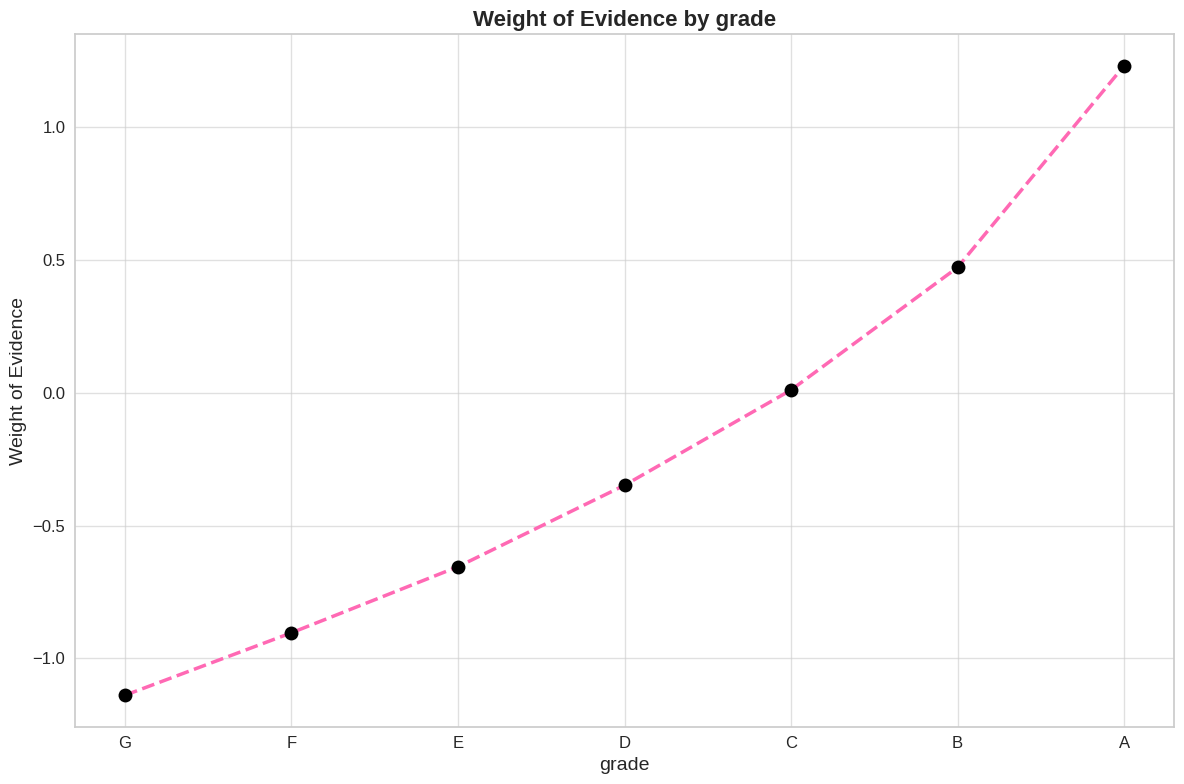

In [ ]:
#Analisis Fitur Grade
df_grade = woe_categorical(X, 'grade', y)
plot_by_woe(df_grade)

grafik di atas menunjukkan bahwa nilai-nilai tersebut memiliki perbedaan yang signifikan seiring dengan perubahan nilai. Oleh karena itu akan menyimpan setiap nilai sebagai fitur.

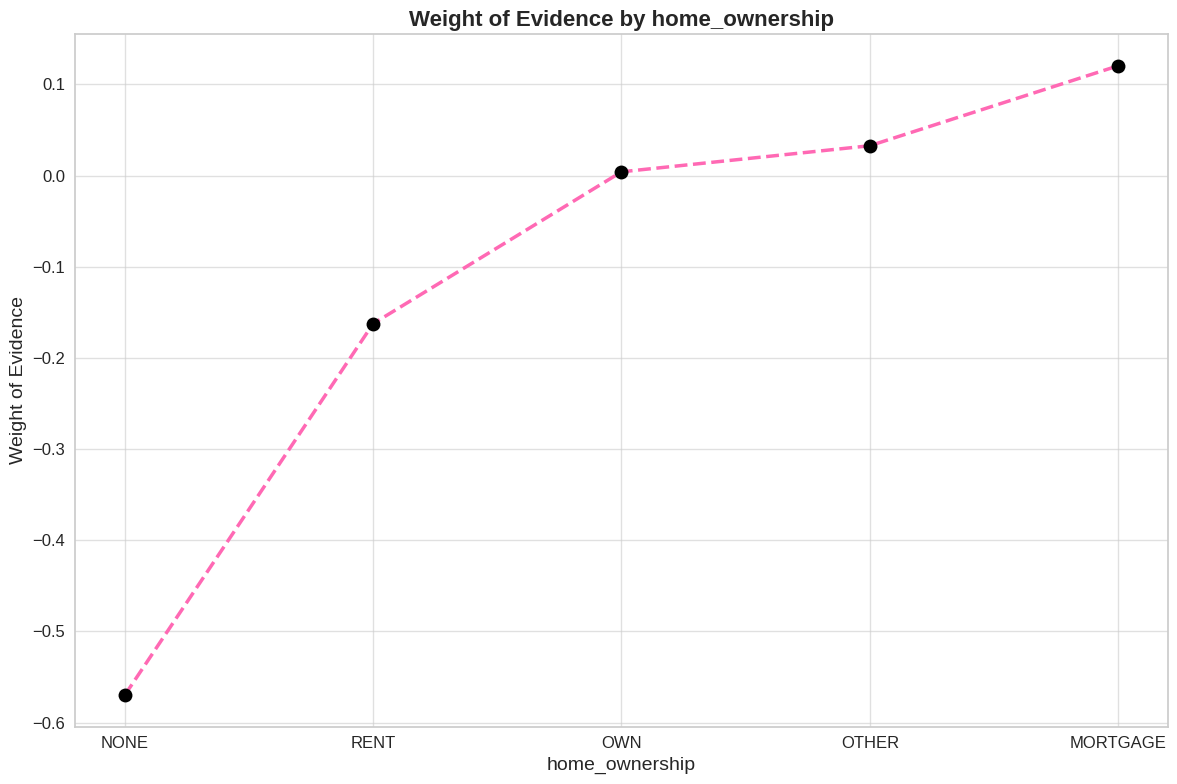

In [ ]:
#Analisis Fitur Home Ownership
df_home = woe_categorical(X, 'home_ownership', y)
plot_by_woe(df_home)


NONE dan OTHER memiliki pengamatan yang sangat sedikit dan harus digabungkan dengan kategori dengan risiko gagal bayar yang tinggi yaitu RENT

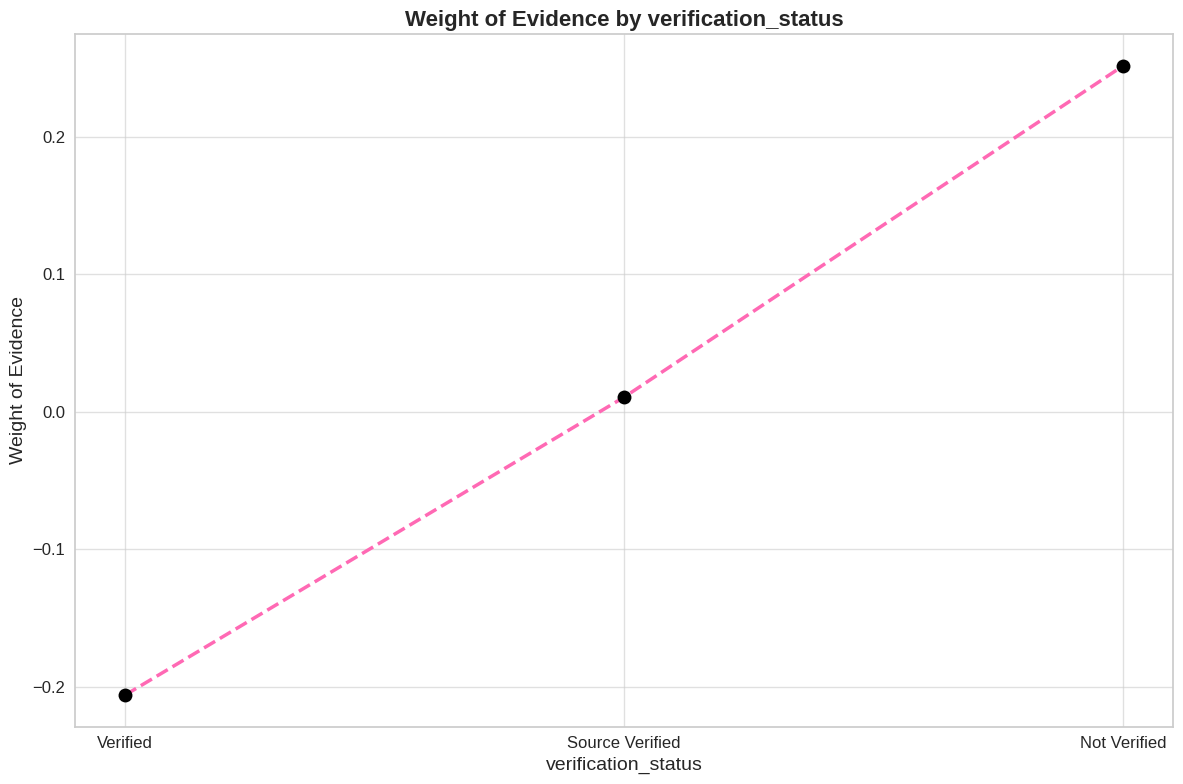

In [ ]:
#Analisis Fitur Verification Status
veri_df = woe_categorical(X, 'verification_status', y)
plot_by_woe(veri_df)


Variabel ini memiliki nilai WoE yang berbeda-beda dan dapat digunakan sebagai variabel tersendiri

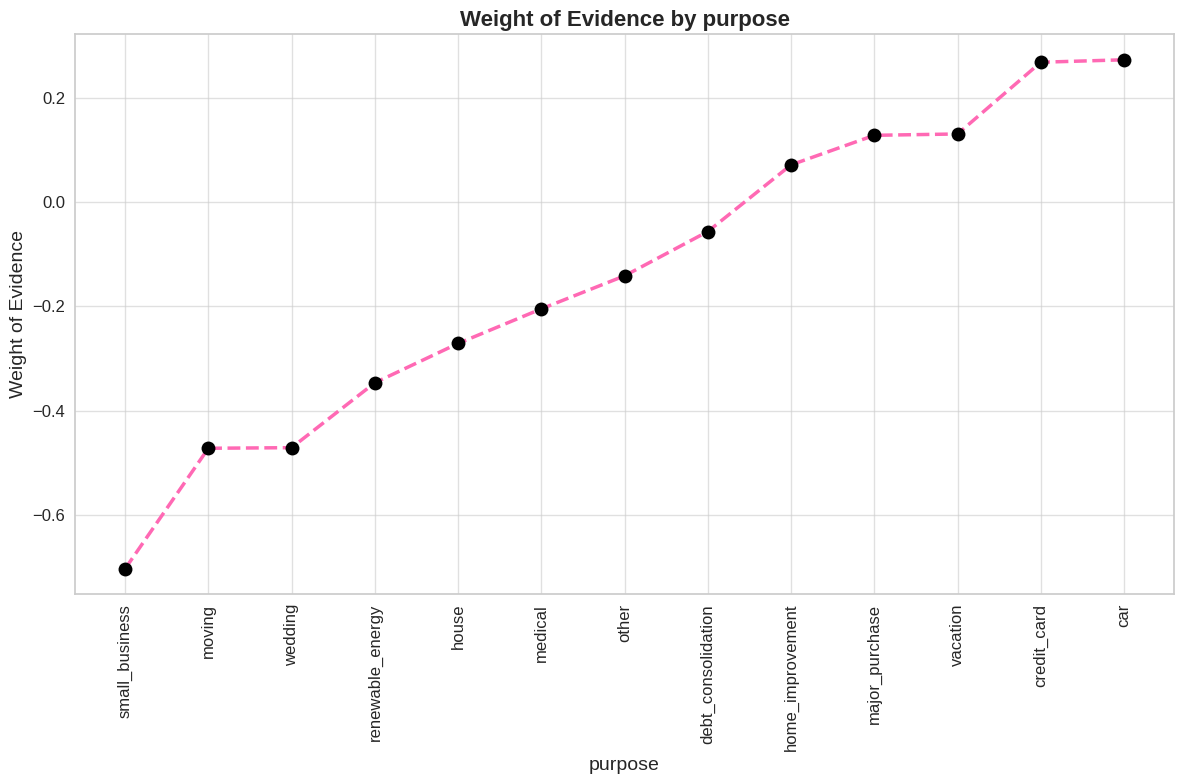

In [ ]:
df_pur = woe_categorical(X, 'purpose', y)
plot_by_woe(df_pur, 90)


kategori yang akan digabungkan menjadi satu :

educational, renewable_energy, moving, other,house, medical, weeding, vacation, debt_consolidation home_improvement, major purchase car, credit_card

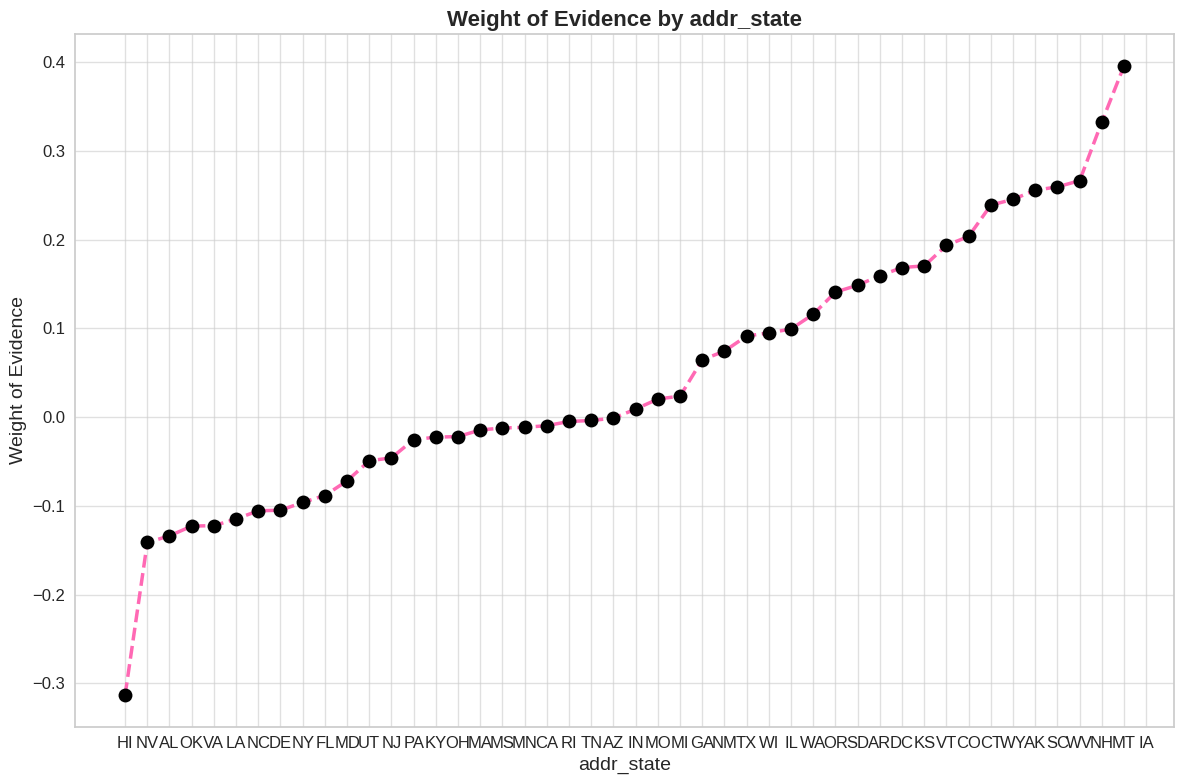

In [ ]:
#Fitur Addres
df_addr = woe_categorical(X, 'addr_state', y)
plot_by_woe(df_addr)

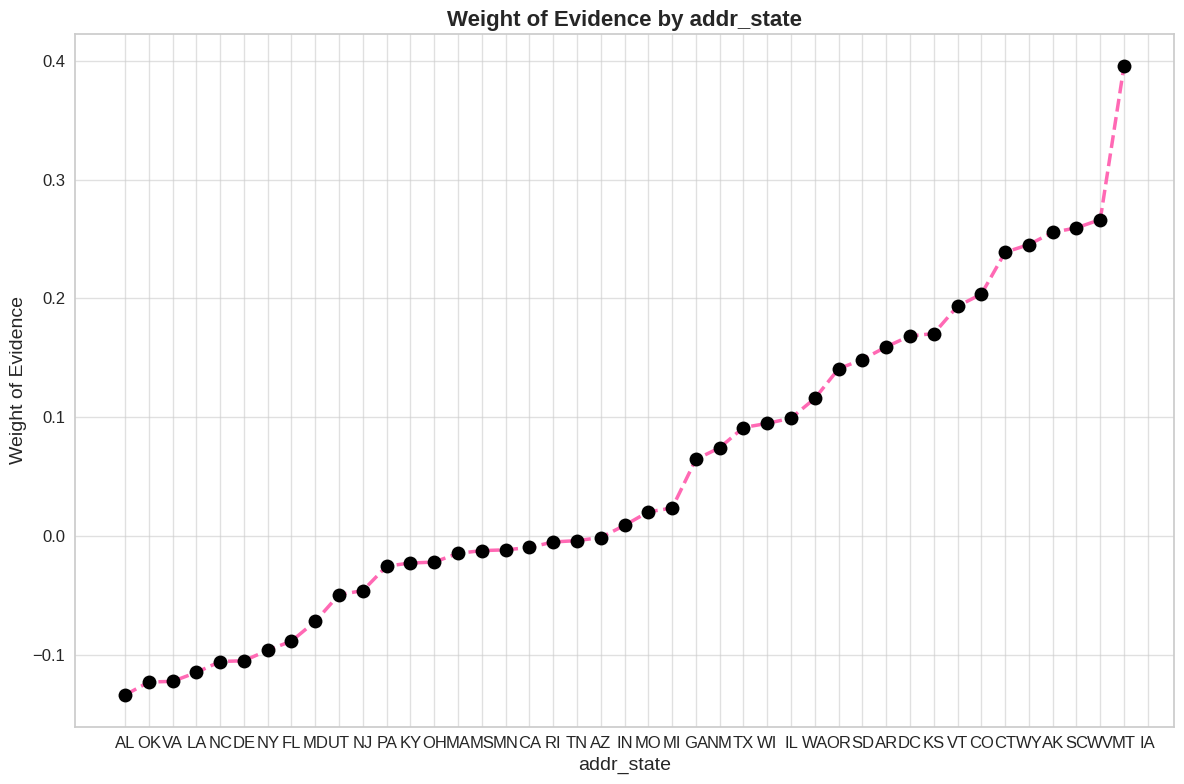

In [ ]:
data1 = df_addr.iloc[2:44, :]
data2 = df_addr.iloc[45:49, :]
low_data_woe = pd.concat([data1, data2], axis=0)
plot_by_woe(low_data_woe)

Kategori yang akan digabungkan sebagai berikut:

NE, IA, NV, HI, FL, AL NY LA, NM, OK, NC, MO, MD, NJ, VA CA AZ, MI, UT, TN, AR, PA RI, OH, KY, DE, MN, SD, MA, IN TIDAK, WA WI, ATAU TX IL, CT, MT CO, SC KS, VT, AK, MS NH, WV, WY, DC Secara total membuat 13 kategori untuk addr_variable

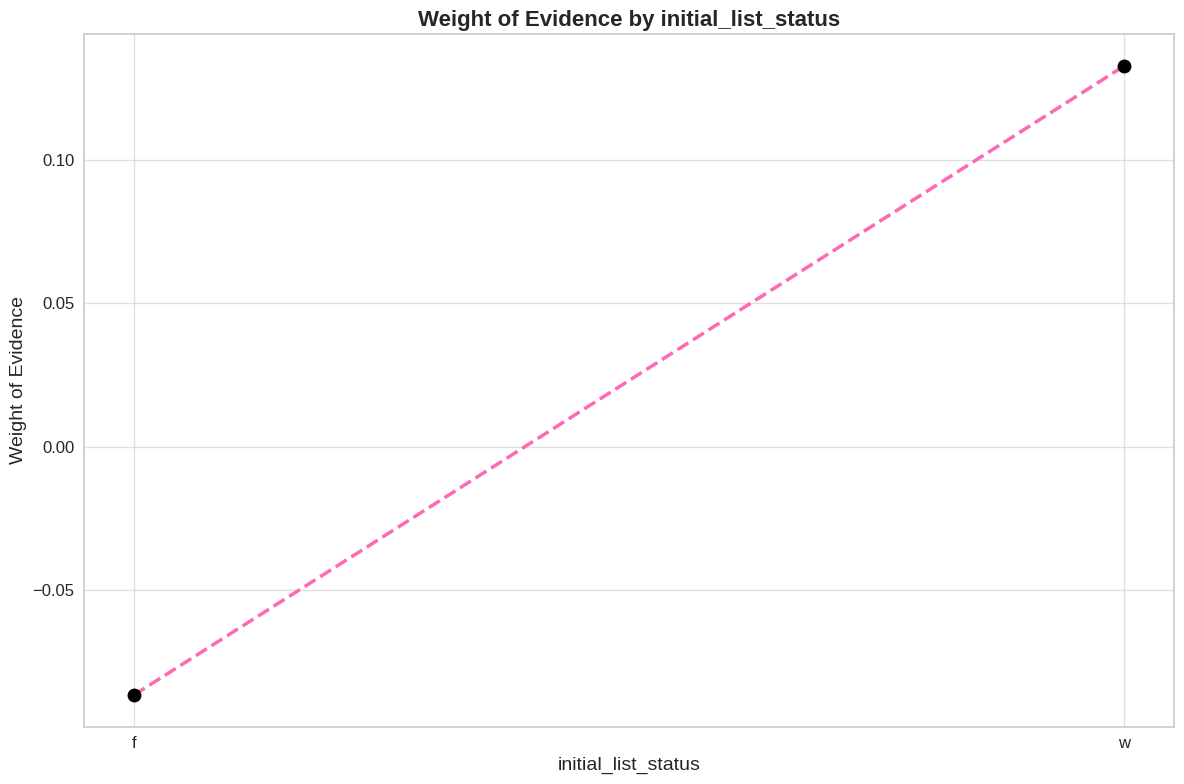

In [ ]:
df_init_list = woe_categorical( X, 'initial_list_status', y)
plot_by_woe(df_init_list)

Variabel ini memiliki nilai WoE yang berbeda secara signifikan dan kategori harus disimpan sebagai variabel terpisah

In [ ]:
# function to calculate WoE for continous variables
def woe_continous(df, cat_feature, good_bad_df):
    df = pd.concat([df[cat_feature], good_bad_df], axis=1)
    df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
                    df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)
    df = df.iloc[:, [0, 1, 3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']
    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()
    df['WoE'] = np.log(df['prop_n_good'] / df['prop_n_bad'])
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE'] = df['WoE'].diff().abs()
    df['IV'] = (df['prop_n_good'] - df['prop_n_bad']) * df['WoE']
    df['IV'] = df['IV'].sum()
    return df

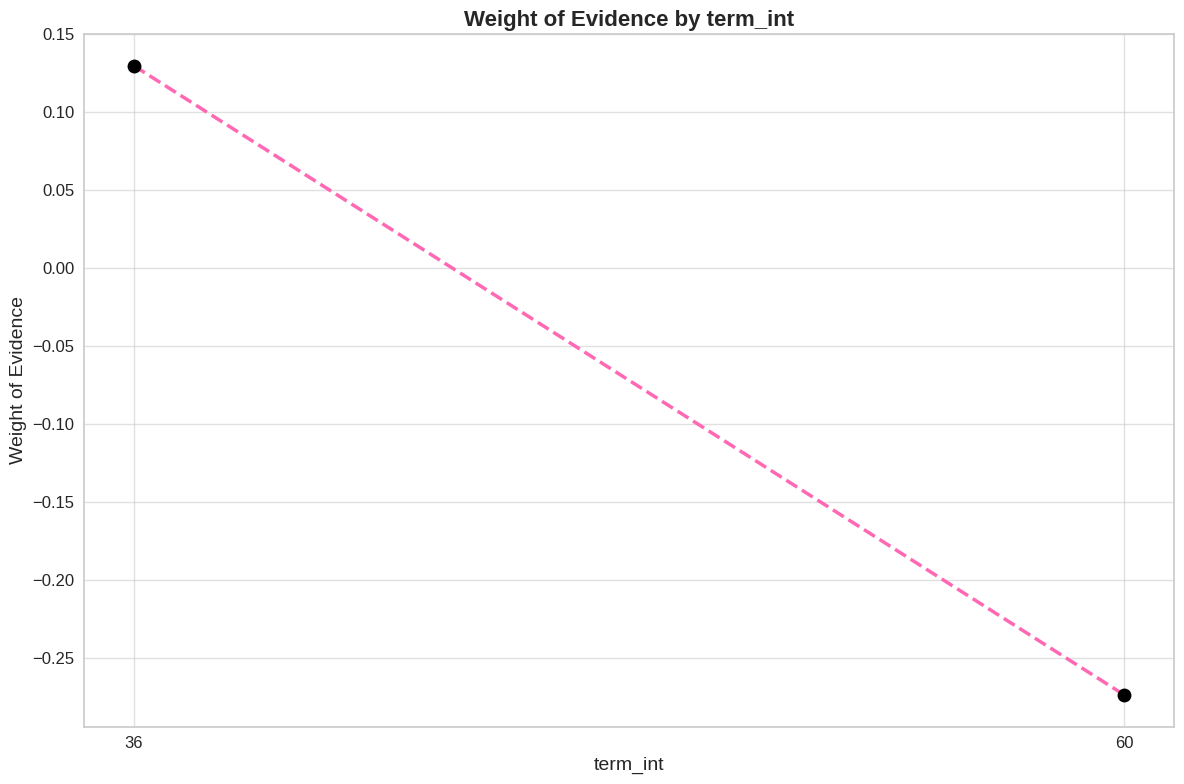

In [ ]:
plot_by_woe(woe_continous(X,'term_int', y ))

In [ ]:
X['mths_since_issue_d'].unique()

array([132., 133., 134., 135., 136., 137., 138., 139., 140., 141., 142.,
       143., 144., 145., 146., 147., 148., 120., 121., 122., 123., 124.,
       125., 126., 127., 128., 129., 130., 131.])

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


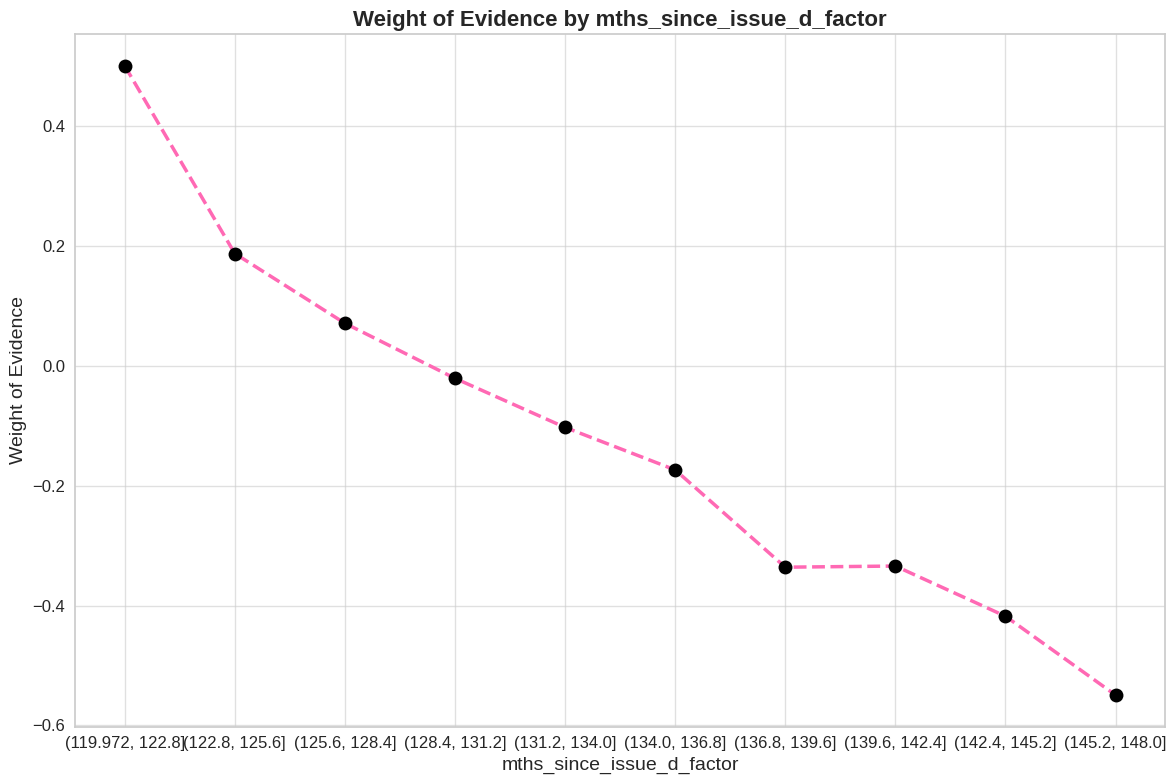

In [ ]:
X['mths_since_issue_d_factor'] = pd.cut(X['mths_since_issue_d'], 10)
df_mths_since_iss = woe_continous(X, 'mths_since_issue_d_factor', y)
plot_by_woe(df_mths_since_iss)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


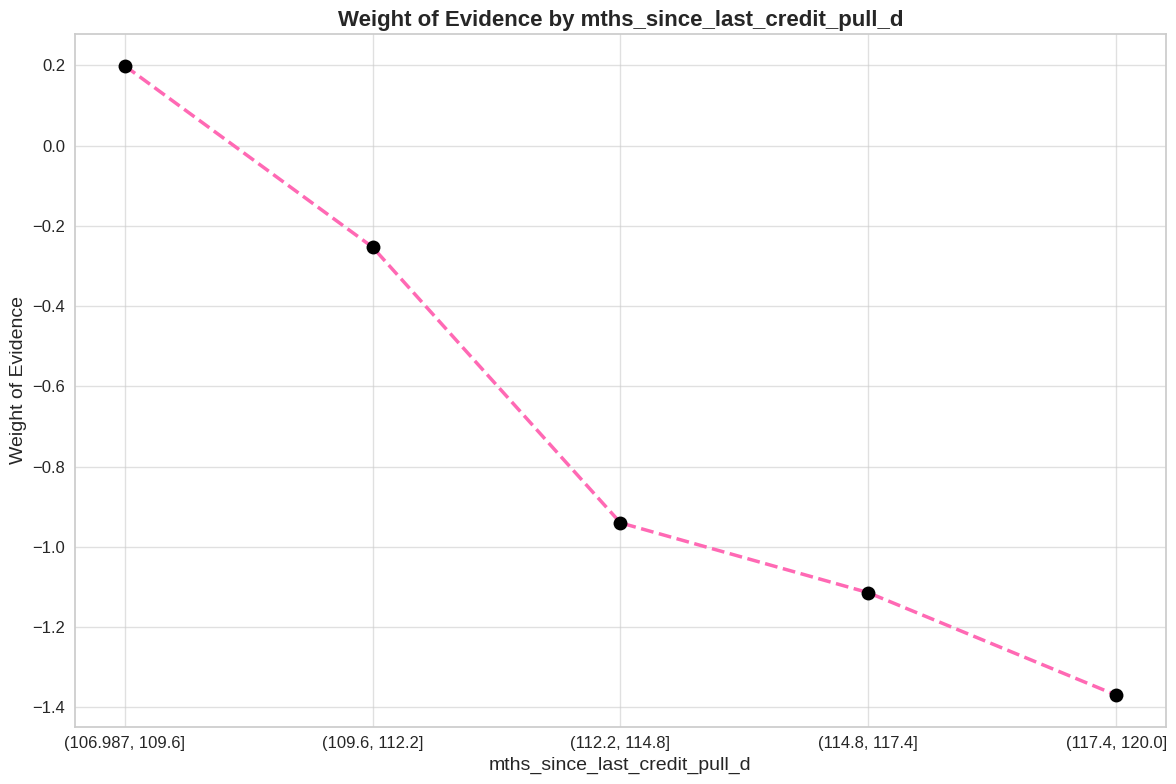

In [ ]:
# Memilih data dengan kondisi tertentu (mths_since_last_credit_pull_d <= 60)
X_train_prepr_temp = X[X['mths_since_last_credit_pull_d'] <= 120].copy()

# Pembagian kategori dengan pd.cut
X_train_prepr_temp['mths_since_last_credit_pull_d'] = pd.cut(X_train_prepr_temp['mths_since_last_credit_pull_d'], 5)

# Memastikan bahwa y sesuai dengan indeks X_train_prepr_temp
y_temp = y[X_train_prepr_temp.index]

# Menghitung WoE untuk fitur yang telah dibagi kategori
df_temp = woe_continous(X_train_prepr_temp, 'mths_since_last_credit_pull_d', y_temp)

# Plot hasil WoE
plot_by_woe(df_temp)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


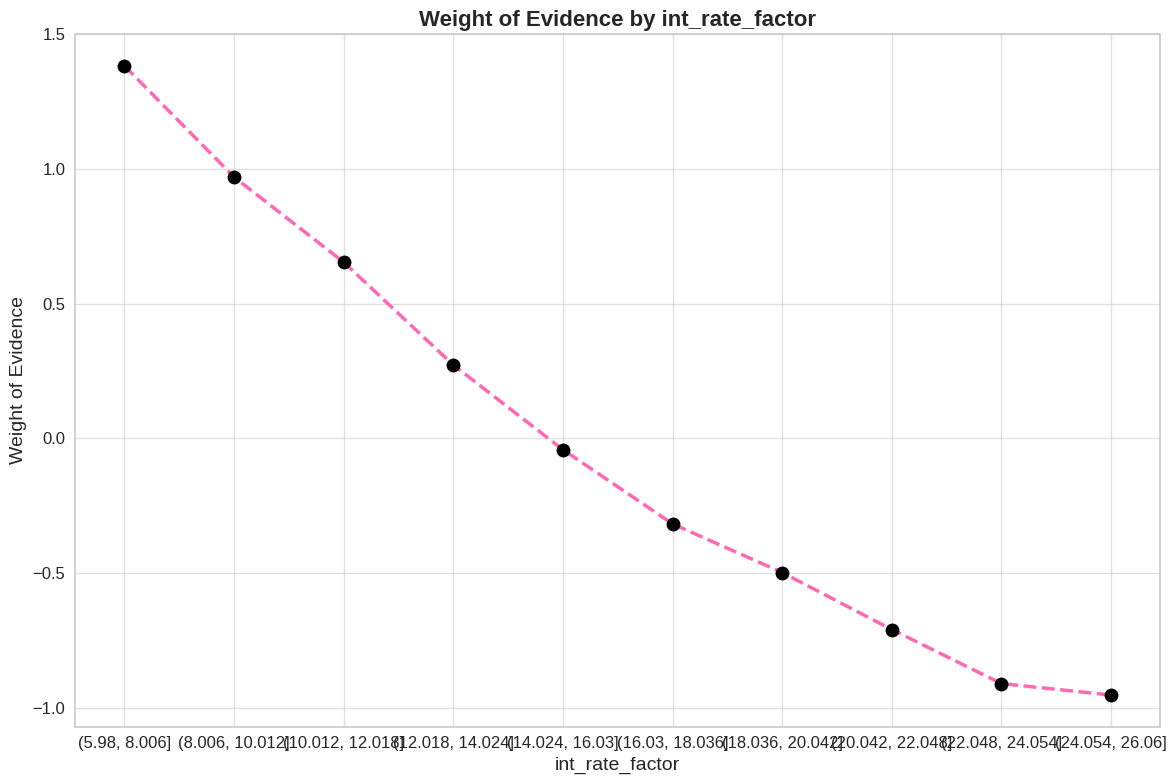

In [ ]:
X['int_rate_factor'] = pd.cut(X['int_rate'], 10)
df_int_rate = woe_continous(X, 'int_rate_factor',y)
plot_by_woe(df_int_rate)

Dari grafik di atas hanya dua kategori terakhir yang akan digabungkan.

(22.048, 26.06)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


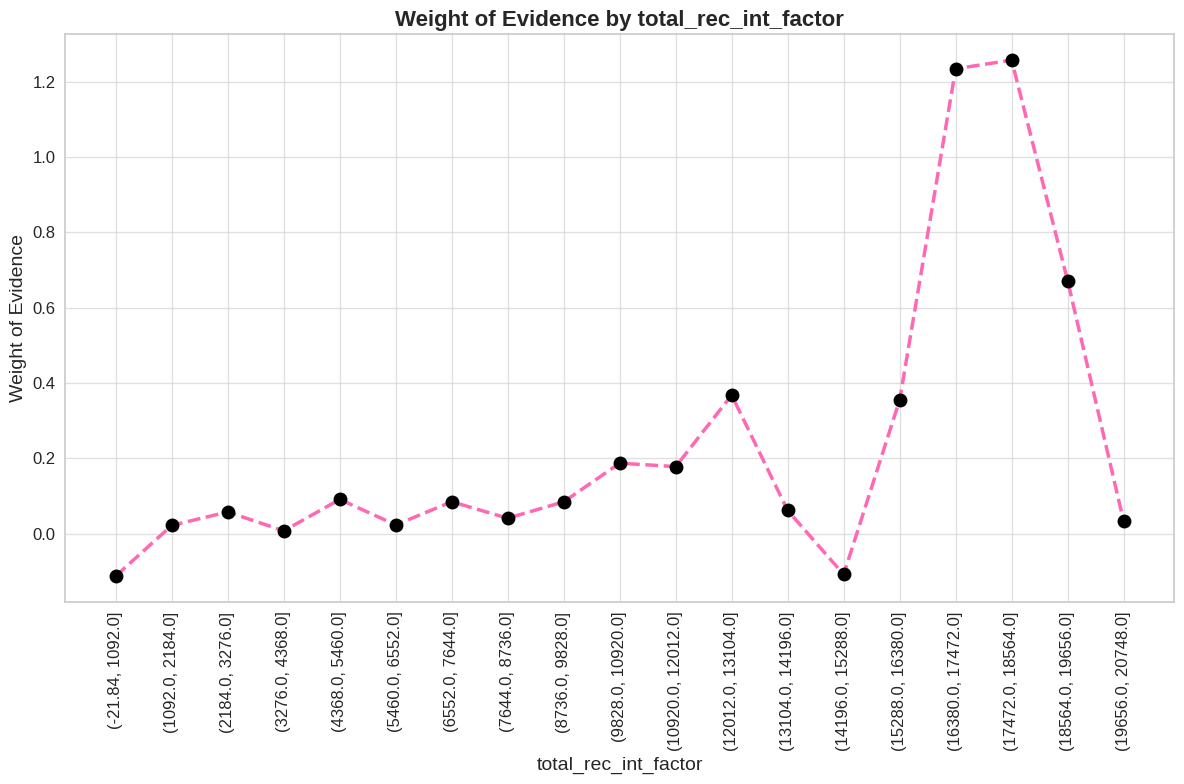

In [ ]:
X['total_rec_int_factor'] = pd.cut(X['total_rec_int'], 20)
df_rec_int = woe_continous(X, 'total_rec_int_factor', y)
plot_by_woe(df_rec_int, 90)

In [ ]:
X['total_rev_hi_lim_factor'] = pd.cut(X['total_rev_hi_lim'], 100)
df_revol_hi = woe_continous(X, 'total_rev_hi_lim_factor', y)
#plot_by_woe(revol_hi_df, 90)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


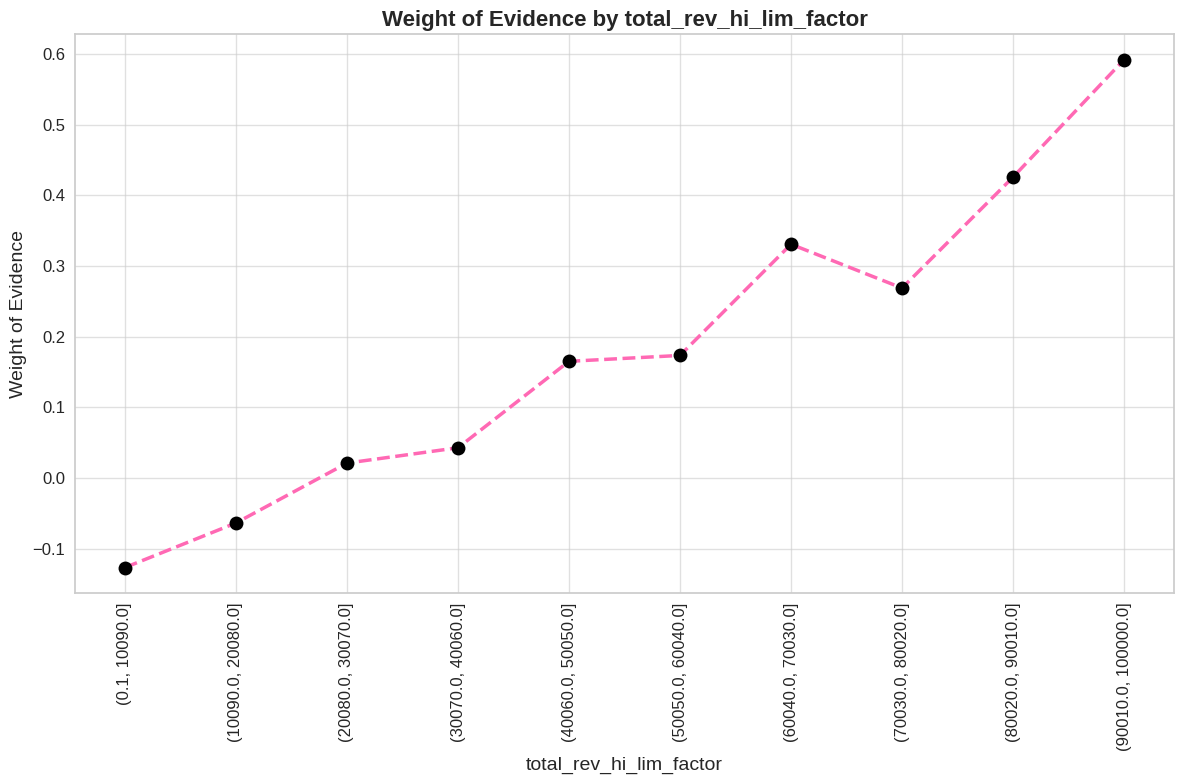

In [ ]:
#analyzing below 100000
X_train_prepr_temp = X[X['total_rev_hi_lim'] <= 100000].copy()
# fine-classing
X_train_prepr_temp['total_rev_hi_lim_factor'] = pd.cut(X_train_prepr_temp['total_rev_hi_lim'],10)
# select only the relevant index in the target col
df_temp = woe_continous(X_train_prepr_temp, 'total_rev_hi_lim_factor', y[X_train_prepr_temp.index])
plot_by_woe(df_temp, 90)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


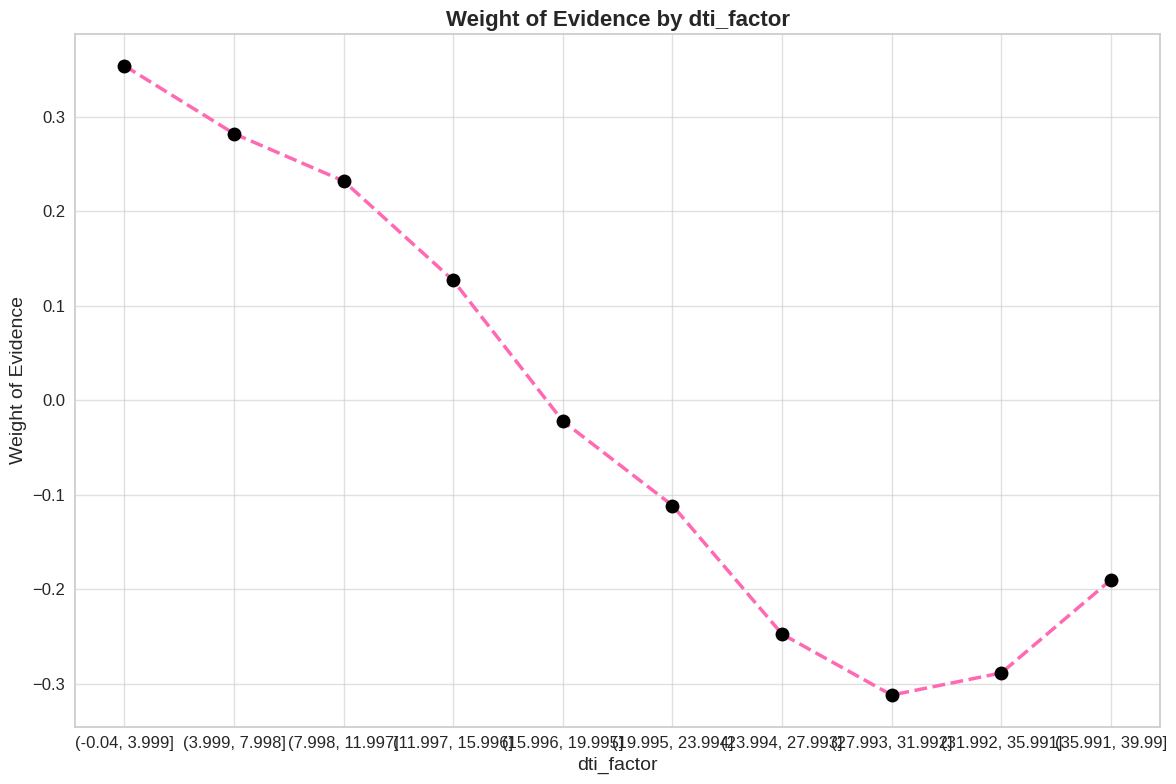

In [ ]:
X['dti_factor'] = pd.cut(X['dti'], 10)
df_dti = woe_continous(X, 'dti_factor', y)
plot_by_woe(df_dti)

Kategori akan digabungkan:

(27.993, 31.992), (31.992, 35.991), (35.991, 39.99)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


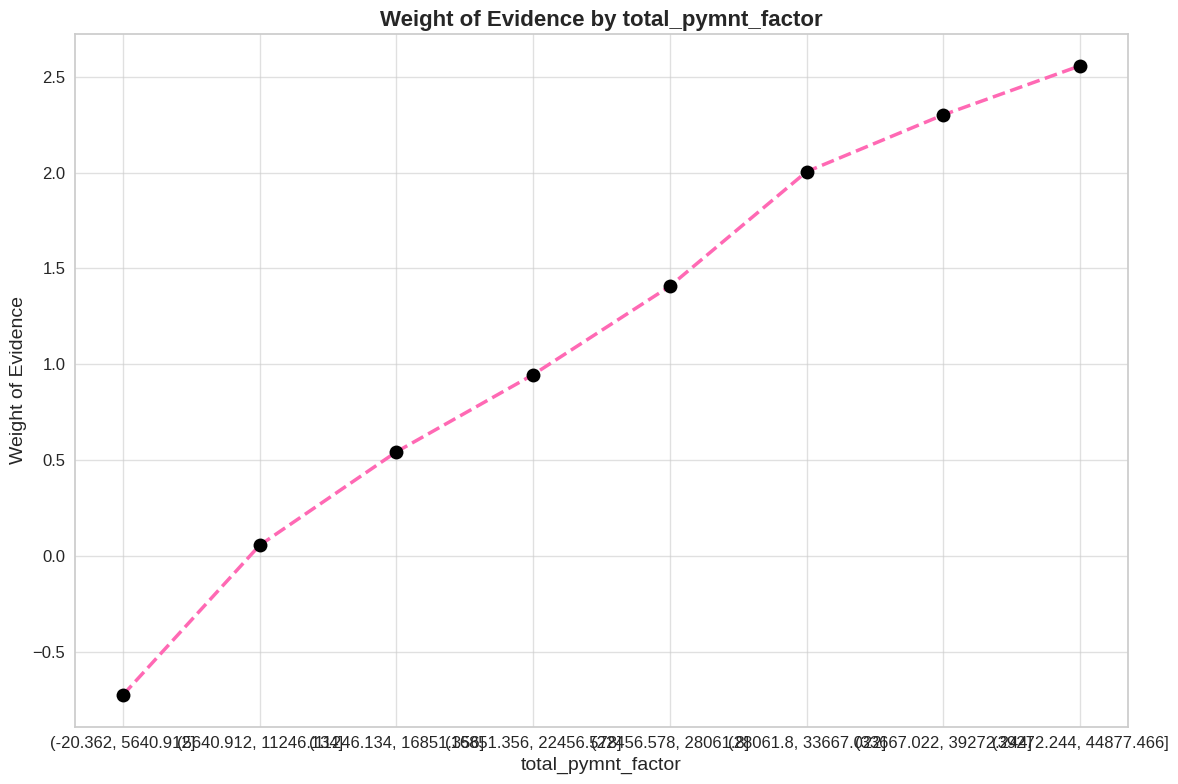

In [ ]:
X['total_pymnt_factor'] = pd.cut(X['total_pymnt'], 10)
df_total_pym = woe_continous(X, 'total_pymnt_factor', y)
plot_by_woe(df_total_pym)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


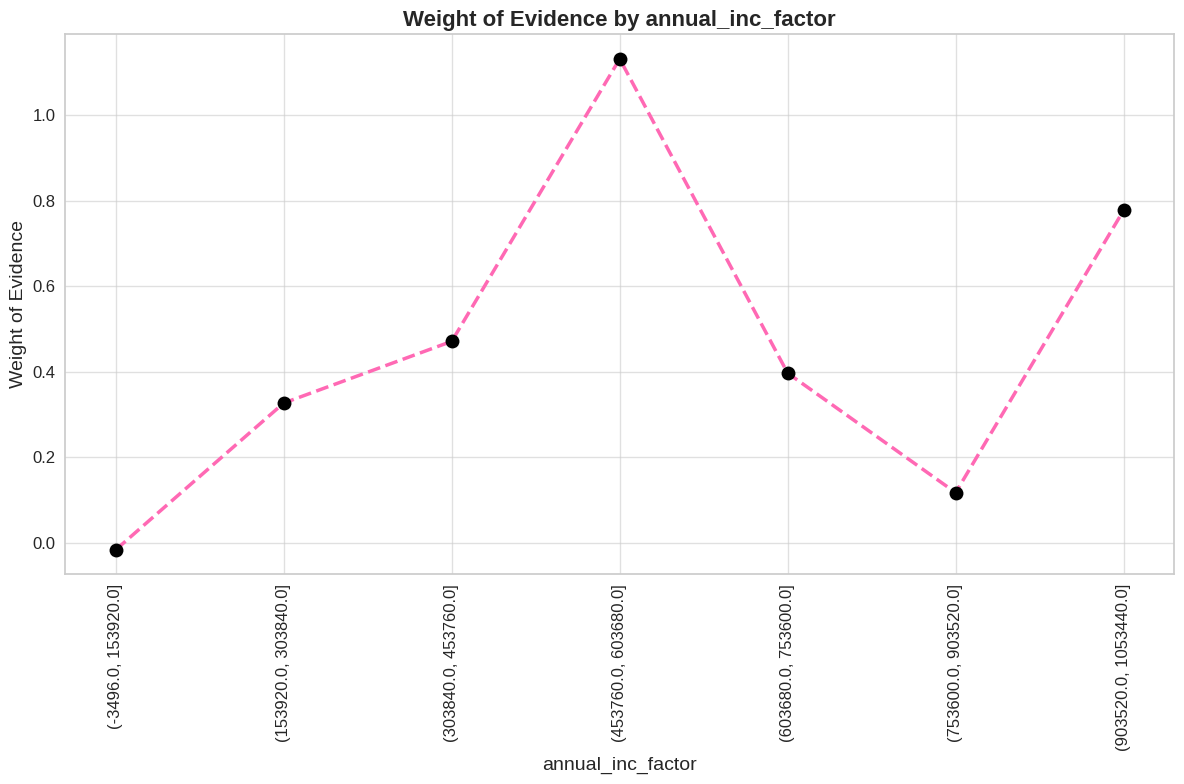

In [ ]:
X['annual_inc_factor'] = pd.cut(X['annual_inc'], 50)
df_ann_inc = woe_continous(X, 'annual_inc_factor', y)
plot_by_woe(df_ann_inc, 90)


Memisahkan variabel : orang-orang dengan pendapatan lebih tinggi dan lebih rendah. Dari tabel WoE kita mengamati, ketika pendapatan tahunan meningkat, jumlah observasi menurun. Sebab, hanya sedikit orang yang berpenghasilan tinggi, akan dibuat variabel baru untuk orang dengan pendapatan di atas 150.000 dolar. Dan juga, menganalisis individu dengan pendapatan di bawah 150.000 dolar.

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


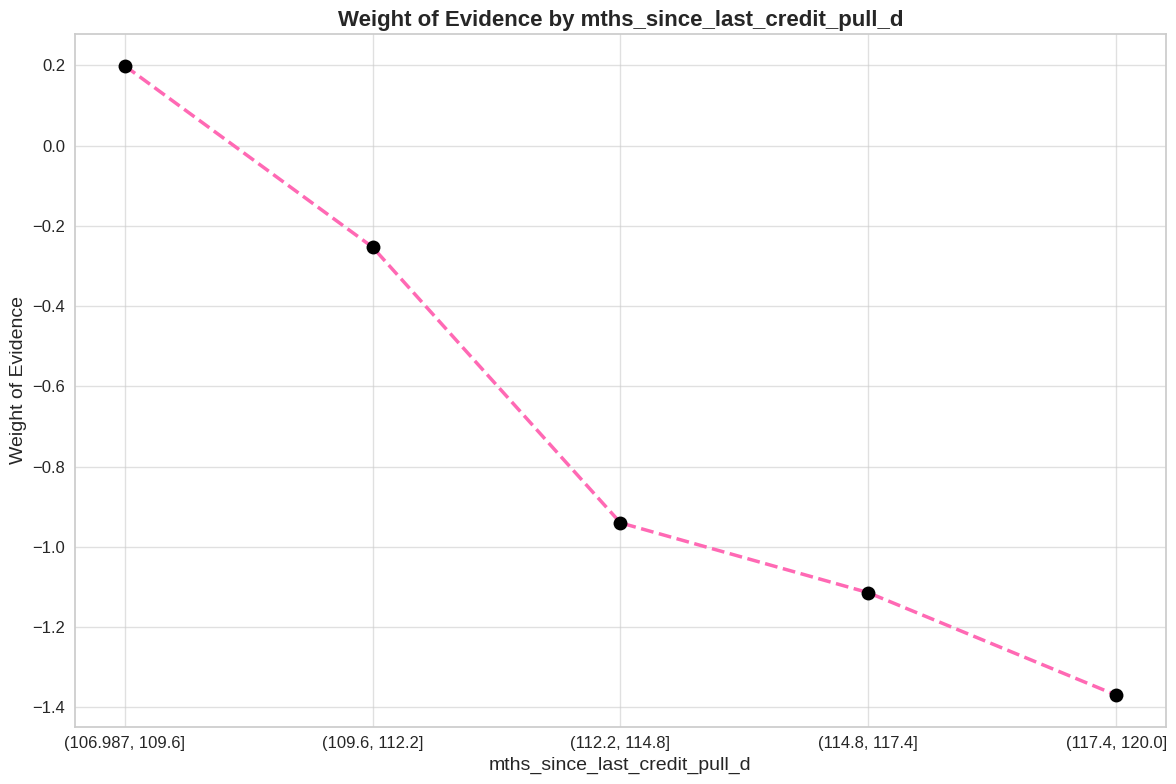

In [ ]:
# Memilih data dengan kondisi tertentu (mths_since_last_credit_pull_d <= 60)
X_train_prepr_temp = X[X['mths_since_last_credit_pull_d'] <= 120].copy()

# Pembagian kategori dengan pd.cut
X_train_prepr_temp['mths_since_last_credit_pull_d'] = pd.cut(X_train_prepr_temp['mths_since_last_credit_pull_d'], 5)

# Memastikan bahwa y sesuai dengan indeks X_train_prepr_temp
y_temp = y[X_train_prepr_temp.index]

# Menghitung WoE untuk fitur yang telah dibagi kategori
df_temp = woe_continous(X_train_prepr_temp, 'mths_since_last_credit_pull_d', y_temp)

# Plot hasil WoE
plot_by_woe(df_temp)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


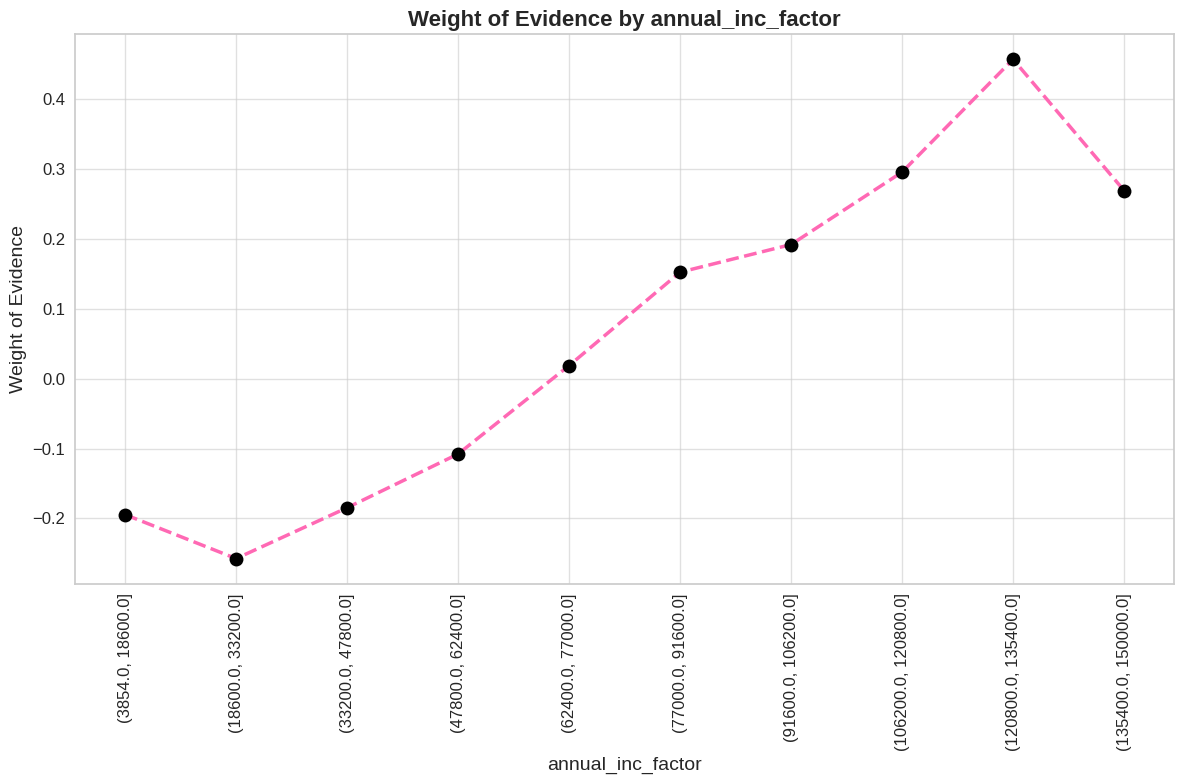

In [ ]:
#Analyzing income  below 150000
X_train_prepr_temp = X[X['annual_inc'] <= 150000].copy()
# fine-classing
X_train_prepr_temp['annual_inc_factor'] = pd.cut(X_train_prepr_temp['annual_inc'], 10)
# select only the relevant index in the target col
df_temp = woe_continous(X_train_prepr_temp, 'annual_inc_factor', y[X_train_prepr_temp.index])
plot_by_woe(df_temp, 90)

Menggabungkan kategori berikut berdasarkan WoE dan jumlah observasi sebagai berikut:

(<=32000), (>32000 <= 50000), (>50000 <= 60000), (>60000 <=75000), (>75000 <=90000), (>90000 <=120000), (>120000 <=135000), (>135000 <=150000), (>150000)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


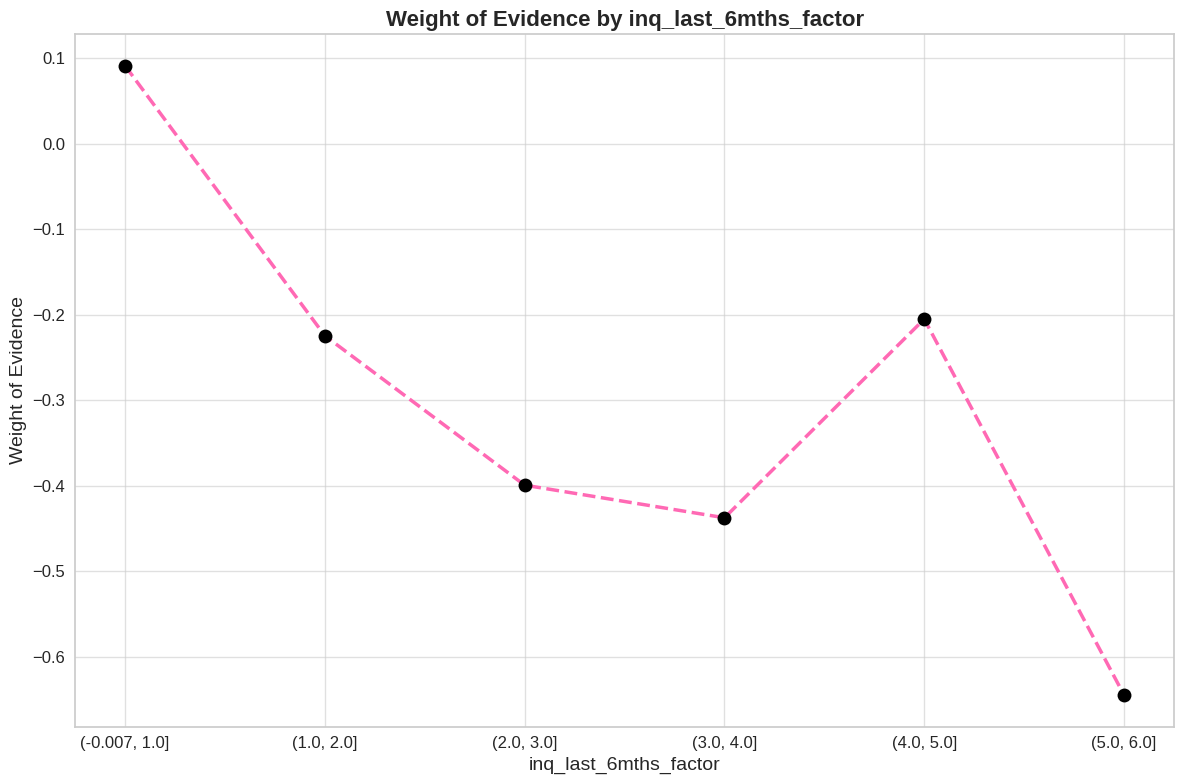

In [ ]:
X['inq_last_6mths_factor'] = pd.cut(X['inq_last_6mths'], 7)
df_inq_fact = woe_continous(X, 'inq_last_6mths_factor', y)
plot_by_woe(df_inq_fact)

Kategori berikut akan dibuat

< 1 bulan, 1-2, 2-4, 4-7

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


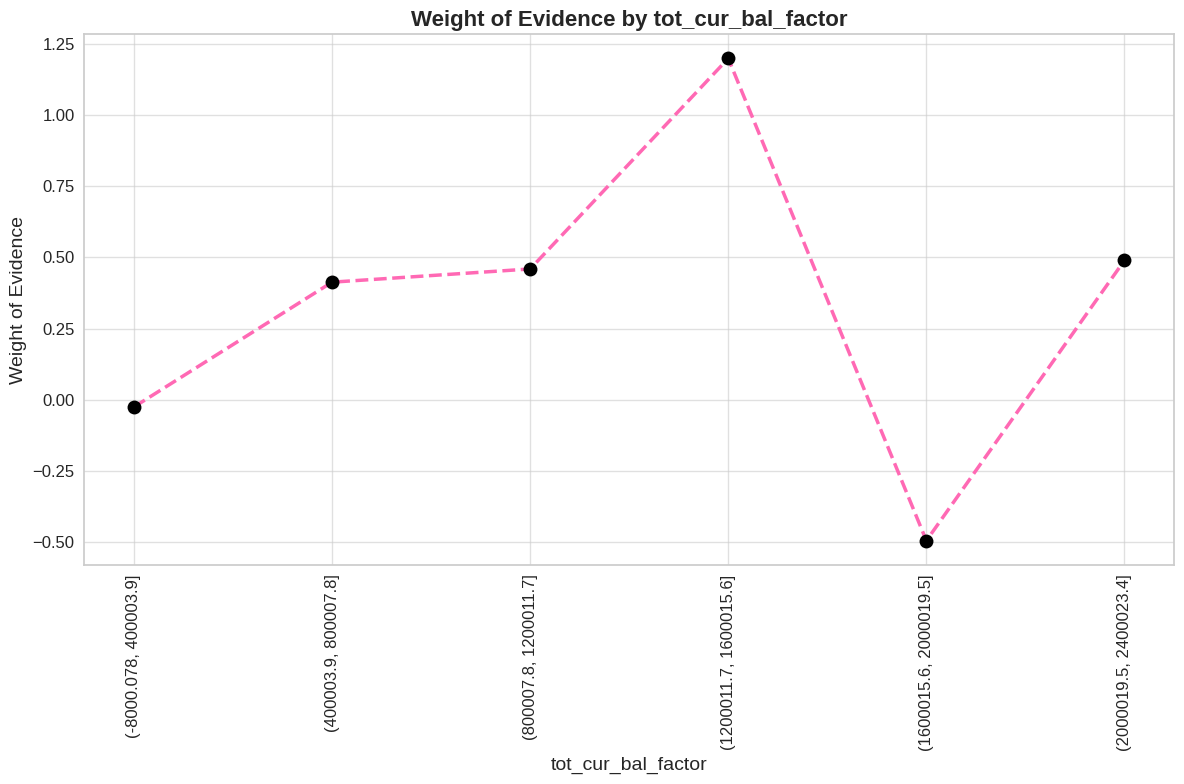

In [ ]:
X['tot_cur_bal_factor'] = pd.cut(X['tot_cur_bal'], 20)
df_curr_bal = woe_continous(X, 'tot_cur_bal_factor', y)
plot_by_woe(df_curr_bal, 90)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


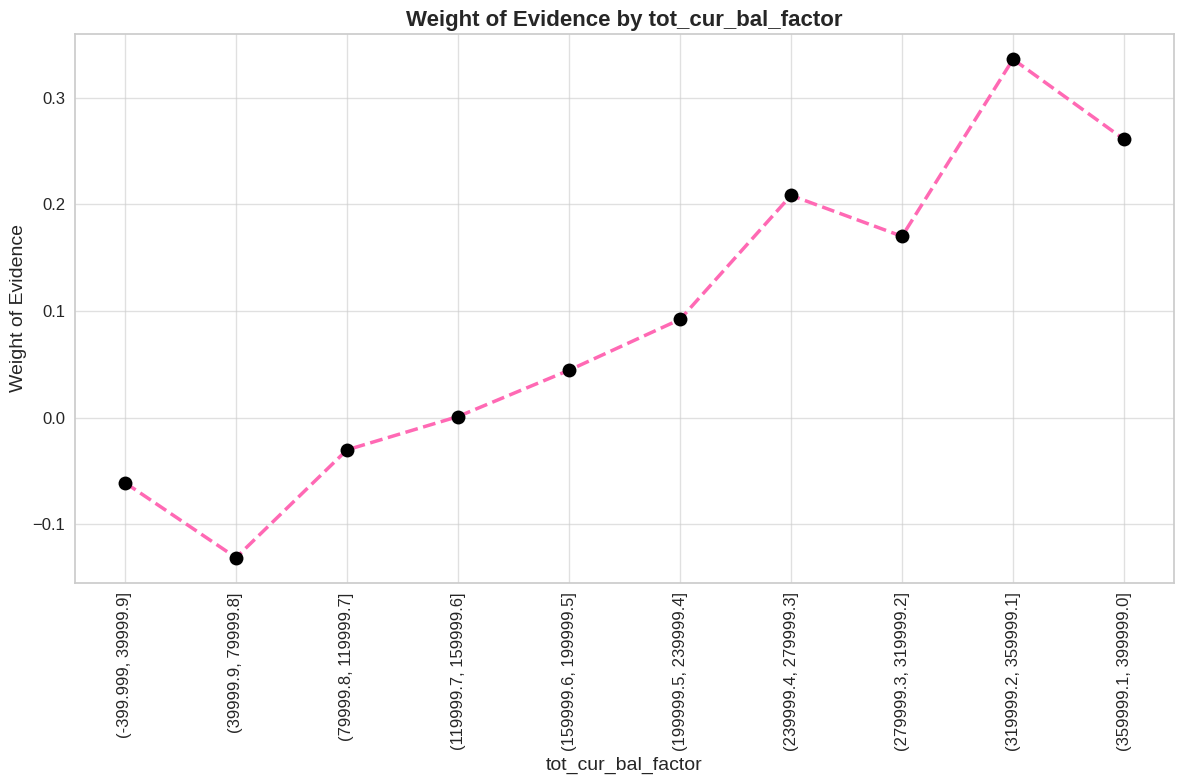

In [ ]:
#Analyzing current balance  below 400000
X_train_prepr_temp = X[X['tot_cur_bal'] <= 400000].copy()
# fine-classing
X_train_prepr_temp['tot_cur_bal_factor'] = pd.cut(X_train_prepr_temp['tot_cur_bal'], 10)
# select only the relevant index in the target column
df_temp = woe_continous(X_train_prepr_temp, 'tot_cur_bal_factor', y[X_train_prepr_temp.index])
plot_by_woe(df_temp, 90)

akan dibuat variabel :

<40000, 40000-80000, 80000-120000, 120000-160000, 160000-200000, 200000-240000, 240000-320000, 320000-400000

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


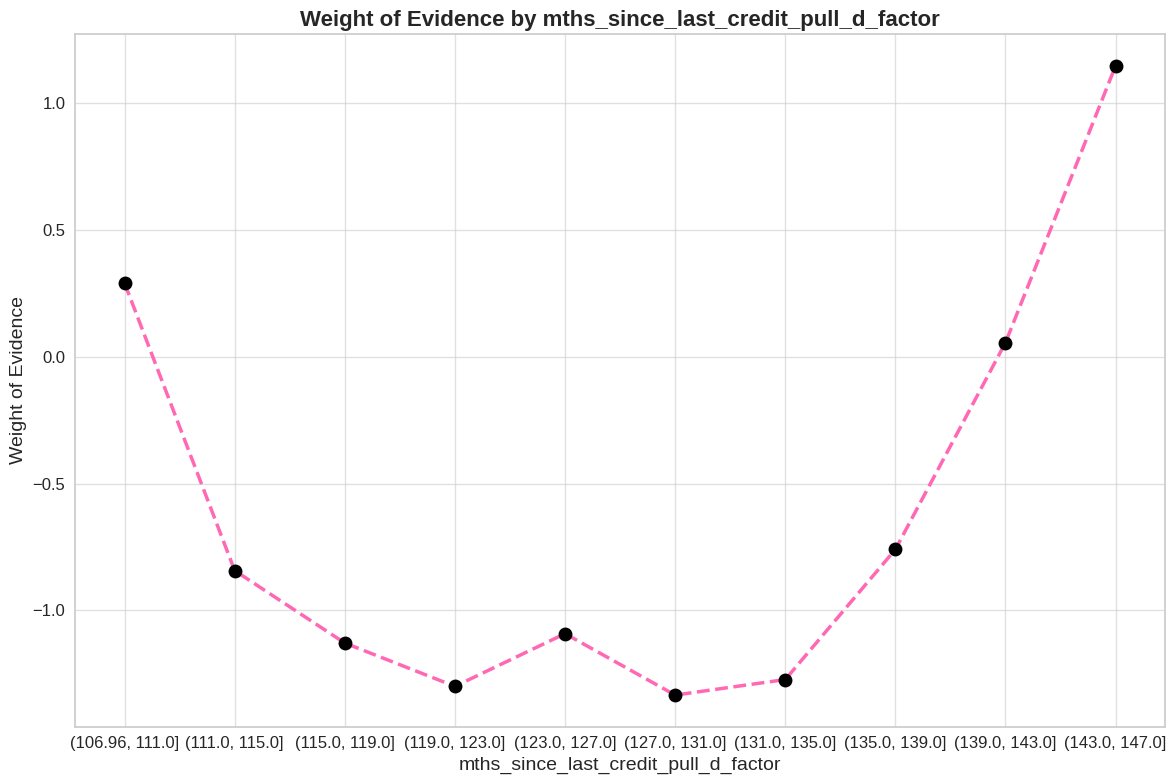

In [ ]:
X['mths_since_last_credit_pull_d_factor'] = pd.cut(X['mths_since_last_credit_pull_d'], 10)
df_mths_cr_pull = woe_continous(X, 'mths_since_last_credit_pull_d_factor', y)
plot_by_woe(df_mths_cr_pull)

In [ ]:
print("Jumlah data sebelum filter:", X['mths_since_last_credit_pull_d'].shape[0])
print("Jumlah data setelah filter (<= 60):", X_train_prepr_temp.shape[0])

Jumlah data sebelum filter: 181686
Jumlah data setelah filter (<= 60): 169249


In [ ]:
print(X['mths_since_last_credit_pull_d'].unique())

[107 112 110 108 115 109 128 117 123 124 116 111 127 121 119 120 125 130
 131 129 113 126 118 114 122 132 133 134 135 136 137 138 139 140 142 141
 143 144 145 146 147]


In [ ]:
# Pastikan ada data yang memenuhi kondisi
if X['mths_since_last_credit_pull_d'].le(60).sum() > 0:
    X_train_prepr_temp = X[X['mths_since_last_credit_pull_d'] <= 120].copy()

    # Pembagian kategori dengan pd.cut
    X_train_prepr_temp['mths_since_last_credit_pull_d'] = pd.cut(X_train_prepr_temp['mths_since_last_credit_pull_d'], 5)

    # Memastikan bahwa y sesuai dengan indeks X_train_prepr_temp
    y_temp = y[X_train_prepr_temp.index]

    # Menghitung WoE untuk fitur yang telah dibagi kategori
    df_temp = woe_continous(X_train_prepr_temp, 'mths_since_last_credit_pull_d', y_temp)

    # Plot hasil WoE
    plot_by_woe(df_temp)
else:
    print("Tidak ada data yang memenuhi kondisi mths_since_last_credit_pull_d <= 120")

Tidak ada data yang memenuhi kondisi mths_since_last_credit_pull_d <= 120


/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


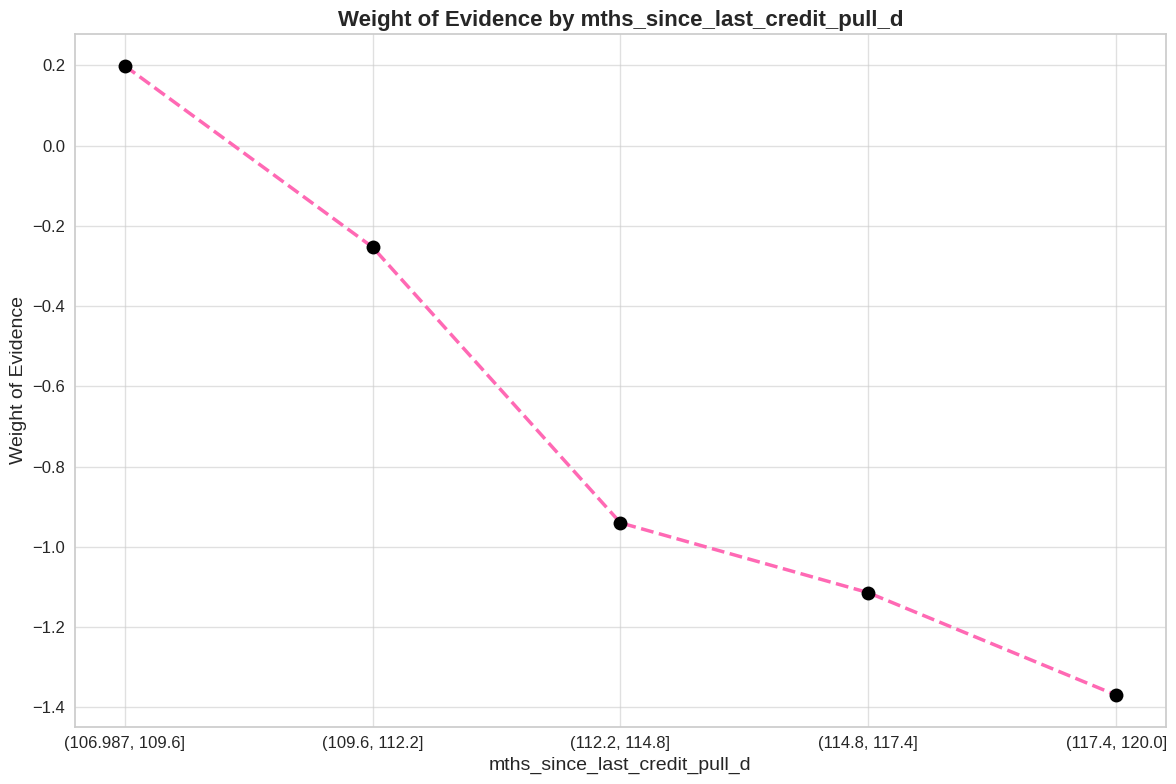

In [ ]:
# Memilih data dengan kondisi tertentu (mths_since_last_credit_pull_d <= 60)
X_train_prepr_temp = X[X['mths_since_last_credit_pull_d'] <= 120].copy()

# Pembagian kategori dengan pd.cut
X_train_prepr_temp['mths_since_last_credit_pull_d'] = pd.cut(X_train_prepr_temp['mths_since_last_credit_pull_d'], 5)

# Memastikan bahwa y sesuai dengan indeks X_train_prepr_temp
y_temp = y[X_train_prepr_temp.index]

# Menghitung WoE untuk fitur yang telah dibagi kategori
df_temp = woe_continous(X_train_prepr_temp, 'mths_since_last_credit_pull_d', y_temp)

# Plot hasil WoE
plot_by_woe(df_temp)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


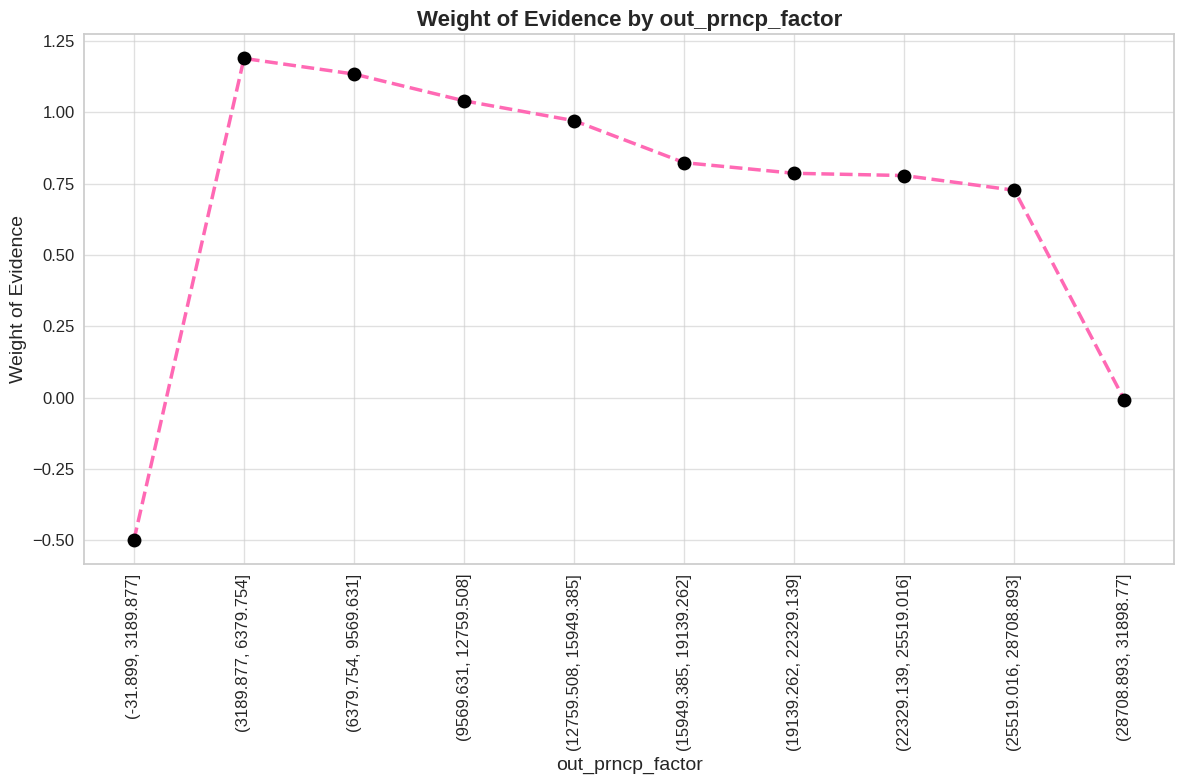

In [ ]:
X['out_prncp_factor'] = pd.cut(X['out_prncp'], 10)
df_out = woe_continous(X, 'out_prncp_factor', y)
plot_by_woe(df_out, 90)

/tmp/ipykernel_2190/1719959547.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = pd.concat([df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].count(),
/tmp/ipykernel_2190/1719959547.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index = False)[df.columns.values[1]].mean()], axis = 1)


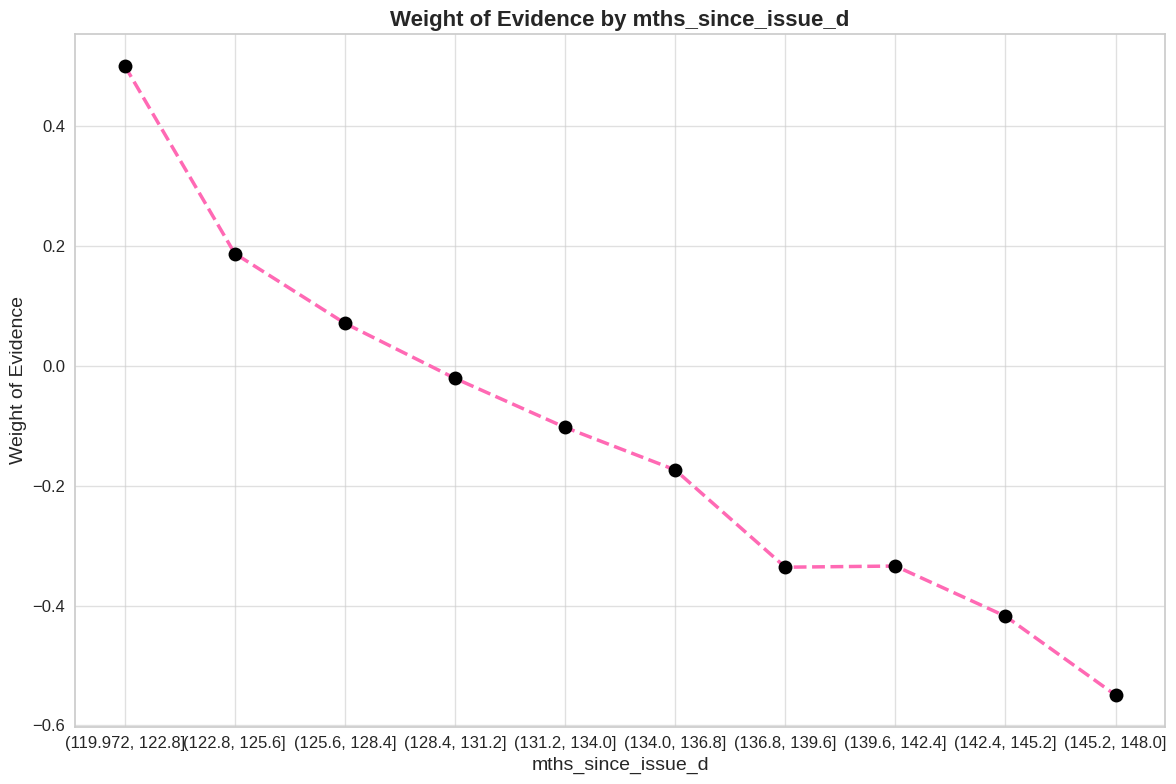

In [ ]:
X['mths_since_issue_d'] = pd.cut(X['mths_since_issue_d'], 10)
df_iss = woe_continous(X, 'mths_since_issue_d', y)
plot_by_woe(df_iss)

In [ ]:
df_new = preprocess_data.loc[:, 'grade:A':'grade:G']

# home_ownership
df_new['home_ownership:OWN'] = preprocess_data.loc[:, 'home_ownership:OWN']
df_new['home_ownership:OTHER_NONE_RENT_ANY'] = sum([preprocess_data['home_ownership:OTHER'],
                                                    preprocess_data['home_ownership:NONE'],
                                                    preprocess_data['home_ownership:RENT'],
                                                    preprocess_data['home_ownership:ANY']])
df_new['home_ownership:MORTGAGE'] = preprocess_data.loc[:, 'home_ownership:MORTGAGE']

# verification status
df_new['verification_status:NOT_VERIFIED'] = preprocess_data.loc[:, 'verification_status:Not Verified']
df_new['verification_status:SOURCE_VERIFIED'] = preprocess_data.loc[:, 'verification_status:Source Verified']
df_new['verification_status:VERIFIED'] = preprocess_data.loc[:, 'verification_status:Verified']

# purpose of loan
df_new['purpose:SMALL_BUSINESS_EDUCATIONAL_RENEWABLE_ENERGY_MOVING'] = sum([
    preprocess_data['purpose:small_business'],
    preprocess_data['purpose:renewable_energy'],
    preprocess_data['purpose:moving']
])
df_new['purpose:OTHER_HOUSE_MEDICAL'] = sum([
    preprocess_data['purpose:other'],
    preprocess_data['purpose:house'],
    preprocess_data['purpose:medical']
])
df_new['purpose:WEDDING_VACATION'] = sum([
    preprocess_data['purpose:wedding'],
    preprocess_data['purpose:vacation']
])
df_new['purpose:HOME_IMPROVEMENT_MAJOR_PURCHASE'] = sum([
    preprocess_data['purpose:home_improvement'],
    preprocess_data['purpose:major_purchase']
])
df_new['purpose:CAR_CREDIT_CARD'] = sum([
    preprocess_data['purpose:car'],
    preprocess_data['purpose:credit_card']
])

# addr state
df_new['addr_state:NE_IA_NV_HI_FL_AL'] = sum([
    preprocess_data['addr_state:IA'],
    preprocess_data['addr_state:NV'],
    preprocess_data['addr_state:HI'],
    preprocess_data['addr_state:FL'],
    preprocess_data['addr_state:AL']
])
df_new['addr_state:NY'] = preprocess_data.loc[:, 'addr_state:NY']
df_new['addr_state:LA_NM_OK_NC_MO_MD_NJ_VA'] = sum([
    preprocess_data['addr_state:LA'],
    preprocess_data['addr_state:NM'],
    preprocess_data['addr_state:OK'],
    preprocess_data['addr_state:NC'],
    preprocess_data['addr_state:MO'],
    preprocess_data['addr_state:MD'],
    preprocess_data['addr_state:NJ'],
    preprocess_data['addr_state:VA']
])
df_new['addr_state:CA'] = preprocess_data.loc[:, 'addr_state:CA']
df_new['addr_state:AZ_MI_UT_TN_AR_PA'] = sum([
    preprocess_data['addr_state:AZ'],
    preprocess_data['addr_state:MI'],
    preprocess_data['addr_state:UT'],
    preprocess_data['addr_state:TN'],
    preprocess_data['addr_state:AR'],
    preprocess_data['addr_state:PA']
])

df_new['addr_state:RI_OH_KY_DE_MN_SD_MA_IN'] = sum([
    preprocess_data['addr_state:RI'],
    preprocess_data['addr_state:OH'],
    preprocess_data['addr_state:KY'],
    preprocess_data['addr_state:DE'],
    preprocess_data['addr_state:MN'],
    preprocess_data['addr_state:SD'],
    preprocess_data['addr_state:MA'],
    preprocess_data['addr_state:IN']
])

df_new['addr_state:GA_WA'] = sum([
    preprocess_data['addr_state:GA'],
    preprocess_data['addr_state:WA']
])
df_new['addr_state:WI_OR'] = sum([
    preprocess_data['addr_state:WI'],
    preprocess_data['addr_state:OR']
])
df_new['addr_state:TX'] = preprocess_data.loc[:, 'addr_state:TX']
df_new['addr_state:IL_CT_MT'] = sum([
    preprocess_data['addr_state:IL'],
    preprocess_data['addr_state:CT'],
    preprocess_data['addr_state:MT']
])
df_new['addr_state:CO_SC'] = sum([
    preprocess_data['addr_state:CO'],
    preprocess_data['addr_state:SC']
])
df_new['addr_state:KS_VT_AK_NS'] = sum([
    preprocess_data['addr_state:KS'],
    preprocess_data['addr_state:VT'],
    preprocess_data['addr_state:AK'],
    preprocess_data['addr_state:MS']
])
df_new['addr_state:NH_WV_WY_DC'] = sum([
    preprocess_data['addr_state:NH'],
    preprocess_data['addr_state:WV'],
    preprocess_data['addr_state:WY'],
    preprocess_data['addr_state:DC']
])

# initial_list_status
df_new['initial_list_status:F'] = preprocess_data.loc[:, 'initial_list_status:f']
df_new['initial_list_status:W'] = preprocess_data.loc[:, 'initial_list_status:w']

# term
df_new['term:36'] = np.where((preprocess_data['term'] == 36), 1, 0)
df_new['term:60'] = np.where((preprocess_data['term'] == 60), 1, 0)

# total_rec_int
df_new['total_rec_int:<1000'] = np.where((preprocess_data['total_rec_int'] <= 1000), 1, 0)
df_new['total_rec_int:1000-2000'] = np.where((preprocess_data['total_rec_int'] > 1000) & (preprocess_data['total_rec_int'] <= 2000), 1, 0)
df_new['total_rec_int:2000-9000'] = np.where((preprocess_data['total_rec_int'] > 2000) & (preprocess_data['total_rec_int'] <= 9000), 1, 0)
df_new['total_rec_int:>9000'] = np.where((preprocess_data['total_rec_int'] > 9000), 1, 0)

# total_revol_hi_lim
df_new['total_rev_hi_lim:<10000'] = np.where((preprocess_data['total_rev_hi_lim'] <= 10000), 1, 0)
df_new['total_rev_hi_lim:10000-20000'] = np.where((preprocess_data['total_rev_hi_lim'] > 10000) & (preprocess_data['total_rev_hi_lim'] <= 20000), 1, 0)
df_new['total_rev_hi_lim:20000-40000'] = np.where((preprocess_data['total_rev_hi_lim'] > 20000) & (preprocess_data['total_rev_hi_lim'] <= 40000), 1, 0)
df_new['total_rev_hi_lim:40000-60000'] = np.where((preprocess_data['total_rev_hi_lim'] > 40000) & (preprocess_data['total_rev_hi_lim'] <= 60000), 1, 0)
df_new['total_rev_hi_lim:60000-80000'] = np.where((preprocess_data['total_rev_hi_lim'] > 60000) & (preprocess_data['total_rev_hi_lim'] <= 80000), 1, 0)
df_new['total_rev_hi_lim:80000-100000'] = np.where((preprocess_data['total_rev_hi_lim'] > 80000) & (preprocess_data['total_rev_hi_lim'] <= 100000), 1, 0)
df_new['total_rev_hi_lim:<100000'] = np.where((preprocess_data['total_rev_hi_lim'] > 100000), 1, 0)

# total_pymnt
df_new['total_pymnt:<5000'] = np.where((preprocess_data['total_pymnt'] <= 5000), 1, 0)
df_new['total_pymnt:5000-11000'] = np.where((preprocess_data['total_pymnt'] > 5000) & (preprocess_data['total_pymnt'] <= 11000), 1, 0)
df_new['total_pymnt:11000-16000'] = np.where((preprocess_data['total_pymnt'] > 11000) & (preprocess_data['total_pymnt'] <= 16000), 1, 0)
df_new['total_pymnt:16000-22000'] = np.where((preprocess_data['total_pymnt'] > 16000) & (preprocess_data['total_pymnt'] <= 22000), 1, 0)
df_new['total_pymnt:>22000'] = np.where((preprocess_data['total_pymnt'] > 22000), 1, 0)

# int_Rate
df_new['int_rate:<7.484'] = np.where((preprocess_data['int_rate'] <= 7.484), 1, 0)
df_new['int_rate:7.484-9.548'] = np.where((preprocess_data['int_rate'] > 7.484) & (preprocess_data['int_rate'] <= 9.548), 1, 0)
df_new['int_rate:9.548-11.612'] = np.where((preprocess_data['int_rate'] > 9.548) & (preprocess_data['int_rate'] <= 11.612), 1, 0)
df_new['int_rate:11.612-13.676'] = np.where((preprocess_data['int_rate'] > 11.612) & (preprocess_data['int_rate'] <= 13.676), 1, 0)
df_new['int_rate:13.676-15.74'] = np.where((preprocess_data['int_rate'] > 13.676) & (preprocess_data['int_rate'] <= 15.74), 1, 0)
df_new['int_rate:15.74-17.804'] = np.where((preprocess_data['int_rate'] > 15.74) & (preprocess_data['int_rate'] <= 17.804), 1, 0)
df_new['int_rate:17.804-19.868'] = np.where((preprocess_data['int_rate'] > 17.804) & (preprocess_data['int_rate'] <= 19.868), 1, 0)
df_new['int_rate:19.868-21.932'] = np.where((preprocess_data['int_rate'] > 19.868) & (preprocess_data['int_rate'] <= 21.932), 1, 0)
df_new['int_rate:21.932-26.06'] = np.where((preprocess_data['int_rate'] > 21.932) & (preprocess_data['int_rate'] <= 26.06), 1, 0)

# dti
df_new['dti:<4'] = np.where((preprocess_data['dti'] <= 4), 1, 0)
df_new['dti:4-8'] = np.where((preprocess_data['dti'] > 4) & (preprocess_data['dti'] <= 8), 1, 0)
df_new['dti:8-12'] = np.where((preprocess_data['dti'] > 8) & (preprocess_data['dti'] <= 12), 1, 0)
df_new['dti:12-16'] = np.where((preprocess_data['dti'] > 12) & (preprocess_data['dti'] <= 16), 1, 0)
df_new['dti:16-20'] = np.where((preprocess_data['dti'] > 16) & (preprocess_data['dti'] <= 20), 1, 0)
df_new['dti:20-23'] = np.where((preprocess_data['dti'] > 20) & (preprocess_data['dti'] <= 23), 1, 0)
df_new['dti:23-27'] = np.where((preprocess_data['dti'] > 23) & (preprocess_data['dti'] <= 27), 1, 0)
df_new['dti:27-40'] = np.where((preprocess_data['dti'] > 27) & (preprocess_data['dti'] <= 40), 1, 0)

# annual income
df_new['annual_inc:<32000'] = np.where((preprocess_data['annual_inc'] <= 32000), 1, 0)
df_new['annual_inc:32000-50000'] = np.where((preprocess_data['annual_inc'] > 32000) & (preprocess_data['annual_inc'] <= 50000), 1, 0)
df_new['annual_inc:50000-60000'] = np.where((preprocess_data['annual_inc'] > 50000) & (preprocess_data['annual_inc'] <= 60000), 1, 0)
df_new['annual_inc:60000-75000'] = np.where((preprocess_data['annual_inc'] > 60000) & (preprocess_data['annual_inc'] <= 75000), 1, 0)
df_new['annual_inc:75000-90000'] = np.where((preprocess_data['annual_inc'] > 75000) & (preprocess_data['annual_inc'] <= 90000), 1, 0)
df_new['annual_inc:90000-120000'] = np.where((preprocess_data['annual_inc'] > 90000) & (preprocess_data['annual_inc'] <= 120000), 1, 0)
df_new['annual_inc:120000-135000'] = np.where((preprocess_data['annual_inc'] > 120000) & (preprocess_data['annual_inc'] <= 135000), 1, 0)
df_new['annual_inc:135000-150000'] = np.where((preprocess_data['annual_inc'] > 135000) & (preprocess_data['annual_inc'] <= 150000), 1, 0)
df_new['annual_inc:>150000'] = np.where((preprocess_data['annual_inc'] > 150000), 1, 0)

# inq_last_6mths
df_new['inq_last_6mths:<1'] = np.where((preprocess_data['inq_last_6mths'] <= 1), 1, 0)
df_new['inq_last_6mths:1-2'] = np.where((preprocess_data['inq_last_6mths'] > 1) & (preprocess_data['inq_last_6mths'] <= 2), 1, 0)
df_new['inq_last_6mths:2-4'] = np.where((preprocess_data['inq_last_6mths'] > 2) & (preprocess_data['inq_last_6mths'] <= 4), 1, 0)
df_new['inq_last_6mths:4-7'] = np.where((preprocess_data['inq_last_6mths'] > 4) & (preprocess_data['inq_last_6mths'] <= 7), 1, 0)

# tot_cur_balance
df_new['tot_cur_bal:<40000'] = np.where((preprocess_data['tot_cur_bal'] <= 40000), 1, 0)
df_new['tot_cur_bal:40000-80000'] = np.where((preprocess_data['tot_cur_bal'] > 40000) & (preprocess_data['tot_cur_bal'] <= 80000), 1, 0)
df_new['tot_cur_bal:80000-120000'] = np.where((preprocess_data['tot_cur_bal'] > 120000) & (preprocess_data['tot_cur_bal'] <= 160000), 1, 0)
df_new['tot_cur_bal:120000-160000'] = np.where((preprocess_data['tot_cur_bal'] > 120000) & (preprocess_data['tot_cur_bal'] <= 160000), 1, 0)
df_new['tot_cur_bal:160000-200000'] = np.where((preprocess_data['tot_cur_bal'] > 160000) & (preprocess_data['tot_cur_bal'] <= 200000), 1, 0)
df_new['tot_cur_bal:200000-240000'] = np.where((preprocess_data['tot_cur_bal'] > 200000) & (preprocess_data['tot_cur_bal'] <= 240000), 1, 0)
df_new['tot_cur_bal:240000-320000'] = np.where((preprocess_data['tot_cur_bal'] > 240000) & (preprocess_data['tot_cur_bal'] <= 320000), 1, 0)
df_new['tot_cur_bal:320000-400000'] = np.where((preprocess_data['tot_cur_bal'] > 320000) & (preprocess_data['tot_cur_bal'] <= 400000), 1, 0)
df_new['tot_cur_bal:>400000'] = np.where((preprocess_data['tot_cur_bal'] > 400000), 1, 0)

# mths_since_last_credit_pull_d
df_new['mths_since_last_credit_pull_d:<65'] = np.where((preprocess_data['mths_since_last_credit_pull_d'] <= 109), 1, 0)
df_new['mths_since_last_credit_pull_d:65-76'] = np.where((preprocess_data['mths_since_last_credit_pull_d'] > 109) & (preprocess_data['mths_since_last_credit_pull_d'] <= 76), 1, 0)
df_new['mths_since_last_credit_pull_d:>76'] = np.where((preprocess_data['mths_since_last_credit_pull_d'] > 120), 1, 0)

# mths_since_issue_d_factor
df_new['mths_since_issue_d_:<70.8'] = np.where((preprocess_data['mths_since_issue_d'] <= 119.9), 1, 0)
df_new['mths_since_issue_d_:>70.8-73.6'] = np.where((preprocess_data['mths_since_issue_d'] > 122.8) & (preprocess_data['mths_since_issue_d'] <= 125.6), 1, 0)
df_new['mths_since_issue_d_:73.6-76.4'] = np.where((preprocess_data['mths_since_issue_d'] > 125.6) & (preprocess_data['mths_since_issue_d'] <= 128.4), 1, 0)
df_new['mths_since_issue_d_:>76.4-79.2'] = np.where((preprocess_data['mths_since_issue_d'] > 128.4) & (preprocess_data['mths_since_issue_d'] <= 131.2), 1, 0)
df_new['mths_since_issue_d_:>79.2-82'] = np.where((preprocess_data['mths_since_issue_d'] > 131.2) & (preprocess_data['mths_since_issue_d'] <= 134), 1, 0)
df_new['mths_since_issue_d_>82-84'] = np.where((preprocess_data['mths_since_issue_d'] > 134) & (preprocess_data['mths_since_issue_d'] <= 136.8), 1, 0)
df_new['mths_since_issue_d_:>84-90.4'] = np.where((preprocess_data['mths_since_issue_d'] > 136.8) & (preprocess_data['mths_since_issue_d'] <= 139.6), 1, 0)
df_new['mths_since_issue_d_:>90.4-96'] = np.where((preprocess_data['mths_since_issue_d'] > 139.6) & (preprocess_data['mths_since_issue_d'] <= 148), 1, 0)

# out_prncp
df_new['out_prncp:<3000'] = np.where((preprocess_data['out_prncp'] <= 3000), 1, 0)
df_new['out_prncp:3000-6000'] = np.where((preprocess_data['out_prncp'] > 3000) & (preprocess_data['out_prncp'] <= 6000), 1, 0)
df_new['out_prncp:6000-10000'] = np.where((preprocess_data['out_prncp'] > 6000) & (preprocess_data['out_prncp'] <= 10000), 1, 0)
df_new['out_prncp:10000-12000'] = np.where((preprocess_data['out_prncp'] > 10000) & (preprocess_data['out_prncp'] <= 12000), 1, 0)
df_new['out_prncp:>12000'] = np.where((preprocess_data['out_prncp'] > 12000), 1, 0)

# Add bad_loan column
df_new['bad_loan'] = preprocess_data['loan_bad']

/tmp/ipykernel_2190/578737959.py:213: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_new['bad_loan'] = preprocess_data['loan_bad']


In [ ]:
#Displaying first 10 rows of new_df
pd.options.display.max_columns = None
df_new.head(10)

,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,grade:G,home_ownership:OWN,home_ownership:OTHER_NONE_RENT_ANY,home_ownership:MORTGAGE,verification_status:NOT_VERIFIED,verification_status:SOURCE_VERIFIED,verification_status:VERIFIED,purpose:SMALL_BUSINESS_EDUCATIONAL_RENEWABLE_ENERGY_MOVING,purpose:OTHER_HOUSE_MEDICAL,purpose:WEDDING_VACATION,purpose:HOME_IMPROVEMENT_MAJOR_PURCHASE,purpose:CAR_CREDIT_CARD,addr_state:NE_IA_NV_HI_FL_AL,addr_state:NY,addr_state:LA_NM_OK_NC_MO_MD_NJ_VA,addr_state:CA,addr_state:AZ_MI_UT_TN_AR_PA,addr_state:RI_OH_KY_DE_MN_SD_MA_IN,addr_state:GA_WA,addr_state:WI_OR,addr_state:TX,addr_state:IL_CT_MT,addr_state:CO_SC,addr_state:KS_VT_AK_NS,addr_state:NH_WV_WY_DC,initial_list_status:F,initial_list_status:W,term:36,term:60,total_rec_int:<1000,total_rec_int:1000-2000,total_rec_int:2000-9000,total_rec_int:>9000,total_rev_hi_lim:<10000,total_rev_hi_lim:10000-20000,total_rev_hi_lim:20000-40000,total_rev_hi_lim:40000-60000,total_rev_hi_lim:60000-80000,total_rev_hi_lim:80000-100000,total_rev_hi_lim:<100000,total_pymnt:<5000,total_pymnt:5000-11000,total_pymnt:11000-16000,total_pymnt:16000-22000,total_pymnt:>22000,int_rate:<7.484,int_rate:7.484-9.548,int_rate:9.548-11.612,int_rate:11.612-13.676,int_rate:13.676-15.74,int_rate:15.74-17.804,int_rate:17.804-19.868,int_rate:19.868-21.932,int_rate:21.932-26.06,dti:<4,dti:4-8,dti:8-12,dti:12-16,dti:16-20,dti:20-23,dti:23-27,dti:27-40,annual_inc:<32000,annual_inc:32000-50000,annual_inc:50000-60000,annual_inc:60000-75000,annual_inc:75000-90000,annual_inc:90000-120000,annual_inc:120000-135000,annual_inc:135000-150000,annual_inc:>150000,inq_last_6mths:<1,inq_last_6mths:1-2,inq_last_6mths:2-4,inq_last_6mths:4-7,tot_cur_bal:<40000,tot_cur_bal:40000-80000,tot_cur_bal:80000-120000,tot_cur_bal:120000-160000,tot_cur_bal:160000-200000,tot_cur_bal:200000-240000,tot_cur_bal:240000-320000,tot_cur_bal:320000-400000,tot_cur_bal:>400000,mths_since_last_credit_pull_d:<65,mths_since_last_credit_pull_d:65-76,mths_since_last_credit_pull_d:>76,mths_since_issue_d_:<70.8,mths_since_issue_d_:>70.8-73.6,mths_since_issue_d_:73.6-76.4,mths_since_issue_d_:>76.4-79.2,mths_since_issue_d_:>79.2-82,mths_since_issue_d_>82-84,mths_since_issue_d_:>84-90.4,mths_since_issue_d_:>90.4-96,out_prncp:<3000,out_prncp:3000-6000,out_prncp:6000-10000,out_prncp:10000-12000,out_prncp:>12000,bad_loan
0,True,False,False,False,False,False,False,False,0,True,True,False,False,0,0,0,0,0,0,False,0,False,0,0,0,0,False,1,0,0,0,False,True,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
1,False,True,False,False,False,False,False,False,1,False,False,True,False,0,0,0,0,0,0,False,1,False,0,0,0,0,False,0,0,0,0,False,True,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1
2,True,False,False,False,False,False,False,False,0,True,True,False,False,0,0,0,0,0,1,False,0,False,0,0,0,0,False,0,0,0,0,False,True,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
3,False,True,False,False,False,False,False,False,1,False,True,False,False,0,0,0,0,0,0,False,1,False,0,0,0,0,False,0,0,0,0,True,False,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
4,False,True,False,False,False,False,False,False,0,True,True,False,False,0,0,0,0,0,0,False,0,False,0,1,0,0,False,0,0,0,0,True,False,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
5,False,True,False,False,False,False,False,False,1,False,False,False,True,0,0,0,0,0,1,False,0,False,0,0,0,0,False,0,0,0,0,True,False,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,

In [ ]:
# Mengubah nilai True/False menjadi 1/0
df_new = df_new.astype(int)
df_new.sample(5)

,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,grade:G,home_ownership:OWN,home_ownership:OTHER_NONE_RENT_ANY,home_ownership:MORTGAGE,verification_status:NOT_VERIFIED,verification_status:SOURCE_VERIFIED,verification_status:VERIFIED,purpose:SMALL_BUSINESS_EDUCATIONAL_RENEWABLE_ENERGY_MOVING,purpose:OTHER_HOUSE_MEDICAL,purpose:WEDDING_VACATION,purpose:HOME_IMPROVEMENT_MAJOR_PURCHASE,purpose:CAR_CREDIT_CARD,addr_state:NE_IA_NV_HI_FL_AL,addr_state:NY,addr_state:LA_NM_OK_NC_MO_MD_NJ_VA,addr_state:CA,addr_state:AZ_MI_UT_TN_AR_PA,addr_state:RI_OH_KY_DE_MN_SD_MA_IN,addr_state:GA_WA,addr_state:WI_OR,addr_state:TX,addr_state:IL_CT_MT,addr_state:CO_SC,addr_state:KS_VT_AK_NS,addr_state:NH_WV_WY_DC,initial_list_status:F,initial_list_status:W,term:36,term:60,total_rec_int:<1000,total_rec_int:1000-2000,total_rec_int:2000-9000,total_rec_int:>9000,total_rev_hi_lim:<10000,total_rev_hi_lim:10000-20000,total_rev_hi_lim:20000-40000,total_rev_hi_lim:40000-60000,total_rev_hi_lim:60000-80000,total_rev_hi_lim:80000-100000,total_rev_hi_lim:<100000,total_pymnt:<5000,total_pymnt:5000-11000,total_pymnt:11000-16000,total_pymnt:16000-22000,total_pymnt:>22000,int_rate:<7.484,int_rate:7.484-9.548,int_rate:9.548-11.612,int_rate:11.612-13.676,int_rate:13.676-15.74,int_rate:15.74-17.804,int_rate:17.804-19.868,int_rate:19.868-21.932,int_rate:21.932-26.06,dti:<4,dti:4-8,dti:8-12,dti:12-16,dti:16-20,dti:20-23,dti:23-27,dti:27-40,annual_inc:<32000,annual_inc:32000-50000,annual_inc:50000-60000,annual_inc:60000-75000,annual_inc:75000-90000,annual_inc:90000-120000,annual_inc:120000-135000,annual_inc:135000-150000,annual_inc:>150000,inq_last_6mths:<1,inq_last_6mths:1-2,inq_last_6mths:2-4,inq_last_6mths:4-7,tot_cur_bal:<40000,tot_cur_bal:40000-80000,tot_cur_bal:80000-120000,tot_cur_bal:120000-160000,tot_cur_bal:160000-200000,tot_cur_bal:200000-240000,tot_cur_bal:240000-320000,tot_cur_bal:320000-400000,tot_cur_bal:>400000,mths_since_last_credit_pull_d:<65,mths_since_last_credit_pull_d:65-76,mths_since_last_credit_pull_d:>76,mths_since_issue_d_:<70.8,mths_since_issue_d_:>70.8-73.6,mths_since_issue_d_:73.6-76.4,mths_since_issue_d_:>76.4-79.2,mths_since_issue_d_:>79.2-82,mths_since_issue_d_>82-84,mths_since_issue_d_:>84-90.4,mths_since_issue_d_:>90.4-96,out_prncp:<3000,out_prncp:3000-6000,out_prncp:6000-10000,out_prncp:10000-12000,out_prncp:>12000,bad_loan
20957,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1
93465,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1
162159,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1
5411,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1
37735,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1


Data berbentuk OHE atau pengelompokan kategori ke dalam kolom biner), normalisasi/standarisasi tidak diperlukan untuk kolom-kolom biner (kolom dengan nilai 0 atau 1). Alasannya:

Skala Sudah Konsisten: Nilai biner (0 dan 1) secara alami sudah berada dalam skala yang sama sehingga tidak memerlukan penyesuaian lebih lanjut. Tidak Ada Nilai Numerik Kontinu: Normalisasi atau standarisasi biasanya diperlukan untuk kolom numerik kontinu, seperti total_pymnt, annual_inc, atau int_rate, agar algoritme seperti gradient descent bekerja lebih efektif. Namun, jika ada fitur numerik kontinu di dataset, seperti:

total_rec_int:<1000, annual_inc:<32000, atau dti:<4, Anda perlu mempertimbangkan untuk melakukan standarisasi atau normalisasi agar fitur-fitur tersebut berada dalam skala yang sama, terutama jika Anda menggunakan algoritme berbasis jarak (distance-based algorithms, seperti KNN atau SVM) atau algoritme yang sensitif terhadap skala data (seperti Logistic Regression atau Neural Networks).

Rekomendasi: Kolom Biner: Tidak perlu normalisasi/standarisasi. Kolom Numerik Kontinu: Lakukan normalisasi (min-max scaling) atau standarisasi (z-score standardization), tergantung kebutuhan model. Jika dataset ini digunakan untuk model seperti Random Forest atau Gradient Boosting (misalnya XGBoost, LightGBM), maka normalisasi/standarisasi tidak diperlukan karena algoritme ini tidak sensitif terhadap skala data.

In [ ]:
#dummy categories to drop
ref_categories = ['home_ownership:OTHER_NONE_RENT_ANY', 'total_rec_int:<1000', 'total_pymnt:<5000','total_rev_hi_lim:<10000', 'grade:G', 'verification_status:VERIFIED', 'purpose:SMALL_BUSINESS_EDUCATIONAL_RENEWABLE_ENERGY_MOVING',
                 'addr_state:NE_IA_NV_HI_FL_AL', 'initial_list_status:F', 'term:60', 'mths_since_issue_d_:>90.4-96','int_rate:21.932-26.06', 'dti:27-40',
                 'annual_inc:<32000', 'inq_last_6mths:4-7', 'tot_cur_bal:<40000', 'mths_since_last_credit_pull_d:>76', 'out_prncp:>12000']
#col dropped
df_new.drop(columns=ref_categories, inplace=True, axis=1)

In [ ]:
df_new.shape

(181686, 89)

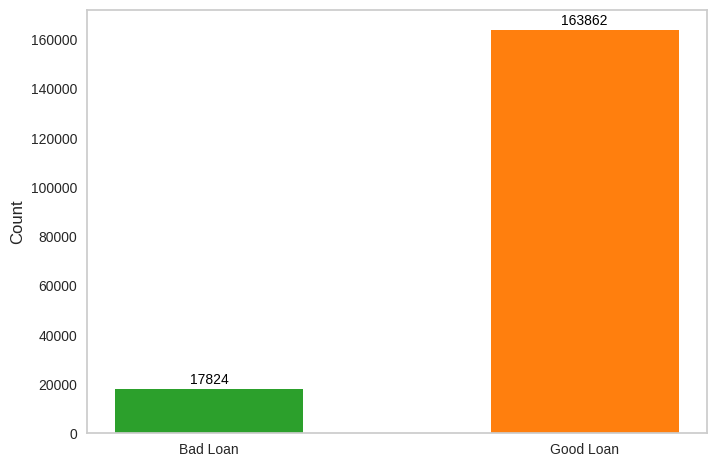

In [ ]:
# Mengganti palet warna dengan hijau dan oranye
set_palette(["#2ca02c", "#ff7f0e"])  # Warna hijau dan oranye

# Memisahkan fitur dan target
X = df_new.drop(columns='bad_loan', axis=1)
y = df_new['bad_loan']

# Visualisasi distribusi kelas
visualizer = ClassBalance()
visualizer.fit(y)

# Akses sumbu matplotlib dari visualizer
ax = visualizer.ax

# Menambahkan label angka di atas batang
for p in ax.patches:
    height = p.get_height()  # Tinggi batang
    ax.annotate(f'{int(height)}',  # Label angka
                (p.get_x() + p.get_width() / 2., height + 1000),  # Posisi teks sedikit di atas batang
                ha='center', va='bottom', fontsize=10, color='black')  # Properti teks

# Mengganti label y-axis
ax.set_ylabel('Count', fontsize=12)

# Menyusun label untuk sumbu x secara manual
ax.set_xticks([0, 1])  # Posisi untuk Bad Loan dan Good Loan
ax.set_xticklabels(['Bad Loan', 'Good Loan'], fontsize=10)

# Menghilangkan grid
ax.grid(False)

# Menampilkan diagram akhir
plt.show()

In [ ]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181686 entries, 0 to 181685
Data columns (total 89 columns):
 #   Column                                   Non-Null Count   Dtype
---  ------                                   --------------   -----
 0   grade:A                                  181686 non-null  int64
 1   grade:B                                  181686 non-null  int64
 2   grade:C                                  181686 non-null  int64
 3   grade:D                                  181686 non-null  int64
 4   grade:E                                  181686 non-null  int64
 5   grade:F                                  181686 non-null  int64
 6   home_ownership:OWN                       181686 non-null  int64
 7   home_ownership:MORTGAGE                  181686 non-null  int64
 8   verification_status:NOT_VERIFIED         181686 non-null  int64
 9   verification_status:SOURCE_VERIFIED      181686 non-null  int64
 10  purpose:OTHER_HOUSE_MEDICAL              181686 non-null

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
#checking  imbalance for training dataset
y_train.value_counts()

,count
bad_loan,
1,131164
0,14184


In [ ]:
# Oversampling dengan RandomOverSampler
smoten = SMOTEN(random_state=42)
X_train_o, y_train_o = smoten.fit_resample(X_train, y_train)
y_train_series = pd.Series(y_train_o)
print("Value counts after oversampling:")
print(y_train_series.value_counts())

# Fungsi untuk evaluasi model
def eval_classification(model):
    y_pred = model.predict(X_test)
    y_pred_train = model.predict(X_train_o)
    y_pred_proba = model.predict_proba(X_test)
    y_pred_proba_train = model.predict_proba(X_train_o)

    print("Accuracy (Test Set): %.2f" % accuracy_score(y_test, y_pred))
    print("Accuracy (Train Set): %.2f" % accuracy_score(y_train_o, y_pred_train))
    print("Precision (Test Set): %.2f" % precision_score(y_test, y_pred, zero_division=0))
    print("Precision (Train Set): %.2f" % precision_score(y_train_o, y_pred_train, zero_division=0))
    print("Recall (Test Set): %.2f" % recall_score(y_test, y_pred))
    print("Recall (Train Set): %.2f" % recall_score(y_train_o, y_pred_train))
    print("F1-Score (Test Set): %.2f" % f1_score(y_test, y_pred))
    print("F1-Score (Train Set): %.2f" % f1_score(y_train_o, y_pred_train))

    # Menampilkan nilai ROC-AUC
    print("ROC_AUC (Test Set): %.2f" % roc_auc_score(y_test, y_pred_proba[:, 1]))
    print("ROC_AUC (Train Set): %.2f" % roc_auc_score(y_train_o, y_pred_proba_train[:, 1]))

    # Cross-validation dengan skor ROC-AUC
    cv = RepeatedStratifiedKFold(random_state=42, n_repeats=3)
    score = cross_validate(model, X=X_train_o, y=y_train_o, cv=cv, scoring='roc_auc', return_train_score=True)
    print('ROC_AUC (crossval train): %.3f' % score['train_score'].mean())
    print('ROC_AUC (crossval test): %.3f' % score['test_score'].mean())

# Fungsi untuk Grid Search dengan Pipeline
def grid_pipe(pipedict, hyperdict, scoring='roc_auc', display=True):
    fitted_models = {}
    fit_time = []
    for name, pipeline in pipedict.items():
        # Construct grid search
        cv = RepeatedStratifiedKFold(random_state=42, n_repeats=3)
        model = GridSearchCV(estimator=pipeline,
                             param_grid=hyperdict[name],
                             scoring=scoring,
                             cv=cv, verbose=2, n_jobs=-1, return_train_score=True, error_score='raise')

        # Fit menggunakan grid search
        start = time.time()
        model.fit(X_train_o, y_train_o)
        end = time.time()
        fit_time.append(round(end - start, 2))
        # Menyimpan model yang sudah fit
        fitted_models[name] = model
        if display:
            # Menampilkan hasil setelah model terlatih
            print(f'The {name} model has been fitted.')
            print('Total Fit Time: %.3fs' % (end - start))
            print('Best roc_auc: %.3f' % model.best_score_)
            print('Best params:\n', model.best_params_, '\n')

    return fitted_models, fit_time

# Fungsi untuk evaluasi confusion matrix
def confusion(model):
    # Prediksi model
    y_pred_proba = model.predict_proba(X_test)
    y_predict = model.predict(X_test)

    # Evaluasi performa model
    print('Accuracy: %.2f%%' % (accuracy_score(y_test, y_predict) * 100))
    print('Precision (FP): %.2f%%' % (precision_score(y_test, y_predict, zero_division=0) * 100))
    print('Recall (FN): %.2f%%' % (recall_score(y_test, y_predict) * 100))
    print('F1_Score (FP&FN): %.2f%%' % (f1_score(y_test, y_predict) * 100))
    print('ROC_AUC: %.2f%%' % (roc_auc_score(y_test, y_pred_proba[:, 1]) * 100))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_predict)

    # Ekstrak nilai TP, FP, TN, FN dari confusion matrix
    TN, FP, FN, TP = cm.ravel()

    # Tampilkan nilai-nilai TP, FP, TN, FN
    print(f"True Positives (TP): {TP}")
    print(f"False Positives (FP): {FP}")
    print(f"True Negatives (TN): {TN}")
    print(f"False Negatives (FN): {FN}")

    # Visualisasi confusion matrix menggunakan heatmap
    plt.figure(figsize=(6, 4))
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, fmt='g', ax=ax, cmap='Blues')  # Menggunakan cmap untuk memperindah
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.set_title('Confusion Matrix')
    ax.xaxis.set_ticklabels(['0', '1'])
    ax.yaxis.set_ticklabels(['0', '1'])

Value counts after oversampling:
bad_loan
1    131164
0    131164
Name: count, dtype: int64


Model tersimpan di: /content/drive/MyDrive/IDX_DataScience/logreg1.pkl
File ada: True
Accuracy (Test Set): 0.88
Accuracy (Train Set): 0.93
Precision (Test Set): 0.92
Precision (Train Set): 0.92
Recall (Test Set): 0.94
Recall (Train Set): 0.94
F1-Score (Test Set): 0.93
F1-Score (Train Set): 0.93
ROC_AUC (Test Set): 0.79
ROC_AUC (Train Set): 0.97
ROC_AUC (crossval train): 0.973
ROC_AUC (crossval test): 0.973
Accuracy: 87.66%
Precision (FP): 92.44%
Recall (FN): 93.97%
F1_Score (FP&FN): 93.20%
ROC_AUC: 79.43%
True Positives (TP): 30725
False Positives (FP): 2512
True Negatives (TN): 1128
False Negatives (FN): 1973


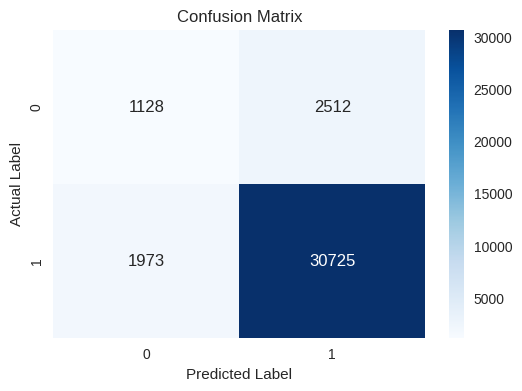

In [ ]:
# Melatih model logistic regression
logreg1 = LogisticRegression(random_state=42)
logreg1.fit(X_train_o, y_train_o)
# Simpan model
file_path = "/content/drive/MyDrive/IDX_DataScience/logreg1.pkl"
joblib.dump(logreg1, file_path)

# Cek apakah berhasil
print("Model tersimpan di:", os.path.abspath(file_path))
print("File ada:", os.path.exists(file_path))

# Evaluasi model menggunakan fungsi eval_classification
eval_classification(logreg1)


# Confusion matrix menggunakan fungsi confusion
confusion(logreg1)

Model tersimpan di: /content/drive/MyDrive/IDX_DataScience/rf1.pkl
File ada: True
Accuracy (Test Set): 0.91
Accuracy (Train Set): 1.00
Precision (Test Set): 0.92
Precision (Train Set): 1.00
Recall (Test Set): 0.99
Recall (Train Set): 1.00
F1-Score (Test Set): 0.95
F1-Score (Train Set): 1.00
ROC_AUC (Test Set): 0.83
ROC_AUC (Train Set): 1.00
ROC_AUC (crossval train): 1.000
ROC_AUC (crossval test): 0.982
Accuracy: 91.03%
Precision (FP): 91.63%
Recall (FN): 99.07%
F1_Score (FP&FN): 95.21%
ROC_AUC: 83.38%
True Positives (TP): 32395
False Positives (FP): 2958
True Negatives (TN): 682
False Negatives (FN): 303


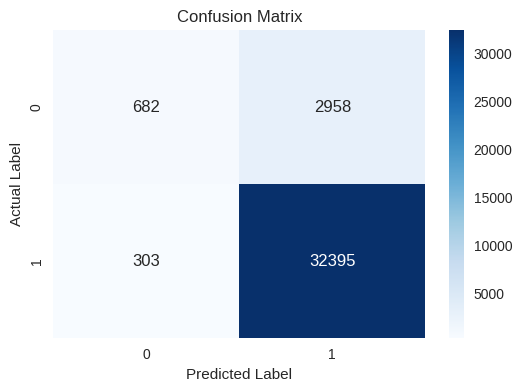

In [ ]:
rf1 = RandomForestClassifier(random_state=42)
rf1.fit(X_train_o, y_train_o)
# Simpan model
file_path = "/content/drive/MyDrive/IDX_DataScience/rf1.pkl"
joblib.dump(rf1, file_path)

# Cek apakah berhasil
print("Model tersimpan di:", os.path.abspath(file_path))
print("File ada:", os.path.exists(file_path))

eval_classification(rf1)

confusion(rf1)

Model tersimpan di: /content/drive/MyDrive/IDX_DataScience/bgc1.pkl
File ada: True
Accuracy (Test Set): 0.88
Accuracy (Train Set): 0.93
Precision (Test Set): 0.92
Precision (Train Set): 0.92
Recall (Test Set): 0.94
Recall (Train Set): 0.94
F1-Score (Test Set): 0.93
F1-Score (Train Set): 0.93
ROC_AUC (Test Set): 0.79
ROC_AUC (Train Set): 0.97
ROC_AUC (crossval train): 0.973
ROC_AUC (crossval test): 0.973
Accuracy: 87.67%
Precision (FP): 92.47%
Recall (FN): 93.95%
F1_Score (FP&FN): 93.21%
ROC_AUC: 79.44%
True Positives (TP): 30721
False Positives (FP): 2502
True Negatives (TN): 1138
False Negatives (FN): 1977


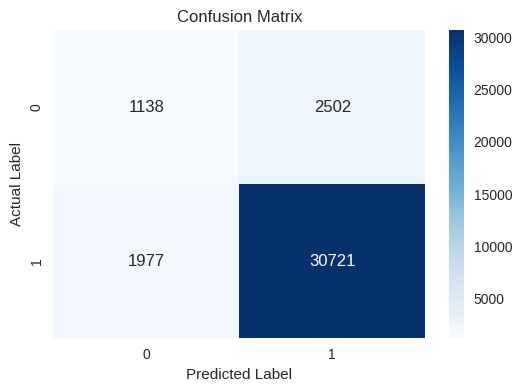

In [ ]:
bgc1 = BaggingClassifier(
    estimator=LogisticRegression(),
    n_estimators=10,
    random_state=42
)

bgc1.fit(X_train_o, y_train_o)

# Simpan model
file_path = "/content/drive/MyDrive/IDX_DataScience/bgc1.pkl"
joblib.dump(bgc1, file_path)

# Cek apakah berhasil
print("Model tersimpan di:", os.path.abspath(file_path))
print("File ada:", os.path.exists(file_path))

eval_classification(bgc1)

confusion(bgc1)

In [ ]:
#predicting
y_preds = logreg1.predict(X_test)
#classification report
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.36      0.31      0.33      3640
           1       0.92      0.94      0.93     32698

    accuracy                           0.88     36338
   macro avg       0.64      0.62      0.63     36338
weighted avg       0.87      0.88      0.87     36338



In [ ]:
y_hat_test_proba = logreg1.predict_proba(X_test)
y_hat_test_proba = y_hat_test_proba[:][: , 1]
y_test_temp = y_test.copy()
y_test_temp.reset_index(drop = True, inplace = True)
y_test_proba = pd.concat([y_test_temp, pd.DataFrame(y_hat_test_proba), pd.DataFrame(y_preds)], axis = 1)
y_test_proba.columns = ['y_test_class_actual', 'y_hat_test_proba', 'y_hat_test']
y_test_proba.index = X_test.index
y_test_proba.head()

,y_test_class_actual,y_hat_test_proba,y_hat_test
68813,1,0.987465,1
7403,1,0.981426,1
27709,1,0.837725,1
169179,1,0.979738,1
26044,1,0.750919,1


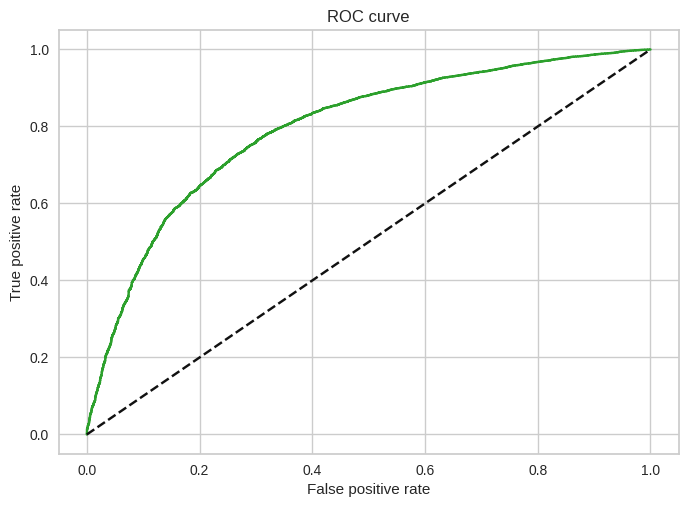

In [ ]:
# get the values required to plot a ROC curve
fpr, tpr, thresholds = roc_curve(y_test_proba['y_test_class_actual'], y_test_proba['y_hat_test_proba'])
# plot the ROC curve
plt.plot(fpr, tpr)
# plot a secondary diagonal line, to plot randomness of model
plt.plot(fpr, fpr, linestyle = '--', color = 'k')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve');

In [ ]:
# Prediksi probabilitas menggunakan model
y_pred_proba = logreg1.predict_proba(X_test)

# Cetak hasil probabilitas
print("Predicted probabilities (y_pred_proba):")
print(y_pred_proba[:10])  # Menampilkan 10 hasil pertama

Predicted probabilities (y_pred_proba):
[[0.01253501 0.98746499]
 [0.01857383 0.98142617]
 [0.16227492 0.83772508]
 [0.02026237 0.97973763]
 [0.24908108 0.75091892]
 [0.01963623 0.98036377]
 [0.05065202 0.94934798]
 [0.02807093 0.97192907]
 [0.28846756 0.71153244]
 [0.22347109 0.77652891]]


Area Under ROC Curve (AUROC): 0.7943


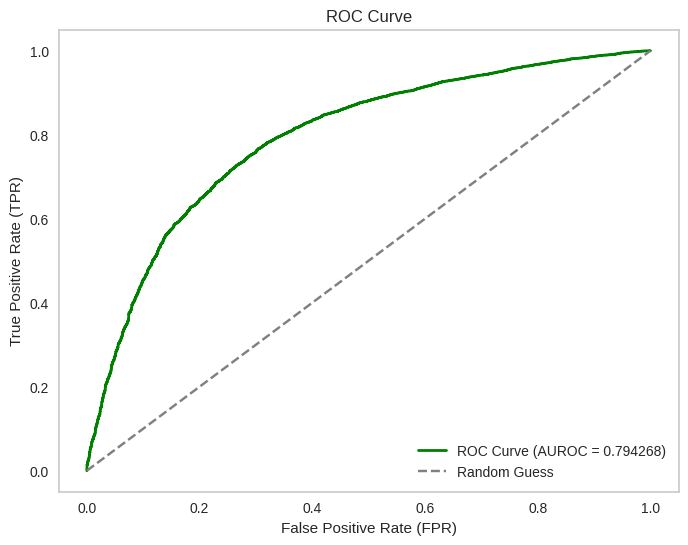

In [ ]:
# Pastikan model sudah dilatih
logreg1.fit(X_train_o, y_train_o)

# Membuat DataFrame untuk menyimpan nilai aktual dan probabilitas prediksi
y_test_proba = pd.DataFrame({
    'y_test_class_actual': y_test,  # Nilai aktual (label sebenarnya)
    'y_hat_test_proba': logreg1.predict_proba(X_test)[:, 1]  # Probabilitas prediksi untuk kelas positif
})

# Menghitung AUROC
AUROC = roc_auc_score(y_test_proba['y_test_class_actual'], y_test_proba['y_hat_test_proba'])
print(f"Area Under ROC Curve (AUROC): {AUROC:.4f}")

# Plot kurva ROC
fpr, tpr, thresholds = roc_curve(y_test_proba['y_test_class_actual'], y_test_proba['y_hat_test_proba'])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUROC = {AUROC:.6f})', color='green', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

**Gini**



In [ ]:
# Menghitung ROC-AUC
y_pred_proba = logreg1.predict_proba(X_test)  # Dapatkan probabilitas prediksi dari model
roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])  # Menggunakan probabilitas kelas positif

# Menghitung Gini
gini = (roc_auc * 2) - 1

# Menampilkan hasil
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"Gini: {gini:.6f}")

ROC-AUC: 0.794268
Gini: 0.588537


Interpretasi: Nilai 0.7 berarti model memiliki kemampuan yang cukup baik dalam membedakan antara bad loan dan good loan. Nilai ROC-AUC yang mendekati 1 (lebih dari 0.78) menunjukkan bahwa model memiliki performa yang sangat baik dalam prediksi. Dengan nilai 0.78, model dapat dengan tepat mengidentifikasi kemungkinan terjadinya bad loan pada sebagian besar kasus, memberikan indikasi bahwa model tersebut cukup andal dalam memprediksi risiko default. Gini Coefficient ( mendekati 0.57):

Definisi: Gini Coefficient adalah metrik yang berhubungan erat dengan ROC-AUC, mengukur ketidaksetaraan dalam distribusi probabilitas model. Nilai Gini dihitung sebagai dua kali area di bawah kurva ROC, dikurangi 1: 0 berarti model tidak dapat membedakan antara kelas positif dan negatif (sama dengan ROC-AUC 0.5). 1 berarti model sempurna dalam membedakan kedua kelas. Interpretasi: Nilai 0.57 menunjukkan bahwa model memiliki kemampuan pemisahan yang sangat baik antara kelas positif dan negatif. Kesimpulan: Dengan ROC-AUC sebesar 0.78, model Anda memiliki kemampuan yang sangat baik dalam memisahkan bad loan dan good loan. Nilai Gini sebesar 0.57 lebih lanjut memperkuat temuan tersebut, menunjukkan bahwa model Anda sangat efektif dalam memprediksi probabilitas terjadinya bad loan dan meminimalkan kesalahan prediksi.

In [ ]:
# Ambil probabilitas kelas positif (kelas 1)
y_pred_proba = logreg1.predict_proba(X_test)[:, 1]

# Pisahkan probabilitas berdasarkan kelas asli (0 atau 1)
y_pred_1 = y_pred_proba[y_test == 1]  # Probabilitas untuk kelas 1 (positif)
y_pred_0 = y_pred_proba[y_test == 0]  # Probabilitas untuk kelas 0 (negatif)

# Hitung Kolmogorov-Smirnov Statistic
ks_statistic, p_value = ks_2samp(y_pred_1, y_pred_0)

# Menampilkan hasil KS Statistic dan p-value
print(f"Kolmogorov-Smirnov Statistic: {ks_statistic:.6f}")
print(f"P-value: {p_value:.12f}")

Kolmogorov-Smirnov Statistic: 0.462592
P-value: 0.000000000000


Interpretasi: Nilai KS = 0.44 menunjukkan bahwa model dapat memisahkan kelas positif (bad loan) dan negatif (good loan) dengan cukup baik. Biasanya, nilai KS lebih dari 0.3 dianggap cukup baik, sementara nilai yang lebih tinggi menunjukkan performa model yang lebih baik dalam membedakan antara kelas yang berbeda. Nilai 0.44 ini menunjukkan bahwa model Anda memiliki kemampuan yang signifikan untuk membedakan antara bad loan dan good loan, dengan perbedaan yang cukup besar antara distribusi kelas. P-value (0.000000):

Definisi: P-value digunakan untuk mengukur signifikansi statistik dari uji hipotesis yang dilakukan. Dalam hal ini, P-value digunakan untuk menguji apakah perbedaan distribusi kumulatif antara kelas yang diprediksi dan kelas aktual signifikan. P-value rendah (biasanya di bawah 0.05 atau 0.01) menunjukkan bahwa perbedaan distribusi antara kelas positif dan negatif adalah signifikan secara statistik, artinya model Anda memang mampu membedakan antara kedua kelas. Interpretasi: P-value sebesar 0.000000 menunjukkan bahwa perbedaan distribusi antara bad loan dan good loan sangat signifikan. Ini berarti model Anda tidak hanya membedakan kedua kelas dengan baik, tetapi perbedaan tersebut tidak terjadi secara kebetulan atau karena faktor acak. Kesimpulan: Kolmogorov-Smirnov Statistic sebesar 0.44 menunjukkan bahwa model memiliki kemampuan yang baik untuk membedakan antara bad loan dan good loan, dengan perbedaan yang cukup signifikan. P-value yang sangat kecil (0.000000) mengindikasikan bahwa perbedaan antara distribusi kelas yang diprediksi dan distribusi aktual sangat signifikan, mengonfirmasi bahwa model Anda bekerja dengan baik dan tidak hanya memberikan hasil yang terjadi karena kebetulan.

**Precision & Recall**

Accuracy: 0.8766
Precision: 0.9244
Recall: 0.9397
F1 Score: 0.9320


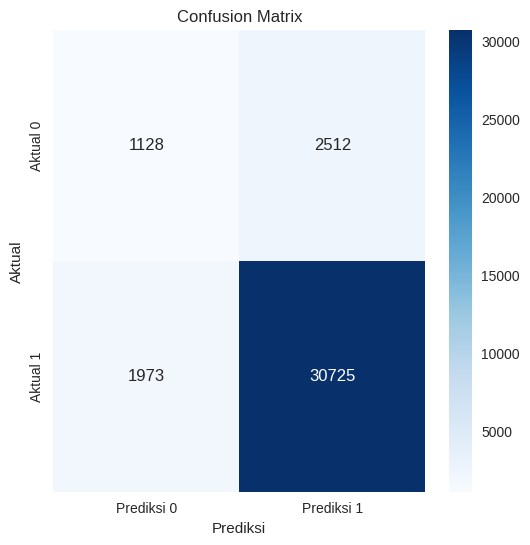

In [ ]:
# Tentukan threshold (misalnya 0.5)
threshold = 0.5

# Menghitung prediksi kelas berdasarkan threshold (y_pred_proba sudah berupa probabilitas untuk kelas 1)
y_pred_class = (y_pred_proba >= threshold).astype(int)

# Hitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)

# Menghitung metrik-metrik lainnya
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
f1 = f1_score(y_test, y_pred_class)

# Menampilkan hasil metrik
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

# Visualisasi Confusion Matrix menggunakan heatmap
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Prediksi 0', 'Prediksi 1'], yticklabels=['Aktual 0', 'Aktual 1'])
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

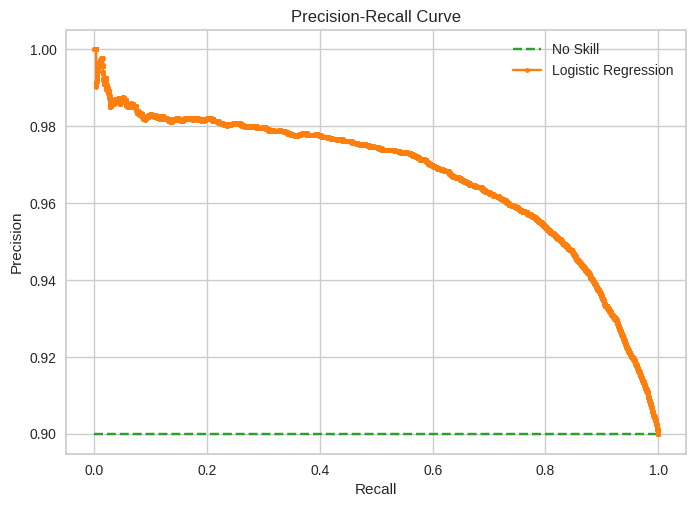

In [ ]:
# Menghitung garis no-skill sebagai proporsi kelas positif
no_skill = len(y_test[y_test == 1]) / len(y_test)

# Plot garis no-skill pada PR Curve
plt.plot([0, 1], [no_skill, no_skill], linestyle='--', label='No Skill')

# Menghitung precision, recall, dan thresholds untuk PR curve
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Plot PR curve
plt.plot(recall, precision, marker='.', label='Logistic Regression')

# Menambahkan label dan judul
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.title('Precision-Recall Curve')

# Menampilkan plot
plt.show()

Grafik di atas adalah Precision-Recall Curve (PR Curve) yang menggambarkan performa model prediksi berdasarkan recall (sensitivitas) dan precision pada berbagai threshold probabilitas.

Interpretasi Grafik: Garis Hijau (No Skill):

Garis horizontal hijau mewakili no-skill line, yang merupakan kinerja dari model yang hanya menebak berdasarkan proporsi kelas positif (di sini sekitar 0.90, artinya sekitar 90% dari data adalah kelas positif). Ini menunjukkan kinerja yang tidak lebih baik dari tebakan acak. Kurva Orange (Logistic Regression):

Precision dimulai sangat tinggi di sebelah kiri (untuk recall yang sangat rendah) dan kemudian menurun seiring dengan peningkatan recall. Pada recall rendah (yaitu ketika kita tidak banyak memprediksi positif), precision tetap sangat tinggi. Hal ini menunjukkan bahwa model sangat selektif dalam memprediksi kelas positif, sehingga hampir semua prediksi positif adalah benar (high precision). Namun, ketika recall meningkat (model mulai memprediksi lebih banyak kelas positif), precision mulai turun. Ini adalah trade-off alami antara precision dan recall: semakin banyak prediksi positif yang dibuat, semakin banyak prediksi yang mungkin salah, menurunkan precision. Celah Tajam:

Terlihat adanya penurunan tajam di bagian akhir grafik. Hal ini menunjukkan bahwa setelah titik tertentu, model lebih cenderung memprediksi semua data sebagai kelas positif, yang menyebabkan penurunan tajam dalam precision. Perbandingan Kinerja:

Logistic Regression (kurva orange) jauh di atas garis no skill (hijau) sepanjang grafik, yang menunjukkan bahwa model tersebut bekerja lebih baik daripada model tebak-tebakan acak pada semua threshold. Kesimpulan: Model Logistic Regression memiliki kinerja yang sangat baik dalam hal precision dan recall, terutama di bagian awal kurva, namun ada trade-off saat recall meningkat. Semakin besar nilai recall yang dicapai, semakin rendah precision-nya, namun model tetap lebih baik daripada model tanpa keterampilan (no skill) pada setiap threshold. Jika Anda ingin mengevaluasi lebih lanjut kinerja model ini, Anda bisa menggunakan AUC (Area Under Curve) untuk mendapatkan ukuran yang lebih komprehensif tentang kualitas model pada berbagai threshold.

In [ ]:
#precision recall score
auc_pr = auc(recall, precision)
auc_pr

np.float64(0.9668673328483041)

In [ ]:
# Membagi data menjadi train-test split (jika belum dilakukan)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standarisasi data menggunakan scaler yang sama dengan data training
scaler = StandardScaler()
X_train_o = scaler.fit_transform(X_train)  # Data training yang sudah distandarisasi
X_test_o = scaler.transform(X_test)       # Data test yang distandarisasi

# Tetapkan y_test_o sebagai target dari data test
y_test_o = y_test

In [ ]:
# Fungsi evaluasi model
def eval_classification(model, X_test, y_test):
    # Prediksi pada data test
    y_pred = model.predict(X_test)

    # Menghitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Menampilkan hasil evaluasi
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

In [ ]:
# Melakukan evaluasi pada data test
eval_classification(logreg1, X_test_o, y_test_o)

Accuracy: 0.2720
Precision: 0.9670
Recall: 0.1981
F1-Score: 0.3288


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
# Prediksi pada data test
y_pred = logreg1.predict(X_test_o)

# Menampilkan hasil evaluasi dengan classification report
print(classification_report(y_test_o, y_pred))

              precision    recall  f1-score   support

           0       0.11      0.94      0.20      3623
           1       0.97      0.20      0.33     32715

    accuracy                           0.27     36338
   macro avg       0.54      0.57      0.27     36338
weighted avg       0.88      0.27      0.32     36338



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
# 1. Prediksi probabilitas
y_proba = logreg1.predict_proba(X_test_o)[:, 1]  # Probabilitas untuk kelas positif (bad loan)

# 2. Tentukan threshold (misalnya, 0.5)
threshold = 0.5
y_pred_class = (y_proba >= threshold).astype(int)

# 3. Buat confusion matrix
cm = confusion_matrix(y_test_o, y_pred_class)
tn, fp, fn, tp = cm.ravel()

# 4. Hitung metrik:
# Total pinjaman
total_loans = len(y_test_o)

# Persentase pinjaman baik dan berisiko
good_loans_percentage = (tn + fn) / total_loans * 100
bad_loans_percentage = (tp + fp) / total_loans * 100

# Persentase investasi pada pinjaman baik yang tersedia
invest_good_loans = tn / (tn + fn) * 100

# Rasio pinjaman berisiko yang dihindari terhadap pinjaman baik yang dihindari
bad_loans_avoided = tp
good_loans_avoided = fp
risk_to_good_ratio = bad_loans_avoided / (bad_loans_avoided + good_loans_avoided) * 100

# 5. Cetak hasil
print(f"Portofolio kita terdiri dari {good_loans_percentage:.2f}% pinjaman baik : {bad_loans_percentage:.2f}% pinjaman berisiko.")
print(f"Kita akan berinvestasi dalam {invest_good_loans:.2f}% dari pinjaman baik yang tersedia.")
print(f"Untuk setiap 100 pinjaman yang dihindari, {risk_to_good_ratio:.2f}% di antaranya adalah pinjaman berisiko.")

Portofolio kita terdiri dari 81.56% pinjaman baik : 18.44% pinjaman berisiko.
Kita akan berinvestasi dalam 11.48% dari pinjaman baik yang tersedia.
Untuk setiap 100 pinjaman yang dihindari, 96.70% di antaranya adalah pinjaman berisiko.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
# Memastikan koefisien berada dalam bentuk 1 dimensi
coefficients = logreg1.coef_.flatten()

# Ambil nama fitur dari DataFrame X_train (gunakan X_test jika menggunakan data uji)
feature_names = X_train.columns  # Jika X_train adalah DataFrame

# Pastikan panjang fitur dan koefisien cocok
print("Jumlah fitur:", len(feature_names))
print("Jumlah koefisien:", len(coefficients))

# Buat DataFrame untuk menampilkan koefisien
feature_importance = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()

# Urutkan berdasarkan nilai koefisien absolut untuk melihat fitur yang paling penting
feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

print(feature_importance)

Jumlah fitur: 88
Jumlah koefisien: 88
                                    Feature  Coefficient  Abs_Coefficient
40                       total_pymnt:>22000     5.406160         5.406160
39                  total_pymnt:16000-22000     3.889177         3.889177
25                   addr_state:NH_WV_WY_DC     3.209597         3.209597
23                         addr_state:CO_SC     3.122445         3.122445
20                         addr_state:WI_OR     2.995046         2.995046
24                   addr_state:KS_VT_AK_NS     2.991294         2.991294
30                      total_rec_int:>9000    -2.925389         2.925389
19                         addr_state:GA_WA     2.922532         2.922532
38                  total_pymnt:11000-16000     2.912822         2.912822
21                            addr_state:TX     2.868404         2.868404
17             addr_state:AZ_MI_UT_TN_AR_PA     2.815981         2.815981
22                      addr_state:IL_CT_MT     2.797089         2.797089
